## Factory Sensor Data Analysis Project

### Factory Sensor Data Quality & Exploratory Analysis

### 1. Project Introduction

This project assesses the quality of factory sensor data, identifies data issues, and analyzes measurement patterns across devices and sites.

The study uses synthetic data for training. It includes temperature, humidity, vibration, and rotational speed measurements, together with device identifiers, sites, recording times, and operating-status labels.

### 2. Project Questions

#### Main question:

How good is the factory sensor data, and what measurement patterns emerge across devices, sites, and the recording period?

#### Supporting questions:

1. What data-quality issues exist, and how extensive are they?
2. How are measurements distributed across devices and sites?
3. How do outliers vary by device, site, and operating status?
4. What temporal trends and gaps are present?
5. What treatments are appropriate, and which findings need further review?

### 3. Data Source

Synthetic factory sensor data was used for training and analysis.

#### Dataset source:

[Datanemics — Factory Sensor Telemetry](https://datanemics.com/datasets/sensor-telemetry/)

- `original_data.csv` — the original dataset, containing 8,000 records
- `raw_data.csv` — the working copy used for auditing, containing 8,020 records after data-quality issues were introduced for training

The original data was preserved without modification.

#### Datasets in this notebook:

- `df` — raw data used for the quality audit
- `df_analysis` — analytical data after excluding duplicate records

### 4. Methodology

The workflow examines missing values, duplicates, data types, categorical consistency, and temporal gaps. It also includes descriptive statistics, outlier detection, correlation and temporal-trend analysis, and chart creation and interpretation.

Findings are documented in a data-quality log. Cleaning and validation are handled in a separate notebook.

#### Project scope:

Data auditing, cleaning, and descriptive and exploratory analysis, without training a failure-prediction model.

### 5. Future Development

The cleaned data may support future machine-learning and predictive-maintenance applications. This would require reliable failure records and timestamps, verification of the source of operating-status labels, and prevention of information leakage during data preparation and model training.

#### Methodological note:

Failure prediction is a future objective, not an outcome achieved in this project.


In [89]:
import pandas as pd
import numpy as np

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.1.0
NumPy: 2.5.4


In [90]:

from pathlib import Path

notebooks_dir = Path.cwd()
raw_file = Path("../data/raw_data.csv")

print("Notebook directory:", notebooks_dir.name)
print("Raw data file found:", raw_file.is_file())

assert notebooks_dir.name == "notebooks", (
    "Working directory must be notebooks"
)

assert raw_file.is_file(), (
    "Cannot find ../data/raw_data.csv"
)


Notebook directory: notebooks
Raw data file found: True


In [91]:
df = pd.read_csv("../data/raw_data.csv")

### Preparing Data for Descriptive Analysis

An independent copy of the raw data is created for exploratory checks and analysis. This prevents fully duplicated records from influencing statistical calculations while retaining the raw data unchanged for quality auditing.

### Procedure:

The raw data was loaded into a separate variable without modifying its contents. A new analytical dataset was created by excluding fully identical rows. A copy operation ensured that the analytical dataset was separate from the raw data. Finally, both datasets' dimensions were checked and the analytical dataset was verified to contain no exact duplicates.

### Datasets:

| Variable | Description |
|---|---|
| `df` | Raw data used for quality checks |
| `df_analysis` | Analytical copy after excluding fully duplicated records |

### Programming elements:

| Element | Purpose |
|---|---|
| `drop_duplicates()` | Exclude fully identical rows |
| `keep="first"` | Retain the first occurrence of each record |
| `copy()` | Create an independent data copy |
| `shape` | Display row and column counts |
| `duplicated().sum()` | Count remaining duplicates |

### Preparation results:

| Metric | Result |
|---|---:|
| Raw records | 8,020 |
| Analytical records | 8,000 |
| Duplicate records excluded | 20 |
| Remaining duplicates | 0 |

### Methodological note:

Exploratory analyses in this notebook use a copy of the raw data with fully duplicated records removed. This step does not mean that cleaning is complete or that all treatments in the cleaning notebook have been applied.

### Data sources used:

| Source | Use |
|---|---|
| `df_analysis` | Exploratory-analysis dataset after excluding exact duplicates |
| `cleaned_data.csv` | Output of formal cleaning and validation |

An additional test in the cleaning notebook checks the equivalence of a temporary dataset reconstructed from the raw data and the saved cleaned dataset. After the required formatting conversions, records and values matched within the specified comparison conditions.

However, this successful check does not mean that analyses in this notebook directly used the cleaned file. Formal cleaning and validation are performed independently in:

`02_data_cleaning_validation.ipynb`

Neither the raw data nor the original file was modified in this step.


In [92]:

# Create a duplicate-free dataset for descriptive analysis
df_analysis = df.drop_duplicates(keep="first").copy()

print("Raw data shape:", df.shape)
print("Analysis data shape:", df_analysis.shape)
print("Duplicates in analysis data:", df_analysis.duplicated().sum())


Raw data shape: (8020, 8)
Analysis data shape: (8000, 8)
Duplicates in analysis data: 0


### Verifying the Integrity of the Analytical Copy

This step checks that creating the analytical copy did not affect the raw data. It verifies the separate analytical object and the correctness of exact-duplicate exclusion.

### Procedure:

The saved raw file was read again and compared with the in-memory data. The analytical object was then checked to be distinct from the raw-data variable, compared with the expected deduplicated result, and inspected for remaining duplicates.

### Variables:

| Variable | Description |
|---|---|
| `df` | Raw data loaded in memory |
| `raw_reference` | Reference copy read from the raw file |
| `df_analysis` | Dataset used for exploratory analysis |

### Programming elements:

| Element | Purpose |
|---|---|
| `pd.read_csv()` | Read the raw data for comparison |
| `equals()` | Compare data values and structure |
| `is not` | Verify different object identities |
| `drop_duplicates()` | Calculate the expected deduplicated result |
| `duplicated().sum()` | Count remaining duplicates |

### Expected results:

| Test | Result |
|---|---|
| Raw data matches the reference file | `True` |
| Analytical copy is a separate object | `True` |
| Analytical copy matches the expected result | `True` |
| Remaining duplicates | `0` |

### Methodological note:

The comparison uses the current raw file saved as the reference. The first test confirms agreement between the in-memory data and the file read at test time; it does not prove that the file had never changed before the test.

The second test confirms different object identities, but alone does not prove independence of all underlying memory. The analytical copy was previously created using the independent-copy operation `copy()`.

This step neither modifies the data nor performs additional cleaning.


In [93]:

# Verify the analysis DataFrame and current raw CSV
raw_reference = pd.read_csv("../data/raw_data.csv")

print("Raw data matches saved CSV:", df.equals(raw_reference))
print("Separate DataFrame object:", df_analysis is not df)
print("Analysis matches expected:", df_analysis.equals(df.drop_duplicates(keep="first")))
print("Remaining duplicates:", df_analysis.duplicated().sum())


Raw data matches saved CSV: True
Separate DataFrame object: True
Analysis matches expected: True
Remaining duplicates: 0


### Checking Equivalence Between Analytical and Cleaned Data

This check verifies agreement between the data used for analysis and the data saved after cleaning.

### Verification procedure:

An independent copy of the analytical data was created and its key columns were standardized. Dates were converted to a datetime type, and categorical and numeric formats were normalized.

The saved `cleaned_data.csv` file was then read. Record keys, comprising reading timestamp and device identifier, were checked for duplicates. Both datasets were sorted, and all columns and records were compared using `pd.testing.assert_frame_equal()`.

### Verification results:

| Metric | Result |
|---|---|
| Records compared | 8,000 |
| Column names and order match | `True` |
| Dataset contents match | `PASSED` |

### Interpretation:

After standardizing formats and sorting records, analytical data matched the saved cleaned data. The check covers all columns and readings, not just row counts.

### Methodological note:

Differences in programmatic data types and a small numerical tolerance were allowed. Passing therefore establishes content equivalence under the specified validation conditions. It does not mean that the analytical workflow directly reads the cleaned file as its source.

Original files and measurement values were not modified by this check.


In [94]:

# Compare analytical data with the saved cleaned dataset
analysis_for_check = df_analysis.copy()

analysis_for_check["reading_at"] = pd.to_datetime(
    analysis_for_check["reading_at"],
    errors="raise"
)

for col in ["site", "status"]:
    analysis_for_check[col] = (
        analysis_for_check[col]
        .astype("string")
        .str.strip()
        .str.upper()
    )

analysis_for_check["rpm"] = pd.to_numeric(
    analysis_for_check["rpm"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="raise"
).astype("Float64")

saved_cleaned = pd.read_csv(
    "../data/cleaned_data.csv",
    parse_dates=["reading_at"],
    dtype={
        "site": "string",
        "status": "string",
        "rpm": "Float64"
    }
)

keys = ["reading_at", "device_id"]

assert not analysis_for_check.duplicated(keys).any()
assert not saved_cleaned.duplicated(keys).any()

left = analysis_for_check.sort_values(
    keys
).reset_index(drop=True)

right = saved_cleaned.sort_values(
    keys
).reset_index(drop=True)

pd.testing.assert_frame_equal(
    left,
    right,
    check_dtype=False,
    check_exact=False,
    rtol=1e-12,
    atol=1e-12
)

print("Rows compared:", len(left))
print(
    "Columns match:",
    left.columns.tolist() == right.columns.tolist()
)
print("Analysis vs cleaned: PASSED")


Rows compared: 8000
Columns match: True
Analysis vs cleaned: PASSED


## Checking Dataset Size

The dimensions of the raw dataset were checked to determine its row and column counts before quality checks and exploratory analysis.

### Procedure:

The raw dataset was used as loaded, without modification. Its row and column counts were extracted and reviewed to establish its basic dimensions before examining the details.

### Programming property:

- `shape` — returns the dataset's row and column counts

### Results:

| Metric | Result |
|---|---:|
| Rows | 8,020 |
| Columns | 8 |

### Interpretation:

The raw dataset contains recorded sensor readings. Each row represents one reading record. Columns describe recording information, device identifier, site, operational measurements, and the recorded operating status.

### Methodological note:

Dimensions were calculated before excluding duplicates or cleaning. The row count represents the initial dataset size and does not imply that every record is unique. Dimensions alone cannot establish data quality or completeness.

No records were removed and the original data was not modified.


In [95]:
df.shape

(8020, 8)

## Inspecting Data Structure and Column Types

The internal structure of the raw dataset was inspected to identify column types and value completeness before analysis.

### Procedure:

The unmodified raw dataset was used. Basic structural and data-type information was displayed. Non-missing counts in each column were compared with the total row count. Data types were also reviewed to identify columns that might require conversion during later cleaning.

### Information displayed:

- Dataset column names
- Data type stored in each column
- Non-missing value count per column
- Total row and column counts
- Approximate memory usage

### Programming elements:

- `info()` — displays structure, column types, non-missing counts, and memory usage

### Why this check matters:

It identifies data types and their suitability for analytical operations. Comparing non-missing counts with total rows reveals incomplete columns and highlights columns needing further review before cleaning.

### Methodological note:

The check reports types as stored in the raw dataset. It does not prove that all values conform to the type required for analysis. A non-missing value count also does not guarantee that those values are valid. Further formatting and validity checks may therefore be necessary.

Column types and original data were not modified.


In [96]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8020 entries, 0 to 8019
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   reading_at      8020 non-null   str    
 1   device_id       8020 non-null   str    
 2   site            8020 non-null   str    
 3   temp_c          8010 non-null   float64
 4   humidity_pct    8010 non-null   float64
 5   vibration_mm_s  8010 non-null   float64
 6   rpm             8010 non-null   str    
 7   status          8020 non-null   str    
dtypes: float64(3), str(5)
memory usage: 501.4 KB


## Checking Missing Values by Column

All columns were examined to count missing values, identify incomplete columns, and quantify missingness before cleaning.

### Procedure:

Missing cells were identified in the raw data and counted independently for each column. Affected columns and total missing cells were determined, then reviewed to identify columns requiring later consideration.

### Columns containing missing values:

- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurement
- `rpm` — device rotational speed

### Programming elements:

- `isna()` — identify cells containing missing values
- `sum()` — count missing values per column

### Results:

| Column | Missing values |
|---|---:|
| `temp_c` | 10 |
| `humidity_pct` | 10 |
| `vibration_mm_s` | 10 |
| `rpm` | 10 |
| **Total** | **40** |

No missing values appeared in the other columns.

### Summary:

| Metric | Result |
|---|---:|
| Columns containing missing values | 4 |
| Total missing cells | 40 |
| Missing values per affected column | 10 |

### Interpretation:

Missing values occur in all four numeric measurement columns, with equal counts in each. The other columns have no missing values. This identifies columns requiring review during cleaning and provides a basis for later analyses of missingness by site and device.

### Methodological note:

The total represents missing cells, not necessarily affected records. Equal missing-value counts do not mean the missing values occur in the same rows. The check used raw data, including duplicate records.

No records were removed, no missing values were imputed, and the original data was not modified.


In [97]:
df.isna().sum()

reading_at         0
device_id          0
site               0
temp_c            10
humidity_pct      10
vibration_mm_s    10
rpm               10
status             0
dtype: int64

### Calculating Total Missing Values

This step calculates a single count representing all missing cells across the dataset.

### Procedure:

Missing values were identified in all columns, counted separately within each column, and then summed to obtain the overall total.

### Programming elements:

- `isna()` — identify missing values
- First `sum()` — count missing values in each column
- Second `sum()` — add the column counts to obtain the total

### Result:

| Metric | Result |
|---|---:|
| Total missing cells | 40 |

### Interpretation:

The check confirms forty missing cells in the raw dataset, consistent with the sum from the preceding column-level check.

### Methodological note:

This is a count of missing cells, not necessarily affected records. The raw data, including duplicates, was used. Missing values were not imputed and the original data was not modified.


In [98]:
df.isna().sum().sum()

np.int64(40)

### Checking Fully Duplicated Rows

The raw dataset was inspected for fully identical rows to quantify duplicate records before deciding how to treat them.

### Procedure:

All columns in each raw-data row were compared. Fully identical rows were flagged, counting each repeated occurrence after the first, and these flags were summed.

### Programming elements:

- `duplicated()` — identify fully duplicated rows after their first occurrence
- `sum()` — count all duplicate rows

### Result:

| Metric | Result |
|---|---:|
| Fully duplicated rows | 20 |

### Interpretation:

Twenty rows match earlier records in every compared column. Repetition of a device identifier or recording time alone does not necessarily make a row fully duplicated. Quality review must distinguish whole-record duplication from repeated individual fields.

### Methodological note:

The check requires agreement across all row columns and excludes the first occurrence from the duplicate count. Finding an exact duplicate does not automatically justify deletion without considering the data context.

Duplicates were identified only for quality assessment. No records were deleted and the original data was not modified.


In [99]:
df.duplicated().sum()

np.int64(20)

## Examining the Distribution of Sites

Records were counted by the site labels stored in the raw data to identify site frequencies and inconsistencies in label formatting.

### Procedure:

The raw data, including duplicates, was used. Occurrences of each value in the site column were counted without prior normalization. The resulting categories were reviewed for main sites and writing variations, including extra whitespace and letter-case differences.

### Column:

- `site` — site recorded for each reading

### Programming elements:

- `value_counts()` — count occurrences of each site-column value
- `dropna=False` — include missing values in counts if present

### Results:

| Category | Records |
|---|---:|
| `NOR` | 2,830 |
| `SLT` | 2,826 |
| `RIV` | 2,352 |
| Formatting variants | 12 |
| **Total** | **8,020** |

### Interpretation:

Three main sites are present, with twelve raw records using alternative label formats. These differences can split readings from the same site into separate groups. Site names should therefore be standardized before site-level comparisons and analyses.

### Key findings:

- Three main sites are present.
- The first site in the table has the largest count for its displayed label.
- Site-label formatting variations were identified.
- Such variations can affect aggregation and comparison.
- The site column requires category normalization during cleaning.

### Methodological note:

Counts reflect raw labels before normalization. The twelve formatting variants do not necessarily represent an additional site. Counts assigned to each site may change after normalization. Unequal site counts alone do not establish missing recordings.

Site labels were not modified and records were not removed.


In [100]:
df["site"].value_counts(dropna=False)

site
NOR      2830
SLT      2826
RIV      2352
riv         3
 RIV        3
Riv         2
nor         1
slt         1
 NOR        1
 SLT        1
Name: count, dtype: int64

## Examining the Distribution of Operating Status

Records were counted by the operating-status labels stored in the raw dataset to identify category frequencies and formatting inconsistencies.

### Procedure:

The raw data, including duplicates, was used. Each status value was counted without prior normalization. Categories were reviewed to identify the main statuses and formatting variants, including extra whitespace and letter-case differences.

### Column:

- `status` — recorded operating status for each reading

### Programming elements:

- `value_counts()` — count occurrences of each category
- `dropna=False` — include missing values in the counts if present

### Results:

| Category | Operating status | Records |
|---|---|---:|
| `ok` | Normal operation | 7,400 |
| `warn` | Warning | 484 |
| `fault` | Fault label | 124 |
| Formatting variants | Category-label variations | 12 |
| **Total** | | **8,020** |

### Interpretation:

Most records carry the normal-operation label. Warning is the next most frequent main category, while the fault label has the smallest count. Some labels contain extra whitespace or letter-case variations. These can cause the same operating status to be counted under several categories during aggregation and analysis.

### Key findings:

- Normal operation accounts for the largest share of records.
- Warning and fault labels occur less frequently.
- Twelve records use alternative label formats.
- Formatting differences are not additional operating statuses.
- Status categories require normalization before subsequent analyses.

### Methodological note:

Counts reflect raw labels before normalization. The twelve variants are formatting differences, not an independent fourth status. Counts assigned to individual statuses may change after normalization. The distribution of recorded statuses alone does not establish actual mechanical faults.

Status labels were not modified and records were not removed.


In [101]:
df["status"].value_counts(dropna=False)

status
ok       7400
warn      484
fault     124
 Ok         4
OK          4
ok          4
Name: count, dtype: int64

## Checking Non-convertible Values in the Rotational-Speed Column

The raw rotational-speed values were examined. The preceding type check showed that the column is stored as text despite containing numerical measurements. This check identifies values that cannot be converted directly to numbers and investigates the apparent cause.

### Procedure:

The `rpm` column was used as stored in the raw data. A temporary numeric conversion was attempted. Failed conversions were identified, excluding values that were already missing so they would not be counted as conversion errors. Affected records and distinct non-convertible text values were then counted.

### Column:

- `rpm` — device rotational speed

### Programming elements:

- `pd.to_numeric()` — attempt to convert text values to numbers
- `errors="coerce"` — temporarily represent conversion failures as missing values
- `notna()` — exclude originally missing values from conversion-error checks
- `isna()` — identify failed conversions
- `value_counts()` — count occurrences of non-convertible text values

### Results:

| Metric | Result |
|---|---:|
| Records failing direct conversion | 12 |
| Distinct non-convertible text values | 11 |

### Apparent cause:

The affected values contain commas used as thousands separators. These commas prevent direct numeric conversion in their current text format.

### Interpretation:

Twelve records contain values that fail direct conversion, representing eleven distinct strings. This indicates formatting inconsistencies that must be addressed before numerical calculations. Failed direct conversion does not necessarily mean that the measurements themselves are incorrect.

### Key findings:

- Some text values cannot be converted directly to numbers.
- Thousands separators appear in the affected values.
- Affected-record counts differ from distinct-string counts.
- The column format needs normalization before numerical analysis.

### Methodological note:

Conversion was attempted solely for quality assessment. Missing values produced by conversion failures are not originally missing values. Thousands separators are a text-formatting issue and do not prove a measurement error.

The original rotational-speed column was not modified and affected records were not removed.


In [102]:
df.loc[
    df["rpm"].notna() &
    pd.to_numeric(df["rpm"], errors="coerce").isna(),
    "rpm"
].value_counts()

rpm
1,750    2
1,728    1
1,872    1
1,865    1
1,780    1
1,816    1
1,717    1
1,955    1
1,824    1
1,851    1
1,770    1
Name: count, dtype: int64

### Checking Commas in Rotational-Speed Values

Rotational-speed readings were examined for thousands separators in text values, to count raw values containing a comma.

### Procedure:

The `rpm` column was temporarily represented as strings without changing its original values. Commas were located in the strings, missing values were treated as non-matches, and matching values were counted.

### Column:

- `rpm` — device rotational speed

### Programming elements:

- `astype("string")` — temporarily represent values as strings for inspection
- `str.contains(",")` — check whether a string contains a comma
- `na=False` — treat missing values as not matching the search condition
- `sum()` — count values containing commas

### Result:

| Metric | Result |
|---|---:|
| Values containing a comma | 12 |

### Interpretation:

Twelve rotational-speed values contain commas. This agrees with the number of records that failed direct numeric conversion in the preceding check, suggesting that thousands separators may explain the conversion failures. It also demonstrates the importance of standardizing value formats before statistical calculations.

### Methodological note:

The check used raw data without changing the original `rpm` column. Matching counts are consistent across the two checks, but do not alone prove that every affected record is the same without record-level comparison. A comma does not necessarily mean that the measurement is incorrect.

No values were removed and the original data was not modified.


In [103]:
df["rpm"].astype("string").str.contains(",", na=False).sum()

np.int64(12)

## Displaying Values Containing Commas

Rotational-speed values containing commas were displayed to inspect the affected readings and the nature of their formatting differences.

### Procedure:

The raw `rpm` values were temporarily represented as strings. Values containing a comma were selected, with missing values excluded from matches. Matching records were displayed to review their format and repetition.

### Column:

- `rpm` — device rotational speed

### Programming elements:

- `loc[]` — select rows and values matching the inspection condition
- `astype("string")` — temporarily represent values as strings
- `str.contains(",")` — locate strings containing a comma
- `na=False` — treat missing values as non-matches

### Results:

| Metric | Result |
|---|---:|
| Records displayed | 12 |
| Distinct text values | 11 |
| Occurrences of the repeated value | 2 |

### Repeated value:

| Text value | Occurrences |
|---|---:|
| `1,750` | 2 |

### Interpretation:

Twelve records contain commas, representing eleven distinct text values. The difference arises because one value occurs twice. Inspection shows commas used as thousands separators, indicating formatting differences to normalize before numerical analysis rather than necessarily incorrect measurements.

### Key findings:

- All records matching the search condition were displayed.
- One text value occurs twice.
- Thousands separators are present in the displayed values.
- Results agree with the affected-value count from the preceding check.
- Formats must be normalized before numeric conversion.

### Methodological note:

Values were displayed only for inspection. Thousands separators do not mean rotational-speed readings are incorrect, and text-format variation does not establish a measurement problem.

No records were deleted and original values were not modified.


In [104]:
df.loc[
    df["rpm"].astype("string").str.contains(",", na=False),
    "rpm"
]

72      1,728
372     1,872
844     1,865
1892    1,780
3239    1,750
5302    1,816
5349    1,717
5555    1,955
6312    1,824
6537    1,851
6678    1,750
7434    1,770
Name: rpm, dtype: str

## Examining Descriptive Statistics for Rotational Speed

The statistical distribution of rotational-speed readings in the raw dataset was examined to identify central values, range, and dispersion.

### Procedure:

A temporary copy of `rpm` readings was created without changing the original column. Thousands separators were removed in this copy and values converted to numeric form. Descriptive statistics were then calculated: mean, median, standard deviation, minimum, maximum, and quartiles.

### Column:

- `rpm` — device rotational speed

### Variable:

- `rpm_check` — temporary numeric copy of rotational-speed readings

### Programming elements:

- `astype("string")` — temporarily convert values to strings
- `str.replace()` — remove thousands separators from the temporary copy
- `regex=False` — treat the comma as literal text
- `pd.to_numeric()` — convert values to numeric form
- `errors="coerce"` — represent non-convertible values as missing
- `describe()` — calculate descriptive statistics for numeric readings

### Results:

| Statistic | Result |
|---|---:|
| Available readings | 8,010 |
| Mean | 1,780.68 |
| Standard deviation | 94.78 |
| Minimum | 1,374 |
| First quartile | 1,717 |
| Median | 1,780 |
| Third quartile | 1,843 |
| Maximum | 2,121 |

**Unit:** revolutions per minute

### Interpretation:

Mean rotational speed is approximately 1,800 revolutions per minute. The median is close to the mean, indicating similar central values. Half of the available readings fall between the first and third quartiles. Minimum and maximum values show variation, while the standard deviation describes dispersion around the mean.

### Key findings:

- The mean and median are close.
- Half of the readings fall between the first and third quartiles.
- Minimum and maximum readings differ.
- These statistics help characterize rotational speed before cleaning.

### Methodological note:

Statistics use available numeric readings only. Thousands separators were standardized in a temporary inspection copy. Variation in rotational speed does not necessarily indicate measurement errors or mechanical faults. Descriptive statistics alone cannot establish safe engineering operating limits.

The original column was not modified and missing values were not imputed.


In [105]:
rpm_check = pd.to_numeric(
    df["rpm"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

rpm_check.describe()

count        8010.0
mean     1780.68427
std       94.770891
min          1374.0
25%          1717.0
50%          1780.0
75%          1843.0
max          2121.0
Name: rpm, dtype: Float64

### Checking Missing Values After Numeric Conversion

Missing values were inspected after converting rotational-speed readings to numeric form, to verify that formatting issues did not introduce additional missing values.

### Procedure:

The temporary numeric copy created after removing thousands separators was used. Missing values after conversion were identified and counted against those already missing in the original column. The difference between counts was calculated to check for additional failed conversions.

### Column:

- `rpm` — original rotational-speed column

### Variable:

- `rpm_check` — temporary numeric copy after format normalization

### Programming elements:

- `loc[]` — select records for inspection
- `isna()` — identify missing values after conversion
- `value_counts()` — count inspected values
- `dropna=False` — include missing values in the counts

### Results:

| Metric | Values |
|---|---:|
| Originally missing values | 10 |
| Missing values after conversion | 10 |
| Additional missing values caused by conversion | 0 |

### Interpretation:

Missing-value counts match before and after conversion. No additional missing values arose from conversion failures among available readings. This indicates successful text-format normalization and numeric conversion, and confirms that removing thousands separators resolved the conversion problem found earlier.

### Key findings:

- Missing-value counts match before and after conversion.
- Conversion introduced no additional missing values.
- Available readings were successfully converted after format normalization.
- The numeric copy can be used for statistical calculations.

### Methodological note:

Conversion was performed on a temporary copy without changing the original `rpm` column. No additional missing values indicates successful numeric conversion of available readings, but does not by itself establish measurement validity or operational accuracy.

Originally missing values were not imputed and raw data was not modified.


In [106]:
df.loc[rpm_check.isna(), "rpm"].value_counts(dropna=False)

rpm
NaN    10
Name: count, dtype: int64

## Overview of Numeric Data

Descriptive statistics were examined for temperature, humidity, and vibration to understand their overall distributions, central values, ranges, and dispersion.

### Procedure:

The three numeric measurement columns were selected and summarized separately. Statistics include available-reading counts, means, minima, and maxima. Results were rounded to two decimal places for presentation and comparison.

### Columns:

- `temp_c` — recorded temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurement

### Programming elements:

- `describe()` — calculate descriptive statistics for numeric measurements
- `round(2)` — round results to two decimal places

### Results:

| Measurement | Available readings | Mean | Minimum | Maximum |
|---|---:|---:|---:|---:|
| Temperature | 7,990 | 41.42 | 32.72 | 71.74 |
| Humidity | 7,990 | 40.91 | 24.90 | 55.90 |
| Vibration | 7,990 | 2.93 | 1.62 | 18.52 |

### Units:

| Measurement | Unit |
|---|---|
| Temperature | `°C` |
| Humidity | `%` |
| Vibration | `mm/s` |

### Interpretation:

The three columns contain the same number of valid readings, with different means and extrema. These results characterize measurement distributions and recorded ranges. Some values are relatively high, particularly temperature and vibration.

### Key findings:

- All three columns have equal valid-reading counts.
- Recorded ranges differ across measurements.
- Relatively high values merit statistical review.
- These results support subsequent outlier checks.

### Methodological note:

Statistics use the available values in each column. Equal valid-reading counts do not mean missing values occur in the same rows. Differences between measurement ranges must be interpreted with their different units in mind. High values cannot be treated as confirmed errors or evidence of mechanical faults without further checks.

Missing values were not imputed and original data was not modified.


In [107]:
df_analysis[["temp_c", "humidity_pct", "vibration_mm_s"]].describe().round(2)

,temp_c,humidity_pct,vibration_mm_s
count,7990.00,7990.00,7990.00
mean,41.42,40.91,2.93
std,3.26,4.17,1.01
min,32.72,24.90,1.62
25%,39.13,38.10,2.43
50%,41.28,40.90,2.79
75%,43.37,43.80,3.07
max,71.74,55.90,18.52


## Temperature Analysis

### Descriptive Statistics for Temperature

The statistical distribution of temperature readings in the analytical dataset was examined to describe the mean, range, and dispersion during the recording period.

### Procedure:

Analytical data after duplicate exclusion was used. Temperature readings were selected and descriptive statistics calculated from available values. Results include valid-reading counts, mean, standard deviation, median, minimum, and maximum.

### Column:

- `temp_c` — recorded temperature

### Programming elements:

- `describe()` — calculate descriptive statistics for temperature readings

### Results:

| Statistic | Result |
|---|---:|
| Available readings | 7,990 |
| Mean | 41.42 |
| Standard deviation | 3.26 |
| Minimum temperature | 32.72 |
| Median | 41.29 |
| Maximum temperature | 71.74 |

**Unit:** degrees Celsius

### Interpretation:

The mean is close to the median. Standard deviation indicates dispersion around the mean, and extrema show variation in recorded temperatures. Some relatively high readings warrant review in the outlier analysis.

### Key findings:

- Mean and median are close.
- Minimum and maximum temperatures differ.
- Relatively high readings merit investigation.
- Results support subsequent outlier analysis.

### Methodological note:

Statistics use available temperature readings only. High readings do not establish data errors or mechanical faults without additional checks.

Missing values were not imputed and original data was not modified.


In [108]:
df_analysis["temp_c"].describe()

count    7990.000000
mean       41.424633
std         3.255336
min        32.720000
25%        39.130000
50%        41.285000
75%        43.370000
max        71.740000
Name: temp_c, dtype: float64

## Defining Temperature Outlier Bounds

Temperature readings were examined to identify values outside their usual statistical range. The interquartile range method was used to detect unusual readings relative to the observed distribution.

### Procedure:

Available temperature readings from the deduplicated analytical dataset were used. First and third quartiles defined the central part of the distribution. Their difference gave the interquartile range, which was used to calculate lower and upper statistical bounds. Readings outside these bounds were flagged and counted.

### Column:

- `temp_c` — recorded temperature

### Variables and measures:

- `Q1` — first quartile of temperature readings
- `Q3` — third quartile of temperature readings
- `IQR` — interquartile range used to calculate bounds
- `lower_bound` — lower statistical bound
- `upper_bound` — upper statistical bound
- `temp_outlier_mask` — flags readings outside the bounds

### Programming elements:

- `quantile(0.25)` — calculate the first quartile
- `quantile(0.75)` — calculate the third quartile
- `sum()` — count readings classified as outliers
- `round()` — round displayed results

### Bound calculation:

The interquartile range is the difference between the third and first quartiles:

`IQR = Q3 - Q1`

Bounds use a multiplier of 1.5:

`lower_bound = Q1 - 1.5 * IQR`

`upper_bound = Q3 + 1.5 * IQR`

### Results:

| Statistic | Result |
|---|---:|
| First quartile | 39.13 |
| Third quartile | 43.37 |
| Interquartile range | 4.24 |
| Lower statistical bound | 32.77 |
| Upper statistical bound | 49.73 |
| Outlier count | 89 |

**Temperature unit:** degrees Celsius

### Interpretation:

Some temperatures fall outside the calculated bounds. They are classified as outliers because they are below the lower bound or above the upper bound. This identifies readings requiring further review and provides a statistical basis for distinguishing usual and unusual values.

### Key findings:

- Bounds were derived from the temperature distribution.
- A total of 89 readings were classified as outliers.
- These readings lie outside the calculated data-based bounds.
- Outlier classification does not necessarily mean a reading is incorrect.

### Methodological note:

The bounds are statistical and depend on available temperature values. Missing values were excluded from calculations without imputation or replacement. These are not approved engineering operating limits. Outliers may be genuine measurements and cannot be classified as errors or mechanical faults without further investigation.

Outliers were identified for analysis only. Readings were not deleted and original data was not modified.


In [109]:
Q1 = df_analysis["temp_c"].quantile(0.25)
Q3 = df_analysis["temp_c"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

temp_outlier_mask = (
    (df_analysis["temp_c"] < lower_bound) |
    (df_analysis["temp_c"] > upper_bound)
)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Outliers:", temp_outlier_mask.sum())

Q1: 39.13
Q3: 43.37
IQR: 4.24
Lower Bound: 32.77
Upper Bound: 49.73
Outliers: 89


## Displaying the Highest Temperature Outliers

The highest readings among the previously identified temperature outliers are displayed. Readings are sorted in descending temperature order, and the top 15 are shown with their associated information.

### Results:

- Readings displayed: 15
- Highest temperature: 71.74 °C
- `MCH-10` — device with the highest reading
- `NOR` — site
- `fault` — recorded status of the highest reading
- All displayed readings carry the fault label

### Interpretation:

Relatively high readings occur across different devices and sites. All fifteen displayed readings are associated with the fault label, but this does not establish actual mechanical faults or imply that every outlier has the same status.

### Columns:

- `reading_at` — reading timestamp
- `device_id` — device identifier
- `site` — device site
- `temp_c` — temperature
- `status` — operating status

### Functions and elements:

- `loc[]` — select required records and columns
- `temp_outlier_mask` — identify outliers
- `sort_values()` — sort readings by temperature
- `ascending=False` — sort from highest to lowest
- `head(15)` — display the first 15 readings


In [110]:
df_analysis.loc[
    temp_outlier_mask,
    ["reading_at", "device_id", "site", "temp_c", "status"]
].sort_values(
    "temp_c",
    ascending=False
).head(15)

,reading_at,device_id,site,temp_c,status
7025,2023-02-21 07:40:00,MCH-10,NOR,71.74,fault
4321,2023-02-01 15:20:00,MCH-08,RIV,69.34,fault
7197,2023-02-23 02:40:00,MCH-04,NOR,68.63,fault
2810,2023-01-20 13:30:00,MCH-09,SLT,68.29,fault
2384,2023-01-17 13:30:00,MCH-09,SLT,67.17,fault
5062,2023-02-06 18:50:00,MCH-05,RIV,66.55,fault
4718,2023-02-04 09:30:00,MCH-09,SLT,66.02,fault
2896,2023-01-21 11:00:00,MCH-06,SLT,65.36,fault
7341,2023-02-24 05:40:00,MCH-10,NOR,65.13,fault
1843,2023-01-13 19:20:00,MCH-08,RIV,65.01,fault


## Comparing Temperature Outliers by Operating Status

Temperature outliers are examined across recorded operating statuses. Available readings and outliers are counted for each status, then the outlier percentage within each group is calculated.

### Results:

- `FAULT` — 123 readings, including 63 outliers (51.22%)
- `WARN` — 482 readings, including 25 outliers (5.19%)
- `OK` — 7,385 readings, including one outlier (0.01%)

### Interpretation:

The highest outlier percentage occurs among fault-labeled records. It is lower for warnings and very low for normal-operation records. This is a descriptive association between operating status and high temperature; it does not establish actual mechanical faults.

### Columns:

- `status` — device operating status
- `temp_c` — temperature

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize labels to uppercase
- `groupby()` — group readings by operating status
- `agg()` — calculate reading and outlier counts
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places


In [111]:
temp_outlier_summary = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper(),
    temp_outlier=temp_outlier_mask
).groupby("status_check").agg(
    total_readings=("temp_c", "count"),
    outliers=("temp_outlier", "sum")
)

temp_outlier_summary["outlier_rate_%"] = (
    temp_outlier_summary["outliers"] /
    temp_outlier_summary["total_readings"] * 100
).round(2)

temp_outlier_summary

,total_readings,outliers,outlier_rate_%
status_check,,,
FAULT,123,63,51.22
OK,7385,1,0.01
WARN,482,25,5.19


## Analyzing Temperature Outliers by Device and Site

Temperature outliers are examined across devices and sites. Available readings and outliers are counted for each device, then outlier percentages are calculated using that device's own readings.

### Results:

- `MCH-04` — 48 outliers (6.81%) at NOR
- `MCH-10` — 13 outliers (1.85%) at NOR
- `MCH-09` — 6 outliers (0.85%) at SLT
- Other devices — percentages ranging from 0.14% to 0.68%
- Total outliers: 89 readings

### Interpretation:

MCH-04 has the highest outlier percentage, followed by MCH-10. Outliers occur across different devices and sites rather than being confined to one device. Percentages express outliers as a share of available readings within each device. These results do not establish confirmed mechanical faults.

### Columns:

- `site` — device site
- `device_id` — device identifier
- `temp_c` — temperature

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize labels to uppercase
- `groupby()` — group readings by site and device
- `agg()` — calculate total available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort devices by outlier percentage
- `ascending=False` — display percentages from highest to lowest


In [112]:
temp_outlier_by_device = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    temp_outlier=temp_outlier_mask
).groupby(["site_check", "device_id"]).agg(
    total_readings=("temp_c", "count"),
    outliers=("temp_outlier", "sum")
)

temp_outlier_by_device["outlier_rate_%"] = (
    temp_outlier_by_device["outliers"] /
    temp_outlier_by_device["total_readings"] * 100
).round(2)

temp_outlier_by_device.sort_values(
    "outlier_rate_%",
    ascending=False
)

total_readings  outliers  outlier_rate_%
site_check device_id                                          
NOR        MCH-04                705        48            6.81
           MCH-10                704        13            1.85
SLT        MCH-09                705         6            0.85
RIV        MCH-02                590         4            0.68
SLT        MCH-03                706         4            0.57
NOR        MCH-01                706         4            0.57
RIV        MCH-08                587         2            0.34
           MCH-05                587         2            0.34
NOR        MCH-07                702         2            0.28
SLT        MCH-06                705         2            0.28
RIV        MCH-11                589         1            0.17
SLT        MCH-12                704         1            0.14

## Checking the Statuses of Temperature Outliers for MCH-04

This step examines operating statuses associated with temperature outliers for the selected device. Outliers are counted by status to show their distribution within this device.

### Results:

- `MCH-04` — device examined
- `FAULT` — 32 outliers
- `WARN` — 16 outliers
- Total outliers: 48 readings

### Interpretation:

Most temperature outliers for this device carry the fault label. Others carry the warning label, with no normal-operation labels in this group. These results describe recorded statuses for outliers in this device only; they do not establish actual mechanical faults.

### Columns:

- `device_id` — device identifier
- `status` — operating status

### Programming elements:

- `loc[]` — select required records
- `temp_outlier_mask` — identify temperature outliers
- `str.strip()` — remove extra whitespace
- `str.upper()` — standardize operating-status labels
- `value_counts()` — count readings for each status
- `sum()` — count all outliers


In [113]:
mch04_outlier_status = df_analysis.loc[
    (df_analysis["device_id"] == "MCH-04") &
    temp_outlier_mask,
    "status"
].str.strip().str.upper().value_counts()

print(mch04_outlier_status)
print("Total:", mch04_outlier_status.sum())

status
FAULT    32
WARN     16
Name: count, dtype: int64
Total: 48


## Comparing Temperature-Outlier Percentages by Device Operating Status

This step compares the temperature-outlier percentage within each operating status for the selected device. Available readings and outliers are counted for each status, then the corresponding percentage is calculated.

### Results:

| Operating status | Total available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `FAULT` | 91 | 32 | `35.16%` |
| `WARN` | 294 | 16 | `5.44%` |
| `OK` | 320 | 0 | `0.00%` |

Total outliers: 48 readings

### Interpretation:

The fault group has the highest outlier percentage, followed by the warning group. No temperature outliers occur in the normal-operation group for this device. Each percentage divides the outlier count by the available-reading count in the same status group. These results do not establish actual mechanical faults.

### Columns:

- `device_id` — device identifier
- `status` — operating status
- `temp_c` — temperature

### Programming elements:

- `loc[]` — select device readings
- `assign()` — create temporary analytical columns
- `temp_outlier_mask` — identify temperature outliers
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize operating-status labels
- `groupby()` — group readings by operating status
- `agg()` — calculate totals and outliers
- `count()` — count available readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places


In [114]:
mch04_status_summary = df_analysis.loc[
    df_analysis["device_id"] == "MCH-04"
].assign(
    status_check=lambda x: x["status"].str.strip().str.upper(),
    temp_outlier=temp_outlier_mask.loc[
        df_analysis["device_id"] == "MCH-04"
    ]
).groupby("status_check").agg(
    total_readings=("temp_c", "count"),
    outliers=("temp_outlier", "sum")
)

mch04_status_summary["outlier_rate_%"] = (
    mch04_status_summary["outliers"] /
    mch04_status_summary["total_readings"] * 100
).round(2)

mch04_status_summary

,total_readings,outliers,outlier_rate_%
status_check,,,
FAULT,91,32,35.16
OK,320,0,0.00
WARN,294,16,5.44


## Comparing Temperature Outliers by Site

This step examines temperature outliers across the three sites. Available readings and outliers are counted for each site, then outliers are expressed as a percentage of that site's own available readings.

### Results:

| Site | Total available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `NOR` | 2,817 | 67 | 2.38% |
| `SLT` | 2,820 | 13 | 0.46% |
| `RIV` | 2,353 | 9 | 0.38% |

### Interpretation:

NOR has the highest number and percentage of temperature outliers, with lower percentages at the other two sites. Outlier distribution differs across sites. Most temperature outliers at NOR are concentrated in two devices.

#### Largest contributors:

- `MCH-04` — 48 outliers
- `MCH-10` — 13 outliers
- Combined: 61 of NOR's 67 outliers

These results do not establish actual mechanical faults.

### Columns:

- `site` — device site
- `temp_c` — temperature

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize site labels
- `groupby()` — group readings by site
- `agg()` — calculate available-reading and outlier totals
- `count()` — count available readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort sites by outlier percentage
- `ascending=False` — sort from highest to lowest


In [115]:
temp_outlier_by_site = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    temp_outlier=temp_outlier_mask
).groupby("site_check").agg(
    total_readings=("temp_c", "count"),
    outliers=("temp_outlier", "sum")
)

temp_outlier_by_site["outlier_rate_%"] = (
    temp_outlier_by_site["outliers"] /
    temp_outlier_by_site["total_readings"] * 100
).round(2)

temp_outlier_by_site.sort_values(
    "outlier_rate_%",
    ascending=False
)

,total_readings,outliers,outlier_rate_%
site_check,,,
NOR,2817,67,2.38
SLT,2820,13,0.46
RIV,2353,9,0.38


## Humidity Analysis

### Examining Descriptive Statistics for Humidity

The statistical distribution of humidity readings in the analytical dataset is examined to describe mean humidity, spread, and variation.

### Results:

| Statistic | Result |
|---|---:|
| Available readings | 7,990 |
| Mean | 40.91% |
| Standard deviation | 4.17 |
| Minimum | 24.90% |
| Median | 40.90% |
| Maximum | 55.90% |

### Interpretation:

Humidity readings are centered around the mean and median. Differences between minimum and maximum values describe the spread of readings. These statistics alone do not indicate a problem with humidity measurements.

### Column:

- `humidity_pct` — relative humidity

### Function:

- `describe()` — calculate descriptive statistics


In [116]:
df_analysis["humidity_pct"].describe()

count    7990.000000
mean       40.912428
std         4.173089
min        24.900000
25%        38.100000
50%        40.900000
75%        43.800000
max        55.900000
Name: humidity_pct, dtype: float64

## Defining Humidity Outlier Bounds

Humidity readings are examined to identify values outside the usual statistical range. The interquartile range is used to calculate lower and upper bounds, then readings beyond those bounds are identified.

### Results:

| Metric | Value |
|---|---:|
| First quartile | 38.10 |
| Third quartile | 43.80 |
| Interquartile range | 5.70 |
| Lower bound | 29.55 |
| Upper bound | 52.35 |
| Outlier count | 49 |

### Interpretation:

Forty-nine humidity readings fall outside the calculated statistical bounds. These bounds depend on the data distribution and are not approved engineering operating limits. Outliers are not necessarily errors; they are readings that warrant inspection and review.

### Column:

- `humidity_pct` — relative humidity

### Programming elements:

- `quantile(0.25)` — calculate the first quartile
- `quantile(0.75)` — calculate the third quartile
- `IQR` — interquartile range
- `lower_bound` — lower bound
- `upper_bound` — upper bound
- `humidity_outlier_mask` — identify readings outside the bounds
- `sum()` — count outliers
- `round()` — round displayed results


In [117]:
Q1 = df_analysis["humidity_pct"].quantile(0.25)
Q3 = df_analysis["humidity_pct"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

humidity_outlier_mask = (
    (df_analysis["humidity_pct"] < lower_bound) |
    (df_analysis["humidity_pct"] > upper_bound)
)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Outliers:", humidity_outlier_mask.sum())

Q1: 38.1
Q3: 43.8
IQR: 5.7
Lower Bound: 29.55
Upper Bound: 52.35
Outliers: 49


## Comparing Humidity Outliers by Operating Status

Humidity outliers are examined across recorded operating statuses. Available readings and outliers are counted for each status, then the percentage within that group is calculated.

### Results:

| Operating status | Total available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `FAULT` | 124 | 1 | 0.81% |
| `OK` | 7,386 | 46 | 0.62% |
| `WARN` | 480 | 2 | 0.42% |

### Interpretation:

The fault-labeled group has the highest outlier percentage, followed by normal operation and then warning. However, normal operation contains the largest absolute number of outliers because it has many more records. Outlier percentages are relatively similar across statuses. This comparison does not establish actual mechanical faults.

### Columns:

- `status` — device operating status
- `humidity_pct` — relative humidity

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize operating-status labels
- `groupby()` — group readings by operating status
- `agg()` — calculate total available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places


In [118]:
humidity_outlier_summary = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper(),
    humidity_outlier=humidity_outlier_mask
).groupby("status_check").agg(
    total_readings=("humidity_pct", "count"),
    outliers=("humidity_outlier", "sum")
)

humidity_outlier_summary["outlier_rate_%"] = (
    humidity_outlier_summary["outliers"] /
    humidity_outlier_summary["total_readings"] * 100
).round(2)

humidity_outlier_summary

,total_readings,outliers,outlier_rate_%
status_check,,,
FAULT,124,1,0.81
OK,7386,46,0.62
WARN,480,2,0.42


## Analyzing Humidity Outliers by Device and Site

Humidity outliers are examined across devices and sites. Available readings and outliers are counted for each device, then outliers are expressed as a percentage of that device's readings.

### Results:

| Site | Device | Total available readings | Outliers | Percentage |
|---|---|---:|---:|---:|
| `NOR` | `MCH-01` | 702 | 7 | 1.00% |
| `NOR` | `MCH-10` | 705 | 7 | 0.99% |
| `SLT` | `MCH-06` | 705 | 5 | 0.71% |

- Total humidity outliers: 49 readings
- Devices with outliers: 12

### Interpretation:

MCH-01 has the highest humidity-outlier percentage, followed by MCH-10. Outliers occur in all devices, with varying counts and percentages across devices and sites. They are not confined to a single device or site. These findings do not establish confirmed mechanical faults.

### Columns:

- `site` — device site
- `device_id` — device identifier
- `humidity_pct` — relative humidity

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize site labels
- `groupby()` — group readings by site and device
- `agg()` — calculate total available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort devices by outlier percentage
- `ascending=False` — sort from highest to lowest


In [119]:
humidity_outlier_by_device = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    humidity_outlier=humidity_outlier_mask
).groupby(["site_check", "device_id"]).agg(
    total_readings=("humidity_pct", "count"),
    outliers=("humidity_outlier", "sum")
)

humidity_outlier_by_device["outlier_rate_%"] = (
    humidity_outlier_by_device["outliers"] /
    humidity_outlier_by_device["total_readings"] * 100
).round(2)

humidity_outlier_by_device.sort_values(
    "outlier_rate_%",
    ascending=False
)

total_readings  outliers  outlier_rate_%
site_check device_id                                          
NOR        MCH-01                702         7            1.00
           MCH-10                705         7            0.99
SLT        MCH-06                705         5            0.71
RIV        MCH-05                588         4            0.68
           MCH-11                589         4            0.68
NOR        MCH-07                706         4            0.57
SLT        MCH-03                706         4            0.57
RIV        MCH-08                588         3            0.51
NOR        MCH-04                703         3            0.43
SLT        MCH-09                705         3            0.43
           MCH-12                704         3            0.43
RIV        MCH-02                589         2            0.34

## Analyzing Humidity Outliers by Site

Humidity outliers are examined across the three sites. Available readings and outliers are counted for each site, then outlier percentages are calculated within that site's readings.

### Results:

| Site | Total available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `NOR` | 2,816 | 21 | 0.75% |
| `RIV` | 2,354 | 13 | 0.55% |
| `SLT` | 2,820 | 15 | 0.53% |

### Interpretation:

NOR has the highest number and percentage of humidity outliers. The other two sites have lower, similar percentages. The results show limited differences in humidity-outlier distribution across sites. They do not establish actual faults or demonstrate that a particular site causes elevated readings.

### Columns:

- `site` — device site
- `humidity_pct` — relative humidity

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize site labels
- `groupby()` — group readings by site
- `agg()` — calculate total available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort sites by outlier percentage
- `ascending=False` — sort from highest to lowest


In [120]:
humidity_outlier_by_site = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    humidity_outlier=humidity_outlier_mask
).groupby("site_check").agg(
    total_readings=("humidity_pct", "count"),
    outliers=("humidity_outlier", "sum")
)

humidity_outlier_by_site["outlier_rate_%"] = (
    humidity_outlier_by_site["outliers"] /
    humidity_outlier_by_site["total_readings"] * 100
).round(2)

humidity_outlier_by_site.sort_values(
    "outlier_rate_%",
    ascending=False
)

,total_readings,outliers,outlier_rate_%
site_check,,,
NOR,2816,21,0.75
RIV,2354,13,0.55
SLT,2820,15,0.53


### Analytical Note — Humidity Outliers by Site

NOR has the highest humidity-outlier percentage of the three sites. However, differences are limited and do not indicate large differences in outlier distribution.

### Key findings:

- Total outliers: 49 readings
- Outliers occur at all three sites.
- NOR has the highest outlier percentage.
- Evidence is insufficient to establish causality or actual faults.

### Methodological note:

The analysis uses data after excluding fully identical rows. Original measurements were not modified and outliers were not deleted in this check.


## Vibration Analysis

### Examining Descriptive Statistics for Vibration

The statistical distribution of vibration readings in the analytical dataset is examined to describe mean vibration, dispersion, and variation across records.

### Results:

| Statistic | Value |
|---|---:|
| Available readings | 7,990 |
| Mean | 2.93 |
| Standard deviation | 1.01 |
| Minimum | 1.62 |
| Median | 2.79 |
| Maximum | 18.52 |

### Interpretation:

Mean vibration is slightly above the median. The highest reading is relatively far from the central values, suggesting elevated readings that merit separate statistical examination. These statistics alone cannot establish errors or confirmed mechanical faults.

### Column:

- `vibration_mm_s` — vibration measurements

### Function:

- `describe()` — calculate descriptive statistics for readings


In [121]:
df_analysis["vibration_mm_s"].describe()

count    7990.000000
mean        2.929396
std         1.013497
min         1.621000
25%         2.427000
50%         2.790000
75%         3.069750
max        18.517000
Name: vibration_mm_s, dtype: float64

## Defining Vibration Outlier Bounds

Vibration readings are examined to identify values outside the usual statistical range. The interquartile range defines lower and upper bounds, and readings outside them are flagged.

### Results:

| Statistic | Value |
|---|---:|
| First quartile | 2.43 |
| Third quartile | 3.07 |
| Interquartile range | 0.64 |
| Lower bound | 1.46 |
| Upper bound | 4.03 |
| Outlier count | 677 |

### Interpretation:

The check identifies 677 vibration readings outside the calculated statistical bounds. These readings differ from the usual range of the vibration distribution. Outliers do not necessarily indicate data errors or actual mechanical faults.

### Methodological note:

Bounds and outlier classifications were calculated from unrounded values. Values displayed in the table are rounded to two decimal places.

### Column:

- `vibration_mm_s` — vibration measurements

### Programming elements:

- `quantile(0.25)` — calculate the first quartile
- `quantile(0.75)` — calculate the third quartile
- `IQR` — interquartile range
- `lower_bound` — lower bound
- `upper_bound` — upper bound
- `vibration_outlier_mask` — identify readings outside the bounds
- `sum()` — count outliers
- `round()` — round displayed results

### Exact calculations:

| Operation | Calculation |
|---|---|
| First quartile | `Q1 = 2.427` |
| Third quartile | `Q3 = 3.06975` |
| Interquartile range | `3.06975 - 2.427 = 0.64275` |
| Lower bound | `2.427 - (1.5 × 0.64275) = 1.462875` |
| Upper bound | `3.06975 + (1.5 × 0.64275) = 4.033875` |


In [122]:
Q1 = df_analysis["vibration_mm_s"].quantile(0.25)
Q3 = df_analysis["vibration_mm_s"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

vibration_outlier_mask = (
    (df_analysis["vibration_mm_s"] < lower_bound) |
    (df_analysis["vibration_mm_s"] > upper_bound)
)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Outliers:", vibration_outlier_mask.sum())

Q1: 2.43
Q3: 3.07
IQR: 0.64
Lower Bound: 1.46
Upper Bound: 4.03
Outliers: 677


## Comparing Vibration Outliers by Operating Status

Vibration outliers are examined across recorded operating statuses. Available readings and outliers are counted for each status, then the percentage within the same group is calculated.

### Results:

| Operating status | Total available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `FAULT` | 122 | 122 | 100.00% |
| `WARN` | 481 | 481 | 100.00% |
| `OK` | 7,387 | 74 | 1.00% |

### Interpretation:

All available vibration readings labeled fault or warning lie outside the calculated statistical bounds. A small percentage of normal-operation readings are also outliers. The distribution shows clear consistency between operating labels and elevated vibration levels, but does not establish actual mechanical faults or an independent causal relationship.

### Consistency check:

- Total available readings: 7,990
- Total outliers: 677
- The sum of outliers across the three statuses matches the preceding check.

### Columns:

- `status` — operating status
- `vibration_mm_s` — vibration measurements

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize operating-status labels
- `groupby()` — group readings by operating status
- `agg()` — calculate total available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places


In [123]:
vibration_outlier_summary = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper(),
    vibration_outlier=vibration_outlier_mask
).groupby("status_check").agg(
    total_readings=("vibration_mm_s", "count"),
    outliers=("vibration_outlier", "sum")
)

vibration_outlier_summary["outlier_rate_%"] = (
    vibration_outlier_summary["outliers"] /
    vibration_outlier_summary["total_readings"] * 100
).round(2)

vibration_outlier_summary

,total_readings,outliers,outlier_rate_%
status_check,,,
FAULT,122,122,100.0
OK,7387,74,1.0
WARN,481,481,100.0


## Analyzing Vibration Outliers by Device and Site

Vibration outliers are examined across devices and sites. Available readings and outliers are counted for each device, then the outlier percentage is calculated from that device's readings.

### Results:

| Site | Device | Total available readings | Outliers | Percentage |
|---|---|---:|---:|---:|
| `NOR` | `MCH-04` | 705 | 419 | 59.43% |
| `NOR` | `MCH-10` | 704 | 231 | 32.81% |
| `SLT` | `MCH-09` | 705 | 6 | 0.85% |

### Interpretation:

MCH-04 has the highest outlier count and percentage, followed by MCH-10. These two devices differ substantially from the remaining devices in their outlier counts.

### Key findings:

- Total outliers: 677 readings
- Outliers in the first two devices: 650 readings
- Outliers in the other devices: 27 readings
- Most outliers are concentrated at NOR.

The findings show a clear concentration of high readings in two devices without establishing actual mechanical faults.

### Columns:

- `site` — device site
- `device_id` — device identifier
- `vibration_mm_s` — vibration measurements

### Programming elements:

- `assign()` — create temporary analytical columns
- `str.strip()` — remove extra whitespace
- `str.upper()` — normalize site labels
- `groupby()` — group readings by site and device
- `agg()` — calculate total available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort devices by outlier percentage
- `ascending=False` — sort from highest to lowest


In [124]:
vibration_outlier_by_device = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    vibration_outlier=vibration_outlier_mask
).groupby(["site_check", "device_id"]).agg(
    total_readings=("vibration_mm_s", "count"),
    outliers=("vibration_outlier", "sum")
)

vibration_outlier_by_device["outlier_rate_%"] = (
    vibration_outlier_by_device["outliers"] /
    vibration_outlier_by_device["total_readings"] * 100
).round(2)

vibration_outlier_by_device.sort_values(
    "outlier_rate_%",
    ascending=False
)

total_readings  outliers  outlier_rate_%
site_check device_id                                          
NOR        MCH-04                705       419           59.43
           MCH-10                704       231           32.81
SLT        MCH-09                705         6            0.85
NOR        MCH-01                704         4            0.57
SLT        MCH-03                706         4            0.57
RIV        MCH-02                589         3            0.51
NOR        MCH-07                705         3            0.43
RIV        MCH-05                585         2            0.34
           MCH-08                587         2            0.34
           MCH-11                589         1            0.17
SLT        MCH-06                706         1            0.14
           MCH-12                705         1            0.14

## Vibration Outliers by Site

This step examines how vibration outliers are distributed across the three sites. We count all available readings and outliers at each site, then calculate the outlier percentage using that site's own readings.

### Results

| Site | Available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `NOR` | 2,818 | 657 | 23.31% |
| `SLT` | 2,822 | 12 | 0.43% |
| `RIV` | 2,350 | 8 | 0.34% |

### Interpretation

The northern site recorded both the highest count and percentage of vibration outliers. The other two sites had very low percentages by comparison. Outliers are clearly concentrated at the northern site; most of this concentration is associated with the two specific devices identified in the preceding device analysis.

### Key Findings

- Available readings: 7,990
- Total outliers: 677
- Outliers at the northern site: 657
- Outliers at the other two sites: 20

These results do not establish actual mechanical faults or show that the site itself causes elevated vibration.

### Columns Used

- `site` — device site
- `vibration_mm_s` — vibration measurements

### Programming Elements

- `assign()` — create temporary analysis columns
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `groupby()` — group readings by site
- `agg()` — aggregate available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort sites by outlier percentage
- `ascending=False` — sort from highest to lowest


In [125]:
vibration_outlier_by_site = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    vibration_outlier=vibration_outlier_mask
).groupby("site_check").agg(
    total_readings=("vibration_mm_s", "count"),
    outliers=("vibration_outlier", "sum")
)

vibration_outlier_by_site["outlier_rate_%"] = (
    vibration_outlier_by_site["outliers"] /
    vibration_outlier_by_site["total_readings"] * 100
).round(2)

vibration_outlier_by_site.sort_values(
    "outlier_rate_%",
    ascending=False
)

,total_readings,outliers,outlier_rate_%
site_check,,,
NOR,2818,657,23.31
SLT,2822,12,0.43
RIV,2350,8,0.34


## Comparing Vibration Descriptive Statistics by Operating Status

This step compares the statistical distribution of vibration readings across operating statuses. For each status, we calculate the number of readings, mean, median, standard deviation, minimum, and maximum.

### Results

| Operating status | Readings | Mean | Median | Standard deviation |
|---|---:|---:|---:|---:|
| `FAULT` | 122 | 7.95 | 5.83 | 3.76 |
| `WARN` | 481 | 4.75 | 4.69 | 0.37 |
| `OK` | 7,387 | 2.73 | 2.75 | 0.44 |

### Reading Ranges

| Operating status | Minimum | Maximum |
|---|---:|---:|
| `FAULT` | 5.51 | 18.52 |
| `WARN` | 4.20 | 5.50 |
| `OK` | 1.62 | 4.20 |

### Interpretation

Vibration levels differ across the three statuses. The `FAULT` category has the highest mean and greatest dispersion. The `OK` category has the lowest mean and readings that are more closely clustered.

### Columns Used

- `status` — operating status
- `vibration_mm_s` — vibration measurements

### Programming Elements

- `assign()` — create a temporary analysis column
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize operating-status labels
- `groupby()` — group readings by operating status
- `agg()` — calculate descriptive statistics for each group
- `count()` — count available readings
- `mean()` — arithmetic mean
- `median()` — median
- `std()` — standard deviation
- `min()` — minimum
- `max()` — maximum
- `round(2)` — round results to two decimal places


In [126]:
vibration_by_status = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper()
).groupby("status_check")["vibration_mm_s"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

vibration_by_status

,count,mean,median,std,min,max
status_check,,,,,,
FAULT,122,7.95,5.83,3.76,5.51,18.52
OK,7387,2.73,2.75,0.44,1.62,4.20
WARN,481,4.75,4.69,0.37,4.20,5.50


### Analytical Note — Vibration by Operating Status

The comparison shows clear differences in vibration levels across the three operating statuses.

### Key Findings

- `FAULT` has the highest mean and greatest vibration dispersion
- `WARN` readings are higher than `OK` readings
- `OK` has the lowest mean vibration
- Total available readings: 7,990

### Methodological Note

The observed differences are consistent with the status-classification thresholds used in the data. Therefore, this comparison is not independent evidence that vibration can detect actual faults.

The analysis uses a copy with exact duplicate rows removed; missing values remain excluded from the statistical calculations.


## Comparing Vibration Outlier Detection Methods

This step compares two statistical methods for identifying vibration readings outside their usual ranges. Both use readings labelled `OK` to calculate reference limits with the interquartile range.

### Methods Compared

- `Global OK Baseline` — common limits for all devices
- `Per-Device OK Baseline` — separate limits for each device

The first method pools `OK` readings from all devices to calculate shared statistical limits. The second uses each device's `OK` readings independently to account for differences in vibration levels.

### Comparison Results

| Operating status | Available readings | Global method | Per-device method |
|---|---:|---:|---:|
| `FAULT` | 122 | 122 | 122 |
| `WARN` | 481 | 481 | 125 |
| `OK` | 7,387 | 145 | 34 |

The method columns count readings classified as outliers under the limits calculated by each method.

### Calculated Global Limits

| Statistical limit | Value |
|---|---:|
| Lower limit | 1.492 |
| Upper limit | 3.900 |

### Interpretation

Outlier counts differ between the methods, particularly for `OK` and `WARN` readings. The global method applies common limits to all devices, whereas the per-device method accounts for differences in the statistical distribution of each device's readings.

### Columns Used

- `device_id` — device identifier
- `status` — operating status
- `vibration_mm_s` — vibration measurements

### Programming Elements

- `loc[]` — select `OK` readings
- `quantile()` — calculate quartiles
- `IQR` — interquartile range
- `groupby()` — group readings by device or status
- `unstack()` — arrange quartile results into a table
- `map()` — apply each device's limits to its readings
- `assign()` — create temporary comparison columns
- `agg()` — count readings and outliers
- `display()` — display result tables
- `round(3)` — show limits to three decimal places


In [127]:

# 1) Prepare valid vibration readings with OK status
vibration_ok = df_analysis.loc[
    (df_analysis["status"].str.strip().str.upper() == "OK") &
    (df_analysis["vibration_mm_s"].notna()),
    ["device_id", "vibration_mm_s"]
]


# 2) Method 1: Calculate global IQR bounds across all devices
global_Q1 = vibration_ok["vibration_mm_s"].quantile(0.25)
global_Q3 = vibration_ok["vibration_mm_s"].quantile(0.75)

global_IQR = global_Q3 - global_Q1

global_lower = global_Q1 - 1.5 * global_IQR
global_upper = global_Q3 + 1.5 * global_IQR

global_ok_outlier = (
    (df_analysis["vibration_mm_s"] < global_lower) |
    (df_analysis["vibration_mm_s"] > global_upper)
)


# 3) Method 2: Calculate IQR bounds separately for each device
device_bounds = vibration_ok.groupby("device_id")[
    "vibration_mm_s"
].quantile([0.25, 0.75]).unstack()

device_bounds.columns = ["Q1", "Q3"]

device_bounds["IQR"] = (
    device_bounds["Q3"] - device_bounds["Q1"]
)

device_bounds["lower_bound"] = (
    device_bounds["Q1"] - 1.5 * device_bounds["IQR"]
)

device_bounds["upper_bound"] = (
    device_bounds["Q3"] + 1.5 * device_bounds["IQR"]
)


# 4) Apply device-specific bounds to each reading
device_lower = df_analysis["device_id"].map(
    device_bounds["lower_bound"]
)

device_upper = df_analysis["device_id"].map(
    device_bounds["upper_bound"]
)

device_ok_outlier = (
    (df_analysis["vibration_mm_s"] < device_lower) |
    (df_analysis["vibration_mm_s"] > device_upper)
)


# 5) Create a comparison table by status
vibration_comparison = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper(),
    global_outlier=global_ok_outlier,
    device_outlier=device_ok_outlier
).groupby("status_check").agg(
    total_readings=("vibration_mm_s", "count"),
    global_outliers=("global_outlier", "sum"),
    device_outliers=("device_outlier", "sum")
)

display(vibration_comparison)

print("Global OK Baseline")
print("Lower Bound:", round(global_lower, 3))
print("Upper Bound:", round(global_upper, 3))

print("\nPer-Device OK Baseline")
display(device_bounds.round(3))


,total_readings,global_outliers,device_outliers
status_check,,,
FAULT,122,122,122
OK,7387,145,34
WARN,481,481,125


Global OK Baseline
Lower Bound: 1.492
Upper Bound: 3.9

Per-Device OK Baseline


,Q1,Q3,IQR,lower_bound,upper_bound
device_id,,,,,
MCH-01,2.986,3.226,0.240,2.627,3.586
MCH-02,2.900,3.150,0.250,2.525,3.526
MCH-03,2.753,2.982,0.229,2.410,3.325
MCH-04,3.060,3.835,0.774,1.899,4.997
MCH-05,2.306,2.547,0.241,1.946,2.908
MCH-06,1.992,2.238,0.246,1.623,2.607
MCH-07,2.094,2.343,0.249,1.720,2.717
MCH-08,2.669,2.924,0.255,2.286,3.306
MCH-09,2.332,2.598,0.266,1.933,2.997


### Analytical Note — Comparing Vibration Outlier Detection Methods

Using separate limits for each device changes the number of readings classified as outliers compared with common limits for all devices.

### Key Findings

- Global method: 748 outliers
- Per-device method: 281 outliers
- Outliers within `OK` decreased from 145 to 34
- Outlier counts within `WARN` differed between methods
- Outlier counts within `FAULT` remained equal

### Methodological Note

Both methods derive their limits from readings already labelled `OK`. This is therefore not an independent test of fault-detection accuracy or the correctness of operating-status labels.

Different outlier counts do not necessarily mean that one method is more accurate than the other. No original data were changed and no readings were removed during this check.


## Rotational Speed Analysis

### Rotational Speed Descriptive Statistics by Device Status

This step compares the statistical distribution of rotational-speed readings across operating statuses. A temporary numeric copy is used after removing thousands separators, then descriptive statistics are calculated for each status.

### Results

| Status | Readings | Mean | Median | Standard deviation | Minimum | Maximum |
|---|---:|---:|---:|---:|---:|---:|
| `FAULT` | 123 | 1,784.36 | 1,778 | 93.78 | 1,582 | 2,020 |
| `OK` | 7,387 | 1,780.58 | 1,780 | 94.71 | 1,374 | 2,121 |
| `WARN` | 480 | 1,781.55 | 1,789 | 96.77 | 1,469 | 2,066 |

### Interpretation

Mean rotational speed is similar across the three statuses. Standard deviations differ only slightly, while minimum and maximum values vary between groups. The means do not show large differences, and these statistics alone cannot establish a relationship between rotational speed and operating status.

### Columns Used

- `rpm` — device rotational speed
- `status` — operating status

### Programming Elements

- `assign()` — create temporary analysis columns
- `astype("string")` — temporarily convert values to strings
- `str.replace()` — remove thousands separators
- `regex=False` — treat the comma as literal text
- `pd.to_numeric()` — convert readings to numbers
- `errors="coerce"` — treat values that cannot be converted as missing
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize operating-status labels
- `groupby()` — group readings by status
- `agg()` — calculate descriptive statistics
- `round(2)` — round results to two decimal places


In [128]:
rpm_by_status = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper(),
    rpm_numeric=pd.to_numeric(
        df_analysis["rpm"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
).groupby("status_check")["rpm_numeric"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

rpm_by_status

,count,mean,median,std,min,max
status_check,,,,,,
FAULT,123,1784.36,1778.0,93.78,1582.0,2020.0
OK,7387,1780.58,1780.0,94.71,1374.0,2121.0
WARN,480,1781.55,1789.0,96.77,1469.0,2066.0


## Rotational Speed by Site

This step examines the distribution of rotational-speed readings across the three sites in the analytical data. A temporary numeric copy is used after removing thousands separators, then descriptive statistics are calculated for each site.

### Results

| Site | Readings | Mean | Median | Standard deviation |
|---|---:|---:|---:|---:|
| `NOR` | 2,815 | 1,781.32 | 1,782 | 95.21 |
| `RIV` | 2,355 | 1,778.57 | 1,780 | 94.15 |
| `SLT` | 2,820 | 1,781.86 | 1,779 | 94.97 |

### Reading Ranges

| Site | Minimum | Maximum |
|---|---:|---:|
| `NOR` | 1,469 | 2,078 |
| `RIV` | 1,422 | 2,096 |
| `SLT` | 1,374 | 2,121 |

### Interpretation

Mean rotational speed and dispersion are similar across the three sites, while minimum and maximum values differ. These descriptive statistics alone do not indicate important operational differences or actual faults.

### Columns Used

- `site` — device site
- `rpm` — device rotational speed

### Programming Elements

- `assign()` — create temporary analysis columns
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `astype("string")` — temporarily convert values to strings
- `str.replace()` — remove thousands separators
- `regex=False` — treat the comma as literal text
- `pd.to_numeric()` — convert readings to numbers
- `errors="coerce"` — treat values that cannot be converted as missing
- `groupby()` — group readings by site
- `agg()` — calculate descriptive statistics
- `round(2)` — round results to two decimal places


In [129]:
rpm_by_site = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    rpm_numeric=pd.to_numeric(
        df_analysis["rpm"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
).groupby("site_check")["rpm_numeric"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

rpm_by_site

,count,mean,median,std,min,max
site_check,,,,,,
NOR,2815,1781.32,1782.0,95.21,1469.0,2078.0
RIV,2355,1778.57,1780.0,94.15,1422.0,2096.0
SLT,2820,1781.86,1779.0,94.97,1374.0,2121.0


## Comparing Rotational Speed Descriptive Statistics Across Devices

This step compares rotational-speed readings across the twelve devices in the analytical data. A temporary numeric copy is used after removing thousands separators, then descriptive statistics are calculated for each device. Results are sorted by mean in descending order to identify devices with higher and lower averages.

### Results

| Device | Readings | Mean | Standard deviation |
|---|---:|---:|---:|
| `MCH-04` | 702 | 1,784.62 | 93.11 |
| `MCH-03` | 705 | 1,784.51 | 95.50 |
| `MCH-12` | 705 | 1,782.75 | 97.01 |
| `MCH-05` | 588 | 1,774.78 | 90.01 |

The table shows the three devices with the highest means and the device with the lowest mean. Complete results appear in the code output.

### Interpretation

Mean rotational speed is relatively similar across devices. Reading dispersion varies only modestly, with no large differences between means. These statistics alone cannot establish important operational differences or actual faults.

### Columns Used

- `device_id` — device identifier
- `rpm` — device rotational speed

### Programming Elements

- `assign()` — create a temporary analysis column
- `astype("string")` — temporarily convert values to strings
- `str.replace()` — remove thousands separators
- `regex=False` — treat the comma as literal text
- `pd.to_numeric()` — convert readings to numbers
- `errors="coerce"` — treat values that cannot be converted as missing
- `groupby()` — group readings by device
- `agg()` — calculate descriptive statistics
- `round(2)` — round results to two decimal places
- `sort_values()` — sort devices by mean
- `ascending=False` — sort from highest to lowest


In [130]:
rpm_by_device = df_analysis.assign(
    rpm_numeric=pd.to_numeric(
        df_analysis["rpm"].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )
).groupby("device_id")["rpm_numeric"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

rpm_by_device.sort_values("mean", ascending=False)

,count,mean,median,std,min,max
device_id,,,,,,
MCH-04,702,1784.62,1788.0,93.11,1469.0,2066.0
MCH-03,705,1784.51,1782.0,95.5,1515.0,2121.0
MCH-12,705,1782.75,1778.0,97.01,1416.0,2043.0
MCH-06,706,1782.07,1780.0,93.9,1374.0,2047.0
MCH-10,702,1781.74,1783.5,98.09,1510.0,2058.0
MCH-08,588,1781.32,1788.0,92.83,1476.0,2018.0
MCH-02,590,1780.95,1784.0,92.81,1422.0,2030.0
MCH-07,706,1780.01,1776.5,96.08,1524.0,2048.0
MCH-01,705,1778.93,1780.0,93.61,1492.0,2078.0


### Analytical Note — Comparing Rotational Speed Across Devices

The twelve devices show clearly similar mean rotational speeds.

### Key Findings

- `MCH-04` — highest mean rotational speed
- `MCH-05` — lowest mean rotational speed
- Difference between the highest and lowest means: 9.84 rpm
- Dispersion is relatively similar across most devices

The means are close within the current dataset. However, this similarity does not necessarily imply identical operating behavior across all devices.


### Technical Note — Independent Outlier-Limit Variables

During the review of rotational-speed outlier analysis, statistical-limit variables previously used for other columns were found to have been reused.

### Corrective Action

Separate variables were assigned to calculate rotational-speed outlier limits. This prevents interference between calculations for different columns.

### Why the Correction Matters

- Ensures that limits specific to rotational speed are used
- Avoids relying on earlier calculation results
- Improves code clarity and reviewability

This correction does not require deleting readings or modifying original values.


## Calculating Rotational Speed Outlier Limits

This step calculates statistical limits for rotational-speed readings using the interquartile range. A numeric copy is used after removing thousands separators, without changing the original column. The first and third quartiles determine the IQR and statistical limits.

### Results

| Measure | Value |
|---|---:|
| Lower limit | 1,528 |
| Upper limit | 2,032 |

### Interpretation

These values are statistical limits derived from the distribution of rotational-speed readings. They identify readings outside the usual statistical range; they are not approved engineering operating limits.

### Column and Variable Used

- `rpm` — original rotational-speed column
- `rpm_check` — temporary numeric copy of the readings

### Programming Elements

- `pd.to_numeric()` — convert readings to numbers
- `astype("string")` — temporarily convert values to strings
- `str.replace()` — remove thousands separators
- `regex=False` — treat the comma as literal text
- `errors="coerce"` — treat values that cannot be converted as missing
- `dropna()` — exclude missing values from the calculation
- `quantile()` — calculate quartiles
- `rpm_Q1` — first quartile
- `rpm_Q3` — third quartile
- `rpm_IQR` — interquartile range
- `rpm_lower_bound` — lower limit
- `rpm_upper_bound` — upper limit


In [177]:

# 1) Prepare numeric RPM readings from the analysis dataset
rpm_check = pd.to_numeric(
    df_analysis["rpm"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
).dropna()

# 2) Calculate IQR bounds
rpm_Q1 = rpm_check.quantile(0.25)
rpm_Q3 = rpm_check.quantile(0.75)

rpm_IQR = rpm_Q3 - rpm_Q1

rpm_lower_bound = rpm_Q1 - 1.5 * rpm_IQR
rpm_upper_bound = rpm_Q3 + 1.5 * rpm_IQR

print("RPM Lower Bound:", rpm_lower_bound)
print("RPM Upper Bound:", rpm_upper_bound)


RPM Lower Bound: 1528.0
RPM Upper Bound: 2032.0


## Identifying Rotational Speed Outliers

This step identifies rotational-speed readings outside the previously calculated statistical limits and counts the readings exceeding them.

### Results

| Measure | Value |
|---|---:|
| Lower limit | 1,528 |
| Upper limit | 2,032 |
| Outlier count | 61 |

### Interpretation

The check identified 61 rotational-speed readings outside the specified limits. These readings differ from the usual range of the rotational-speed distribution in the data. Classifying them as outliers does not mean that they are incorrect or indicate actual faults.

### Variable Used

- `rpm_check` — temporary numeric rotational-speed readings

### Programming Elements

- `rpm_lower_bound` — calculated lower limit
- `rpm_upper_bound` — calculated upper limit
- `rpm_outlier_mask` — identify readings outside the limits
- `sum()` — count outlier readings


In [132]:
rpm_outlier_mask = (
    (rpm_check < rpm_lower_bound) |
    (rpm_check > rpm_upper_bound)
)

print("RPM Outliers:", rpm_outlier_mask.sum())

RPM Outliers: 61


## Rotational Speed Outliers by Site

This step examines the distribution of rotational-speed outliers across the three factory sites. We count available readings and outliers for each site, then calculate outliers as a percentage of that site's readings. The previously calculated statistical limits are used without modifying original values.

### Results

| Site | Available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `NOR` | 2,815 | 22 | 0.78% |
| `RIV` | 2,355 | 19 | 0.81% |
| `SLT` | 2,820 | 20 | 0.71% |

### Interpretation

The northern site recorded the largest outlier count, whereas the river site recorded the highest outlier percentage relative to its available readings. Outlier percentages are close across the three sites. These differences do not establish actual faults or show that a particular site causes outliers.

### Columns Used

- `site` — device site
- `rpm` — device rotational speed

### Variables Used

- `rpm_check` — temporary numeric copy of rotational speed
- `rpm_outlier_mask` — identifies outliers
- `rpm_outlier_summary` — comparison results table

### Programming Elements

- `assign()` — create temporary analysis columns
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `groupby()` — group readings by site
- `agg()` — count available readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places


In [133]:
rpm_outlier_summary = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    rpm_numeric=rpm_check,
    is_outlier=rpm_outlier_mask
).groupby("site_check").agg(
    total_readings=("rpm_numeric", "count"),
    outliers=("is_outlier", "sum")
)

rpm_outlier_summary["outlier_rate_%"] = (
    rpm_outlier_summary["outliers"] /
    rpm_outlier_summary["total_readings"] * 100
).round(2)

rpm_outlier_summary

,total_readings,outliers,outlier_rate_%
site_check,,,
NOR,2815,22,0.78
RIV,2355,19,0.81
SLT,2820,20,0.71


### Analytical Note — Comparing Rotational Speed Outliers Across Sites

The results show similar rotational-speed outlier percentages across the three sites.

### Key Findings

- The river site has the highest outlier percentage
- The northern site has the largest outlier count
- Differences between site percentages are limited
- Total outliers: 61
- Total available readings: 7,990

### Methodological Note

Outliers were identified using the statistical limits calculated for rotational speed. These limits are not engineering criteria for diagnosing faults or evaluating device safety. No outlier readings were removed and no original measurements were modified during the analysis.


## Rotational Speed Outliers by Device and Site

This step examines rotational-speed outliers across devices and sites. We count available readings and outliers for each device, calculate the percentage using that device's readings, and sort devices by outlier count in descending order.

### Results

| Site | Device | Available readings | Outliers | Percentage |
|---|---|---:|---:|---:|
| `RIV` | `MCH-11` | 589 | 8 | 1.36% |
| `NOR` | `MCH-04` | 702 | 7 | 1.00% |
| `SLT` | `MCH-03` | 705 | 7 | 0.99% |

The table shows the top three devices by outlier count. Results for the remaining devices appear in the code output.

### Interpretation

`MCH-11` recorded the highest count and percentage of rotational-speed outliers. `MCH-04` and `MCH-03` recorded the same count with slightly different percentages. Outliers are distributed across devices at all three sites. This comparison alone does not indicate actual mechanical faults.

### Consistency Check

- Total outliers: 61
- Devices with outliers: 12
- Percentages use each device's available readings as the denominator

### Columns Used

- `site` — device site
- `device_id` — device identifier
- `rpm` — device rotational speed

### Variables Used

- `rpm_check` — temporary numeric copy of readings
- `rpm_outlier_mask` — identifies outliers
- `rpm_outlier_by_device` — device comparison table

### Programming Elements

- `assign()` — create temporary analysis columns
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `groupby()` — group readings by site and device
- `agg()` — count readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort devices by outlier count
- `ascending=False` — sort from highest to lowest


In [134]:
rpm_outlier_by_device = df_analysis.assign(
    site_check=df_analysis["site"].str.strip().str.upper(),
    rpm_numeric=rpm_check,
    is_outlier=rpm_outlier_mask
).groupby(["site_check", "device_id"]).agg(
    total_readings=("rpm_numeric", "count"),
    outliers=("is_outlier", "sum")
)

rpm_outlier_by_device["outlier_rate_%"] = (
    rpm_outlier_by_device["outliers"] /
    rpm_outlier_by_device["total_readings"] * 100
).round(2)

rpm_outlier_by_device.sort_values(
    "outliers", ascending=False
)

total_readings  outliers  outlier_rate_%
site_check device_id                                          
RIV        MCH-11                589         8            1.36
NOR        MCH-04                702         7             1.0
SLT        MCH-03                705         7            0.99
NOR        MCH-01                705         6            0.85
SLT        MCH-09                704         6            0.85
NOR        MCH-10                702         6            0.85
SLT        MCH-12                705         5            0.71
RIV        MCH-02                590         4            0.68
           MCH-05                588         4            0.68
NOR        MCH-07                706         3            0.42
RIV        MCH-08                588         3            0.51
SLT        MCH-06                706         2            0.28

### Analytical Note — Rotational Speed Outliers by Device and Site

Rotational-speed outliers are distributed across multiple devices at all three sites.

### Key Findings

- `MCH-11` — highest count, with 8 outliers
- `MCH-04` — 7 outliers
- `MCH-03` — 7 outliers
- Total outliers: 61
- Outliers occur in all twelve devices

### Interpretation

Outliers are not heavily concentrated in a single device. The top three devices also belong to different sites, indicating a distribution across devices rather than concentration at one site. These findings do not establish actual mechanical faults.


## Rotational Speed Outliers by Operating Status

This step examines rotational-speed outliers across the three operating statuses. We count readings and outliers for each status, then calculate outliers as a percentage of that status's readings. The previously calculated rotational-speed limits are used without modifying the original data.

### Results

| Operating status | Available readings | Outliers | Percentage |
|---|---:|---:|---:|
| `FAULT` | 123 | 0 | 0.00% |
| `OK` | 7,387 | 56 | 0.76% |
| `WARN` | 480 | 5 | 1.04% |

### Interpretation

`WARN` has the highest outlier percentage. `OK` has the largest outlier count because it contains many more records. No outliers were found in `FAULT` under the current statistical limits. These findings are insufficient to establish a causal relationship between rotational speed and operating status.

### Consistency Check

- Total available readings: 7,990
- Total outliers: 61
- The outlier total matches the preceding check

### Columns Used

- `rpm` — device rotational speed
- `status` — operating status

### Variables Used

- `rpm_check` — temporary numeric copy of readings
- `rpm_outlier_mask` — identifies outliers
- `rpm_outlier_status` — status comparison table

### Programming Elements

- `assign()` — create temporary analysis columns
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize status labels
- `groupby()` — group readings by status
- `agg()` — count readings and outliers
- `count()` — count non-missing readings
- `sum()` — count outliers
- `round(2)` — round percentages to two decimal places


In [135]:
rpm_outlier_status = df_analysis.assign(
    status_check=df_analysis["status"].str.strip().str.upper(),
    rpm_numeric=rpm_check,
    is_outlier=rpm_outlier_mask
).groupby("status_check").agg(
    total_readings=("rpm_numeric", "count"),
    outliers=("is_outlier", "sum")
)

rpm_outlier_status["outlier_rate_%"] = (
    rpm_outlier_status["outliers"] /
    rpm_outlier_status["total_readings"] * 100
).round(2)

rpm_outlier_status

,total_readings,outliers,outlier_rate_%
status_check,,,
FAULT,123,0,0.0
OK,7387,56,0.76
WARN,480,5,1.04


### Analytical Note — Rotational Speed Outliers by Operating Status

The comparison shows limited differences in rotational-speed outlier percentages across the three statuses.

### Key Findings

- `WARN` has the highest outlier percentage
- `OK` has the largest outlier count
- `FAULT` has no outliers under these limits
- Total outliers: 61

### Methodological Note

The results depend on statistical limits calculated from the rotational-speed distribution. These are not engineering criteria for fault diagnosis or device-safety assessment. Differences in the outlier distribution do not establish causation with operating statuses. No readings were removed and no original data were modified during this check.


## Date and Time Audit

This step checks whether date and time values can be converted to a datetime data type. The aim is to identify invalid values and establish whether the timestamps can be used in temporal analysis.

### Procedure

The recording timestamp column is used as it appears in the raw data. Its values are converted to a datetime type in a temporary variable without changing the original column. We then inspect the resulting data type and count values that could not be converted.

### Column Used

- `reading_at` — reading date and time

### Variable Used

- `reading_datetime` — temporary datetime copy of recording timestamps

### Programming Elements

- `pd.to_datetime()` — convert values to a datetime type
- `errors="coerce"` — represent unconvertible values as missing
- `dtype` — display the converted data type
- `isna()` — identify missing or invalid values
- `sum()` — count values that could not be converted

### Results

| Measure | Result |
|---|---|
| Data type in the current run | `datetime64[us]` |
| Unconvertible timestamps | 0 |

### Interpretation

All values were successfully converted to a datetime type, with no invalid dates. This allows the timestamps to be used for sorting, comparisons, and temporal analysis.

### Methodological Note

Datetime resolution may vary with the library version and runtime environment. The important outcome is successful conversion with no invalid values. Successful parsing does not establish regular recording intervals or the absence of gaps between readings. The original column was not modified during this check.


In [136]:
reading_datetime = pd.to_datetime(
    df["reading_at"],
    errors="coerce"
)

print("Data Type:", reading_datetime.dtype)
print("Invalid Dates:", reading_datetime.isna().sum())

Data Type: datetime64[us]
Invalid Dates: 0


### Analytical Note — Date and Time Check Results

All date and time values can be converted to a datetime type.

### Key Findings

- No unconvertible timestamps were found
- Converted values can be used in temporal checks
- The original column was not modified

### Methodological Note

Datetime resolution may vary by library version and runtime environment. Successful conversion does not necessarily imply a regular reading sequence or the absence of time gaps; these require separate checks.


## Identifying the Recording Time Range

This step identifies the earliest and latest recording timestamps in the raw dataset, then calculates the difference to establish the period covered by the readings.

### Results

| Measure | Result |
|---|:---|
| Earliest timestamp | `2023-01-01 00:10:00` |
| Latest timestamp | `2023-02-28 19:20:00` |
| Elapsed time | `58 days, 19 hours, 10 minutes` |

### Interpretation

The data span early January through late February 2023. These results describe the range of recorded dates; they do not mean readings are regularly available throughout the entire period.

### Variable Used

- `reading_datetime` — converted date and time values

### Functions Used

- `min()` — find the earliest timestamp
- `max()` — find the latest timestamp
- `max() - min()` — calculate the elapsed time


In [137]:
print("First Reading:", reading_datetime.min())
print("Last Reading:", reading_datetime.max())
print("Time Difference:", reading_datetime.max() - reading_datetime.min())

First Reading: 2023-01-01 00:10:00
Last Reading: 2023-02-28 19:20:00
Time Difference: 58 days 19:10:00


## Checking Chronological Order and Duplicate Timestamps

This step checks whether raw-data timestamps are in ascending order in the current row sequence. It also checks for repeated timestamps within the same device, identifying records that share both device and time.

### Results

| Measure | Result |
|---|---|
| Overall chronological order | `False` |
| Duplicate device/timestamp occurrences | 20 |

### Interpretation

The rows are not entirely in ascending chronological order. There are also 20 repeated device/timestamp occurrences. This does not necessarily mean every such record is erroneous before its remaining fields have been examined.

### Columns Used

- `device_id` — device identifier
- `reading_at` — recording date and time

### Variables Used

- `reading_datetime` — converted timestamps
- `time_check` — temporary copy for record inspection

### Programming Elements

- `assign()` — create a temporary inspection column
- `is_monotonic_increasing` — check ascending order
- `duplicated()` — identify duplicates using selected columns
- `subset` — specify duplicate-check columns
- `sum()` — count duplicate occurrences


In [138]:
time_check = df.assign(
    reading_datetime=reading_datetime
)

print(
    "Chronological Order:",
    reading_datetime.is_monotonic_increasing
)

print(
    "Duplicate Timestamps per Device:",
    time_check.duplicated(
        subset=["device_id", "reading_datetime"]
    ).sum()
)

Chronological Order: False
Duplicate Timestamps per Device: 20


### Analytical Note — Temporal Check Results

The current row order is not fully chronological, and some records repeat the same device and recording time.

### Key Findings

- Raw data are not fully sorted chronologically
- There are 20 repeated device/timestamp occurrences
- Unsorted rows do not imply missing readings
- Repeated timestamps must be interpreted using the complete record contents

### Methodological Note

Chronological order is checked across the dataset as a whole, not independently for each device. A repeated device/timestamp combination alone does not prove that every field is identical. This check neither establishes nor rules out time gaps. No rows were sorted or deleted, and no original data were modified during the check.


## Displaying Records with Duplicate Timestamps

This step displays records sharing the same device identifier and recording timestamp. All records involved in duplication are shown, including the original and repeated copy. Results are sorted by device and time to make field comparisons easier.

### Results

| Measure | Result |
|---|---:|
| Duplicate occurrences detected | 20 |
| Total displayed rows | 40 |
| Original rows within the pairs | 20 |
| Duplicate rows | 20 |

### Interpretation

Pairs of records share the same device and timestamp. Comparing the displayed columns shows that the repeated records match their originals, consistent with the earlier exact-duplicate-row check.

### Columns Used

- `device_id` — device identifier
- `reading_datetime` — converted recording timestamp

### Programming Elements

- `loc[]` — select required records
- `duplicated()` — identify duplicate records
- `subset` — choose comparison columns
- `keep=False` — show every copy of a duplicated record
- `sort_values()` — sort results by device and timestamp


In [139]:
time_check.loc[
    time_check.duplicated(
        subset=["device_id", "reading_datetime"],
        keep=False
    )
].sort_values(["device_id", "reading_datetime"])

,reading_at,device_id,site,temp_c,humidity_pct,vibration_mm_s,rpm,status,reading_datetime
960,2023-01-07 16:10:00,MCH-01,NOR,44.38,32.9,3.330,1898.0,ok,2023-01-07 16:10:00
8012,2023-01-07 16:10:00,MCH-01,NOR,44.38,32.9,3.330,1898.0,ok,2023-01-07 16:10:00
2388,2023-01-17 14:10:00,MCH-01,NOR,43.17,40.7,3.154,1706.0,ok,2023-01-17 14:10:00
8010,2023-01-17 14:10:00,MCH-01,NOR,43.17,40.7,3.154,1706.0,ok,2023-01-17 14:10:00
3379,2023-01-26 02:20:00,MCH-02,RIV,40.68,36.9,3.137,1659.0,ok,2023-01-26 02:20:00
8002,2023-01-26 02:20:00,MCH-02,RIV,40.68,36.9,3.137,1659.0,ok,2023-01-26 02:20:00
3499,2023-01-26 22:20:00,MCH-02,RIV,38.15,45.3,3.213,1793.0,ok,2023-01-26 22:20:00
8015,2023-01-26 22:20:00,MCH-02,RIV,38.15,45.3,3.213,1793.0,ok,2023-01-26 22:20:00
3333,2023-01-25 18:40:00,MCH-04,NOR,42.58,43.0,3.945,1817.0,ok,2023-01-25 18:40:00
8004,2023-01-25 18:40:00,MCH-04,NOR,42.58,43.0,3.945,1817.0,ok,2023-01-25 18:40:00


### Analytical Note — Duplicate Timestamp Inspection

Detailed inspection shows that duplicate occurrences consist of original records and exact copies.

### Key Findings

- There are 20 confirmed duplicate occurrences
- Each occurrence comprises two fully identical records
- The displayed result contains 40 rows
- Duplicate copies occur among the additional raw-data records

### Methodological Note

This agrees with the exact-duplicate-row check and confirms that the detected duplicates do not represent different operating readings for the same device at the same time. No records were deleted and no original data were modified in this step.


## Checking Time Intervals Between Device Readings

This step examines the elapsed time between consecutive readings for each device. Repeated device/timestamp combinations are temporarily excluded, readings are sorted by device and time, and each timestamp is compared with the previous timestamp for the same device. This reveals the recording pattern and unusual intervals.

### Results

| Interval | Occurrences |
|---|---:|
| `2 hours` | 7,980 |
| `4 days, 22 hours` | 4 |
| `5 days` | 4 |

### Interpretation

The most common interval is two hours. Eight long intervals differ from this dominant recording pattern. They indicate interruptions in the sequence of available timestamps, but do not by themselves prove that actual readings were lost or explain why they are absent.

### Columns Used

- `device_id` — device identifier
- `reading_datetime` — recording timestamp

### Variable Used

- `time_intervals` — elapsed times between readings

### Programming Elements

- `drop_duplicates()` — exclude duplicate timestamps within each device
- `subset` — specify duplicate-check columns
- `sort_values()` — sort by device and time
- `groupby()` — group readings by device
- `diff()` — calculate time differences between consecutive readings
- `value_counts()` — count occurrences of each interval
- `head(10)` — display the first ten results


In [140]:
time_intervals = (
    time_check
    .drop_duplicates(subset=["device_id", "reading_datetime"])
    .sort_values(["device_id", "reading_datetime"])
    .groupby("device_id")["reading_datetime"]
    .diff()
)

time_intervals.value_counts().head(10)

reading_datetime
0 days 02:00:00    7980
4 days 22:00:00       4
5 days 00:00:00       4
Name: count, dtype: int64

### Analytical Note — Time Interval Check Results

Most device readings follow a regular two-hour pattern, but several long intervals warrant further inspection.

### Key Findings

- The most frequent interval is two hours
- Eight long intervals were found
- There are limited deviations from the dominant recording pattern
- Explaining the long intervals requires additional information

### Methodological Note

Intervals were calculated after duplicate device/timestamp combinations were excluded from a temporary inspection copy. Long intervals are not definitive evidence of lost actual readings. Confirmation requires the expected recording schedule and a review of the source and collection circumstances. No original records were deleted or measurements changed during this check.


## Calculating Gaps Between Consecutive Readings

This step identifies long intervals between consecutive readings for each device. An independent copy is created after excluding repeated device/timestamp combinations, then sorted chronologically. We obtain each device's previous timestamp, calculate the elapsed time to the current reading, and display intervals longer than two hours to identify the associated devices, sites, and times.

### Results

| Measure | Result |
|---|---:|
| Long intervals | 8 |
| Affected devices | 4 |
| Affected sites | 1 |
| Long intervals per affected device | 2 |

### Affected Devices

- `MCH-02` — two gaps
- `MCH-05` — two gaps
- `MCH-08` — two gaps
- `MCH-11` — two gaps

### Long-Interval Durations

| Duration | Occurrences |
|---|---:|
| `4 days, 22 hours` | 4 |
| `5 days` | 4 |

### Interpretation

Eight long intervals are evenly distributed across four devices, all belonging to one site. The intervals occur during two similar periods in January and February. They indicate interruptions in the available timestamp sequence, but do not establish lost actual readings or identify the cause.

### Columns Used

- `device_id` — device identifier
- `site` — device site
- `reading_datetime` — current reading timestamp

### Variables Used

- `time_data` — copy used for temporal inspection
- `previous_reading` — previous timestamp for the device
- `time_gap` — interval between the readings

### Programming Elements

- `drop_duplicates()` — exclude repeated device/timestamp combinations
- `sort_values()` — sort readings by device and time
- `copy()` — create an independent inspection copy
- `groupby()` — group readings by device
- `shift(1)` — obtain the previous timestamp
- `loc[]` — select intervals exceeding the chosen limit
- `pd.Timedelta(hours=2)` — define the two-hour comparison interval


In [141]:
time_data = (
    time_check
    .drop_duplicates(subset=["device_id", "reading_datetime"])
    .sort_values(["device_id", "reading_datetime"])
    .copy()
)

time_data["previous_reading"] = (
    time_data.groupby("device_id")["reading_datetime"].shift(1)
)

time_data["time_gap"] = (
    time_data["reading_datetime"] - time_data["previous_reading"]
)

time_data.loc[
    time_data["time_gap"] > pd.Timedelta(hours=2),
    ["device_id", "site", "previous_reading", "reading_datetime", "time_gap"]
]

,device_id,site,previous_reading,reading_datetime,time_gap
3271,MCH-02,RIV,2023-01-20 10:20:00,2023-01-25 08:20:00,4 days 22:00:00
7237,MCH-02,RIV,2023-02-18 14:20:00,2023-02-23 12:20:00,4 days 22:00:00
3274,MCH-05,RIV,2023-01-20 08:50:00,2023-01-25 08:50:00,5 days 00:00:00
7240,MCH-05,RIV,2023-02-18 12:50:00,2023-02-23 12:50:00,5 days 00:00:00
3277,MCH-08,RIV,2023-01-20 09:20:00,2023-01-25 09:20:00,5 days 00:00:00
7243,MCH-08,RIV,2023-02-18 13:20:00,2023-02-23 13:20:00,5 days 00:00:00
3268,MCH-11,RIV,2023-01-20 09:50:00,2023-01-25 07:50:00,4 days 22:00:00
7234,MCH-11,RIV,2023-02-18 13:50:00,2023-02-23 11:50:00,4 days 22:00:00


### Analytical Note — Long Gaps Between Device Readings

Long gaps occur in the readings of four devices at the river site.

### Key Findings

- `RIV` — the site containing all long intervals
- Each affected device has two gaps
- Gaps are concentrated in two periods in January and February 2023
- Their durations and timing are similar across devices

### Interpretation

Similar timing across several devices at the same site suggests a possible shared factor affecting reading availability. This could relate to recording or collection conditions, but the actual cause is unknown.

### Methodological Note

Gaps were identified from available timestamps after duplicates were excluded from the inspection copy. They are not definitive evidence of lost actual readings or device failure. Verification requires the expected recording schedule and examination of the data source.

### Clarifying the Source of the Gaps

Long intervals in the raw-data copy were compared with those in the original source. The same eight gaps, affecting the same devices, exist in both versions. The gaps therefore belong to the original synthetic dataset and were not created by the quality issues introduced for training.

This check does not explain why the gaps exist or whether they represent an actual recording interruption. No original records were deleted or data modified during this check.


## Checking the January and February Interruption Windows

This step counts readings during the two previously identified gap periods. We define a time window for each period, count records by device and site, and compare all three sites to assess how widely reduced reading availability occurs.

### Time Windows

| Period | Start | End |
|---|---|---|
| January | `2023-01-20 08:00` | `2023-01-25 10:00` |
| February | `2023-02-18 12:00` | `2023-02-23 13:00` |

### Results

| Device | Site | January readings | February readings |
|---|---|---:|---:|
| `MCH-02` | `RIV` | 3 | 3 |
| `MCH-05` | `RIV` | 2 | 2 |
| `MCH-08` | `RIV` | 2 | 1 |
| `MCH-11` | `RIV` | 3 | 2 |

### Site Comparison

- The river site shows a clear reduction in reading counts during both periods
- Northern-site devices recorded 60–61 readings per device
- Southern-site devices recorded 60–62 readings per device
- Readings continued to be recorded at all three sites during both periods

### Interpretation

Reduced reading counts are concentrated in the four river-site devices, while devices at the other two sites retain greater temporal coverage. This supports a difference in reading availability across sites during the January and February windows, but does not identify its actual cause.

### Methodological Note

The comparison uses available record counts within the specified windows. Lower counts are not conclusive evidence of actual data loss; confirmation requires the expected recording schedule and collection circumstances.

### Columns Used

- `reading_datetime` — recording date and time
- `site` — device site
- `device_id` — device identifier

### Variables Used

- `jan_period` — January-window records
- `feb_period` — February-window records
- `jan_summary` — January reading summary
- `feb_summary` — February reading summary

### Programming Elements

- `loc[]` — select records within the chosen period
- `between()` — identify timestamps within a range
- `assign()` — create a temporary site column
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `groupby()` — group by site and device
- `size()` — count records in each group
- `display()` — display inspection results


In [142]:
# January interruption period
jan_period = time_data.loc[
    time_data["reading_datetime"].between(
        "2023-01-20 08:00:00",
        "2023-01-25 10:00:00"
    )
]

jan_summary = jan_period.assign(
    site_check=jan_period["site"].str.strip().str.upper()
).groupby(["site_check", "device_id"]).size()

print("January Period:")
display(jan_summary)


# February interruption period
feb_period = time_data.loc[
    time_data["reading_datetime"].between(
        "2023-02-18 12:00:00",
        "2023-02-23 13:00:00"
    )
]

feb_summary = feb_period.assign(
    site_check=feb_period["site"].str.strip().str.upper()
).groupby(["site_check", "device_id"]).size()

print("February Period:")
display(feb_summary)

January Period:


site_check  device_id
NOR         MCH-01       61
            MCH-04       61
            MCH-07       61
            MCH-10       61
RIV         MCH-02        3
            MCH-05        2
            MCH-08        2
            MCH-11        3
SLT         MCH-03       61
            MCH-06       61
            MCH-09       61
            MCH-12       62
dtype: int64

February Period:


site_check  device_id
NOR         MCH-01       61
            MCH-04       61
            MCH-07       60
            MCH-10       60
RIV         MCH-02        3
            MCH-05        2
            MCH-08        1
            MCH-11        2
SLT         MCH-03       61
            MCH-06       61
            MCH-09       60
            MCH-12       61
dtype: int64

## Estimating Unrecorded Readings Within Time Gaps

This step estimates how many readings could have been recorded during the long time gaps. It assumes one reading every two hours, the most common observed interval. Potential readings within gaps are calculated and compared with the readings actually recorded for each device.

### Results

| Device | Site | Observed readings | Estimated unrecorded readings | Percentage |
|---|---|---:|---:|---:|
| `MCH-02` | `RIV` | 590 | 116 | 16.43% |
| `MCH-05` | `RIV` | 588 | 118 | 16.71% |
| `MCH-08` | `RIV` | 588 | 118 | 16.71% |
| `MCH-11` | `RIV` | 589 | 116 | 16.45% |

### Summary

| Measure | Result |
|---|---:|
| Long time gaps | 8 |
| Affected devices | 4 |
| Total estimated unrecorded readings | 468 |

### Interpretation

The estimate identifies 468 potentially unrecorded readings within the long gaps, distributed across four devices at the river site. Estimated percentages are similar across devices, with slight differences in observed reading counts.

### Methodological Note

The estimate assumes continuous recording at a fixed two-hour interval. The calculated count is therefore not definitive evidence of actual readings having been lost. No artificial readings were added and no gaps were filled in the dataset.

### Columns Used

- `site` — device site
- `device_id` — device identifier
- `reading_datetime` — recording timestamp
- `time_gap` — interval between readings

### Variables Used

- `device_time_summary` — estimate summary table
- `observed_readings` — recorded reading count
- `long_gaps` — long-gap count
- `missing_between_readings` — potentially unrecorded reading count
- `expected_readings` — observed plus estimated readings
- `missing_rate_%` — estimated unrecorded-reading percentage

### Programming Elements

- `assign()` — create temporary analysis columns
- `pd.Timedelta(hours=2)` — define the two-hour reference interval
- `where()` — calculate estimates only for long gaps
- `groupby()` — group results by site and device
- `agg()` — aggregate readings, gaps, and estimates
- `count()` — count recorded readings
- `sum()` — sum gaps and estimated readings
- `reset_index()` — return grouping keys to table columns
- `astype(int)` — convert estimates to integers
- `round(2)` — round percentages to two decimal places
- `display()` — display the results table


In [143]:
device_time_summary = (
    time_data.assign(
        site_check=time_data["site"].str.strip().str.upper(),

        long_gap=(
            time_data["time_gap"] > pd.Timedelta(hours=2)
        ),

        missing_between_readings=(
            (
                time_data["time_gap"] / pd.Timedelta(hours=2) - 1
            ).where(
                time_data["time_gap"] > pd.Timedelta(hours=2),
                0
            )
        )
    )
    .groupby(["site_check", "device_id"])
    .agg(
        observed_readings=("reading_datetime", "count"),
        long_gaps=("long_gap", "sum"),
        missing_between_readings=("missing_between_readings", "sum")
    )
    .reset_index()
)

device_time_summary["missing_between_readings"] = (
    device_time_summary["missing_between_readings"].astype(int)
)

device_time_summary["expected_readings"] = (
    device_time_summary["observed_readings"]
    + device_time_summary["missing_between_readings"]
)

device_time_summary["missing_rate_%"] = (
    device_time_summary["missing_between_readings"]
    / device_time_summary["expected_readings"] * 100
).round(2)

display(device_time_summary)

,site_check,device_id,observed_readings,long_gaps,missing_between_readings,expected_readings,missing_rate_%
0,NOR,MCH-01,706,0,0,706,0.00
1,NOR,MCH-04,706,0,0,706,0.00
2,NOR,MCH-07,706,0,0,706,0.00
3,NOR,MCH-10,705,0,0,705,0.00
4,RIV,MCH-02,590,2,116,706,16.43
5,RIV,MCH-05,588,2,118,706,16.71
6,RIV,MCH-08,588,2,118,706,16.71
7,RIV,MCH-11,589,2,116,705,16.45
8,SLT,MCH-03,706,0,0,706,0.00
9,SLT,MCH-06,706,0,0,706,0.00


### Analytical Note — Estimating Unrecorded Readings

The analysis identified long gaps in readings from four devices at one site. This check quantifies the gaps and estimates potentially unrecorded readings under an assumed recording interval.

### Main Results

| Measure | Result |
|---|---:|
| Affected site | `RIV` |
| Affected devices | 4 |
| Long time gaps | 8 |
| Potentially unrecorded readings | 468 |

### Estimated Unrecorded-Reading Percentages

| Measure | Percentage |
|---|---:|
| Lowest estimate | 16.43% |
| Highest estimate | 16.71% |

These percentages describe the range of estimates for the four affected devices.

### Key Findings

- Long gaps are concentrated at one site
- Four devices are affected
- Eight long gaps were identified
- The estimate indicates potentially unrecorded readings
- Estimated percentages are similar across affected devices

### Interpretation

Gaps across several devices at the same site suggest a shared pattern worth reviewing. Similar estimated percentages may help focus investigation on gap timing and synchronization across devices. However, the available data alone cannot identify the cause, or confirm that all estimated readings were actually expected but not recorded.

### Methodological Note

The calculation assumes regular recording every two hours. Results are mathematical estimates conditional on that assumption, not confirmed counts of missing records. The actual recording schedule must be verified before gaps are treated as evidence of lost readings. No potentially missing readings were imputed and no replacement records were generated.


## Categories, Devices, and Missing Values


### Checking Site-Label Consistency

This step inspects distinct site values in the raw data. Records are counted for each written form to detect differences in capitalization and surrounding whitespace.

### Results

| Site | Records using the main form |
|---|---:|
| `NOR` | 2,830 |
| `SLT` | 2,826 |
| `RIV` | 2,352 |

### Summary

| Measure | Result |
|---|---:|
| Actual sites | 3 |
| Distinct written forms | 10 |
| Records with formatting variations | 12 |
| Total raw records | 8,020 |

### Interpretation

There are three main sites, but some names appear with different capitalization or extra whitespace. These differences may split records belonging to one site into separate groups.

### Column Used

- `site` — device site

### Function and Parameter

- `value_counts()` — count records for each distinct value
- `dropna=False` — include missing values if present


In [144]:
df["site"].value_counts(dropna=False)

site
NOR      2830
SLT      2826
RIV      2352
riv         3
 RIV        3
Riv         2
nor         1
slt         1
 NOR        1
 SLT        1
Name: count, dtype: int64

### Analytical Note — Site-Label Consistency

Some site names in the raw data have inconsistent formatting.

### Key Findings

- Three actual sites are present
- Ten distinct written forms were observed
- Twelve records require site-label formatting standardization

### Methodological Note

Standardizing site labels is necessary for accurate aggregation and site comparisons. No original values were modified and no records were deleted during this check.


## Standardizing Site Categories for Inspection

This step standardizes site labels to verify the number of records belonging to each actual site. Surrounding whitespace is removed and labels are converted to uppercase before counting. The check uses an independent variable without changing the original raw-data column.

### Results

| Site | Records after standardization |
|---|---:|
| `NOR` | 2,832 |
| `SLT` | 2,828 |
| `RIV` | 2,360 |
| **Total** | **8,020** |

### Before and After

| Measure | Before | After |
|---|---:|---:|
| Distinct site forms | 10 | 3 |
| Records with formatting variations | 12 | 0 |

### Interpretation

All records can be assigned to three actual sites. Standardization merges the different written forms for each site into one category. The total record count remains unchanged, confirming that no records were deleted.

### Column and Variable Used

- `site` — original site column
- `site_check` — temporary standardized category copy

### Programming Elements

- `str.strip()` — remove surrounding whitespace
- `str.upper()` — convert labels to uppercase
- `value_counts()` — count records by site
- `dropna=False` — include missing values if present


In [145]:
site_check = df["site"].str.strip().str.upper()

site_check.value_counts(dropna=False)

site
NOR    2832
SLT    2828
RIV    2360
Name: count, dtype: int64

## Checking Operating-Status Label Consistency

This step examines how operating statuses are written in the raw dataset. Counts for each written form identify capitalization differences and extra whitespace.

### Results

| Operating status | Records using the main form |
|---|---:|
| `ok` | 7,400 |
| `warn` | 484 |
| `fault` | 124 |

### Summary

| Measure | Result |
|---|---:|
| Main operating statuses | 3 |
| Distinct written forms | 6 |
| Records with formatting variations | 12 |
| Total raw records | 8,020 |

### Interpretation

Most records are labelled with the normal operating status. Some statuses use different capitalization or surrounding whitespace, which may cause a single status to be counted as multiple categories.

### Column Used

- `status` — device operating status

### Function and Parameter

- `value_counts()` — count records in each category
- `dropna=False` — include missing values if present


In [146]:
df["status"].value_counts(dropna=False)

status
ok       7400
warn      484
fault     124
 Ok         4
OK          4
ok          4
Name: count, dtype: int64

## Standardizing Operating-Status Categories

This step standardizes operating-status labels to verify the distribution across actual categories. Surrounding whitespace is removed and uppercase labels are used before counting. The check operates in an independent variable without modifying the original raw-data column.

### Results

| Operating status | Records |
|---|---:|
| `OK` | 7,412 |
| `WARN` | 484 |
| `FAULT` | 124 |
| **Total** | **8,020** |

### Before and After

| Measure | Before | After |
|---|---:|---:|
| Status written forms | 6 | 3 |
| Records with formatting variations | 12 | 0 |

### Interpretation

All records belong to three actual status categories. Different forms of the normal-status label were merged without changing their meaning. The record total remains unchanged, confirming that no records were deleted during inspection.

### Column and Variable Used

- `status` — original operating status
- `status_check` — temporary standardized category copy

### Programming Elements

- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize uppercase labels
- `value_counts()` — count records by status
- `dropna=False` — include missing values if present


In [147]:
status_check = df["status"].str.strip().str.upper()

status_check.value_counts(dropna=False)

status
OK       7412
WARN      484
FAULT     124
Name: count, dtype: int64

### Verifying Unique Categories After Standardization

This step checks unique operating-status categories after their written forms have been standardized. The aim is to verify consistency and ensure that no additional written variants remain.

### Procedure

Temporarily standardized status values are used to extract unique categories. The results are reviewed to confirm that only the three expected operating statuses remain.

### Variable Used

- `status_check` — temporarily standardized operating statuses

### Programming Element

- `unique()` — retrieve distinct categories without repetition

### Results

| Category | Operating status |
|---|---|
| `OK` | Normal operation |
| `WARN` | Warning |
| `FAULT` | Fault label |

### Interpretation

Only three unique categories remain after standardization, with no additional written forms. The temporary normalization successfully removes label-formatting differences and supports consistent grouping in subsequent status-based analyses.

### Methodological Note

This check confirms label consistency within the temporary inspection copy. It does not prove actual operating status or the safety of devices assigned to each label. Operating-status meanings and original data were not changed during this check.


In [148]:
status_check.unique()

<StringArray>
['OK', 'FAULT', 'WARN']
Length: 3, dtype: str

## Checking the Distribution of Readings Across Devices

This step counts raw-data records for each device identifier and sorts the results by device. It reveals the distribution of records and differences in reading counts across devices.

### Results

| Measure | Result |
|---|---:|
| Devices | 12 |
| Total raw records | 8,020 |
| Highest device record count | 709 |
| Lowest device record count | 589 |

### Notable Devices

| Device | Records |
|---|---:|
| `MCH-10` | 709 |
| `MCH-05` | 589 |
| `MCH-08` | 589 |

Complete counts for all other devices appear in the code output.

### Interpretation

Record counts are unequal across devices. `MCH-10` has the most records, while `MCH-05` and `MCH-08` have the fewest. Lower counts for some devices are consistent with the earlier time-gap observations, but count differences alone do not establish that actual readings were lost.

### Column Used

- `device_id` — device identifier

### Functions Used

- `value_counts()` — count records per device
- `sort_index()` — sort results by device identifier


In [149]:
df["device_id"].value_counts().sort_index()

device_id
MCH-01    708
MCH-02    592
MCH-03    706
MCH-04    707
MCH-05    589
MCH-06    707
MCH-07    708
MCH-08    589
MCH-09    707
MCH-10    709
MCH-11    590
MCH-12    708
Name: count, dtype: int64

## Distribution of Readings by Site and Device

This step examines records by factory site and device. Site names are temporarily standardized, records are grouped by site and device identifier, and device counts are calculated to compare the reading distribution across sites.

### Results

| Site | Devices | Total records |
|---|---:|---:|
| `NOR` | 4 | 2,832 |
| `SLT` | 4 | 2,828 |
| `RIV` | 4 | 2,360 |
| **Total** | **12** | **8,020** |

### Interpretation

Each of the three sites contains four devices. The northern site has the most records and the river site the fewest. River-site devices have fewer records than those at the other sites, consistent with the earlier gap check. This alone does not establish the loss of actual readings.

### Columns Used

- `site` — device site
- `device_id` — device identifier

### Programming Elements

- `assign()` — create a temporary analysis column
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `groupby()` — group records by site and device
- `size()` — count records in each group


In [150]:
df.assign(
    site_check=df["site"].str.strip().str.upper()
).groupby(["site_check", "device_id"]).size()

site_check  device_id
NOR         MCH-01       708
            MCH-04       707
            MCH-07       708
            MCH-10       709
RIV         MCH-02       592
            MCH-05       589
            MCH-08       589
            MCH-11       590
SLT         MCH-03       706
            MCH-06       707
            MCH-09       707
            MCH-12       708
dtype: int64

## Verifying Device-to-Site Associations

This step counts the distinct sites associated with each device's readings. Site labels are temporarily standardized, records are grouped by device identifier, and unique sites are counted to check whether a device belongs to one or multiple sites.

### Results

| Measure | Result |
|---|---:|
| Total devices | 12 |
| Devices associated with one site | 12 |
| Devices associated with multiple sites | 0 |
| Sites per device | 1 |

### Interpretation

Every device is associated with exactly one site in the dataset. No device appears at multiple sites after label standardization. This indicates consistent device-to-site assignments within the inspected dataset.

### Columns Used

- `device_id` — device identifier
- `site` — device site

### Programming Elements

- `assign()` — create a temporary inspection column
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site labels
- `groupby()` — group records by device
- `nunique()` — count unique sites for each device


In [151]:
df.assign(
    site_check=df["site"].str.strip().str.upper()
).groupby("device_id")["site_check"].nunique()

device_id
MCH-01    1
MCH-02    1
MCH-03    1
MCH-04    1
MCH-05    1
MCH-06    1
MCH-07    1
MCH-08    1
MCH-09    1
MCH-10    1
MCH-11    1
MCH-12    1
Name: site_check, dtype: int64

## Checking Zero and Negative Values

This step checks for zero and negative values in the raw-data numeric columns by comparing each value with zero. Rotational-speed values are temporarily converted to numbers after thousands separators are removed. The original data are not changed.

### Results

| Column | Zero values | Negative values |
|---|---:|---:|
| `temp_c` | 0 | 0 |
| `humidity_pct` | 0 | 0 |
| `vibration_mm_s` | 0 | 0 |
| `rpm` | 0 | 0 |

### Interpretation

No zero or negative values were found in the four columns. These value types are absent from the inspected records, but that does not confirm that all measurements fall within normal or acceptable operating ranges.

### Columns Used

- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurements
- `rpm` — device rotational speed

### Variable Used

- `rpm_raw_check` — temporary numeric copy of rotational speed

### Programming Elements

- `pd.to_numeric()` — convert values to numbers
- `astype("string")` — convert values to strings
- `str.replace()` — remove thousands separators
- `regex=False` — treat the comma as literal text
- `errors="coerce"` — convert unconvertible values to missing values
- `for` — repeat the check for selected columns
- `== 0` — identify zero values
- `< 0` — identify negative values
- `sum()` — count values meeting the condition


In [152]:
# Check zero and negative values in raw data

rpm_raw_check = pd.to_numeric(
    df["rpm"].astype("string").str.replace(",", "", regex=False),
    errors="coerce"
)

for col in ["temp_c", "humidity_pct", "vibration_mm_s"]:
    print(
        col,
        "Zero:", (df[col] == 0).sum(),
        "Negative:", (df[col] < 0).sum()
    )

print(
    "rpm_raw_check",
    "Zero:", (rpm_raw_check == 0).sum(),
    "Negative:", (rpm_raw_check < 0).sum()
)

temp_c Zero: 0 Negative: 0
humidity_pct Zero: 0 Negative: 0
vibration_mm_s Zero: 0 Negative: 0
rpm_raw_check Zero: 0 Negative: 0


## Checking Missing Numeric Measurements

This step counts missing values in the four numeric measurement columns of the raw data. Missing values are identified in each column and totaled to quantify measurement incompleteness.

### Results

| Column | Missing values |
|---|---:|
| `temp_c` | 10 |
| `humidity_pct` | 10 |
| `vibration_mm_s` | 10 |
| `rpm` | 10 |
| **Total** | **40** |

### Interpretation

Missing values occur in every numeric measurement column, evenly distributed across all four. This incompleteness requires review during data cleaning before using the measurements in analysis.

### Methodological Note

The total of 40 counts missing cells in the inspected columns, not necessarily rows containing missing values. These missing cells are also different from potentially unrecorded readings within time gaps. No missing values were imputed and no original data were changed during this check.

### Columns Used

- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurements
- `rpm` — device rotational speed

### Functions Used

- `isna()` — identify missing values
- `sum()` — count missing values in each column


In [153]:
df[["temp_c", "humidity_pct", "vibration_mm_s", "rpm"]].isna().sum()

temp_c            10
humidity_pct      10
vibration_mm_s    10
rpm               10
dtype: int64

## Distribution of Missing Values by Site and Device

This step examines missing values in the numeric measurement columns by site and device. The purpose is to understand how missing cells are distributed across the recorded sites and devices and identify devices requiring closer attention during cleaning.

### Procedure

The check uses the raw data, including duplicate records. Site names are temporarily standardized by trimming surrounding whitespace and converting letters to uppercase. The four measurement columns are checked for missing cells, then grouped by site and device to count missing values in each column. The results are displayed for comparison across devices and sites.

### Columns Used

- `site` — site associated with the device
- `device_id` — device identifier
- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurement
- `rpm` — device rotational speed

### Variable Used

- `missing_by_device` — missing-value summary by site and device

### Programming Elements

- `assign()` — create temporary columns for the check
- `str.strip()` — remove leading and trailing whitespace from site names
- `str.upper()` — standardize site names to uppercase
- `isna()` — identify cells with missing values
- `groupby()` — group results by site and device
- `sum()` — count missing values in each group
- `display()` — display the results table

### Results by Site

| Site | Total Missing Cells |
|---|---:|
| `NOR` | 26 |
| `RIV` | 8 |
| `SLT` | 6 |
| **Total** | **40** |

### Notable Devices

| Device | Site | Missing Cells |
|---|---|---:|
| `MCH-04` | `NOR` | 9 |
| `MCH-01` | `NOR` | 7 |
| `MCH-11` | `RIV` | 0 |

The table highlights selected devices; complete results for all devices appear in the code output.

### Interpretation

Missing cells are distributed unevenly across the three sites and their devices. The first site in the results table has the highest total, the second ranks next, and the third has the lowest total. Among the highlighted devices, the first has the most missing cells, followed by the second, while the third has none.

This distribution identifies sites and devices that warrant closer review during cleaning. It also illustrates the importance of examining missing values by device and site rather than relying only on the overall total.

### Methodological Note

Only the four numeric measurement columns are included. The total counts missing cells, not necessarily affected records. Counts alone do not express missingness relative to each device's data volume; missing-value rates are calculated separately. This check uses raw data, including duplicates. No missing values were imputed and no original data were modified.


In [154]:

# Missing values by site and device

missing_by_device = (
    df.assign(
        
        site_check=df["site"].str.strip().str.upper(),
        missing_temp=df["temp_c"].isna(),
        missing_humidity=df["humidity_pct"].isna(),
        missing_vibration=df["vibration_mm_s"].isna(),
        missing_rpm=df["rpm"].isna()
    )
    .groupby(["site_check", "device_id"])[
        ["missing_temp", "missing_humidity", "missing_vibration", "missing_rpm"]
    ]
    .sum()
)

display(missing_by_device)


missing_temp  missing_humidity  missing_vibration  \
site_check device_id                                                      
NOR        MCH-01                0                 4                  2   
           MCH-04                1                 3                  1   
           MCH-07                4                 0                  1   
           MCH-10                1                 0                  1   
RIV        MCH-02                0                 1                  1   
           MCH-05                1                 0                  3   
           MCH-08                1                 0                  1   
           MCH-11                0                 0                  0   
SLT        MCH-03                0                 0                  0   
           MCH-06                1                 1                  0   
           MCH-09                0                 0                  0   
           MCH-12                1                 1                  0   

                      missing_rpm  
site_check device_id               
NOR        MCH-01               1  
           MCH-04               4  
           MCH-07               0  
           MCH-10               3  
RIV        MCH-02               0  
           MCH-05               0  
           MCH-08               0  
           MCH-11               0  
SLT        MCH-03               1  
           MCH-06               0  
           MCH-09               1  
           MCH-12               0

## Summarizing Missing Values and Missingness Rates by Device

This step calculates the total missing values and their percentage across the four measurement columns for each device. The purpose is to compare missingness rates and identify devices requiring closer attention during cleaning.

### Procedure

Starting from the missing-value results by site and device, an independent copy is created and missing cells are summed for each device. The number of raw records for each device is then calculated. The missing-cell percentage is computed using the record count and four measurement columns. Devices are sorted in descending order of missingness rate.

### Columns Used

- `site` — site associated with the device
- `device_id` — device identifier
- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurement
- `rpm` — device rotational speed

### Variables Used

- `missing_by_device` — missing-value results by device
- `missing_summary` — missing-value counts and rates summary
- `total_missing` — total missing cells per device
- `total_readings` — records recorded for each device
- `missing_rate_%` — percentage of missing measurement cells

### Programming Elements

- `copy()` — create an independent copy of the results
- `sum(axis=1)` — sum missing values across measurement columns
- `groupby()` — group records by site and device
- `size()` — count records for each device
- `round(2)` — round to two decimal places
- `sort_values()` — sort devices by missingness rate
- `ascending=False` — sort from highest to lowest
- `display()` — display the results table

### Results

Missing-cell counts and rates vary across devices.

| Device | Missing Cells | Records | Rate |
|---|---:|---:|---:|
| `MCH-04` | 9 | 707 | 0.32% |
| `MCH-01` | 7 | 708 | 0.25% |
| `MCH-07` | 5 | 708 | 0.18% |
| `MCH-10` | 5 | 709 | 0.18% |
| `MCH-05` | 4 | 589 | 0.17% |
| `MCH-11` | 0 | 590 | 0.00% |

This selection illustrates the higher rates and the device with no missing values. Complete results appear in the code output.

### Summary

| Metric | Result |
|---|---:|
| Total devices | 12 |
| Total missing cells | 40 |
| Highest missingness rate | 0.32% |
| Devices without missing values | 1 |

### Interpretation

Missing-cell rates differ modestly across devices. The first device in the table has the highest count and rate, followed by the second in terms of rate. The last displayed device has no missing measurements. This comparison helps prioritize missing-value review and shows why rates are useful in addition to absolute counts.

### Rate Calculation

For each device, divide missing cells by all possible measurement cells:

`missing_rate_% = total_missing / (total_readings * 4) * 100`

Four is the number of numeric measurement columns included in this check.

### Methodological Note

These rates represent missing cells as a share of all possible measurement cells for each device. They are not the percentage of rows containing one or more missing values. The calculation uses raw data, including duplicates. A low missingness rate does not establish that the device's data are satisfactory in every aspect of quality. No values were imputed and no original data were modified.


In [155]:

# Create a summary of missing values by device

missing_summary = missing_by_device.copy()

missing_summary["total_missing"] = missing_summary.sum(axis=1)

missing_summary["total_readings"] = (
    df.groupby([
        df["site"].str.strip().str.upper(),
        "device_id"
    ]).size()
)

missing_summary["missing_rate_%"] = (
    missing_summary["total_missing"]
    / (missing_summary["total_readings"] * 4)
    * 100
).round(2)

display(
    missing_summary.sort_values(
        "missing_rate_%",
        ascending=False
    )
)


missing_temp  missing_humidity  missing_vibration  \
site_check device_id                                                      
NOR        MCH-04                1                 3                  1   
           MCH-01                0                 4                  2   
           MCH-07                4                 0                  1   
           MCH-10                1                 0                  1   
RIV        MCH-05                1                 0                  3   
           MCH-02                0                 1                  1   
           MCH-08                1                 0                  1   
SLT        MCH-06                1                 1                  0   
           MCH-12                1                 1                  0   
           MCH-03                0                 0                  0   
           MCH-09                0                 0                  0   
RIV        MCH-11                0                 0                  0   

                      missing_rpm  total_missing  total_readings  \
site_check device_id                                               
NOR        MCH-04               4              9             707   
           MCH-01               1              7             708   
           MCH-07               0              5             708   
           MCH-10               3              5             709   
RIV        MCH-05               0              4             589   
           MCH-02               0              2             592   
           MCH-08               0              2             589   
SLT        MCH-06               0              2             707   
           MCH-12               0              2             708   
           MCH-03               1              1             706   
           MCH-09               1              1             707   
RIV        MCH-11               0              0             590   

                      missing_rate_%  
site_check device_id                  
NOR        MCH-04               0.32  
           MCH-01               0.25  
           MCH-07               0.18  
           MCH-10               0.18  
RIV        MCH-05               0.17  
           MCH-02               0.08  
           MCH-08               0.08  
SLT        MCH-06               0.07  
           MCH-12               0.07  
           MCH-03               0.04  
           MCH-09               0.04  
RIV        MCH-11               0.00

## Distribution of Missing Values by Site

This step examines missing numeric measurement counts and rates by factory site. Site names are temporarily standardized, then missing cells are counted across the four numeric columns. Record counts are calculated for each site, and missing cells are expressed as a percentage of all possible measurement cells. Results are sorted by descending rate to compare the three sites.

### Results

| Site | Missing Cells | Records | Rate |
|---|---:|---:|---:|
| `NOR` | 26 | 2,832 | 0.23% |
| `RIV` | 8 | 2,360 | 0.08% |
| `SLT` | 6 | 2,828 | 0.05% |
| **Total** | **40** | **8,020** | — |

### Columns Used

- `site` — device site
- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `vibration_mm_s` — vibration measurements
- `rpm` — device rotational speed

### Variable Used

- `missing_by_site` — missing-value summary by site

### Programming Elements

- `assign()` — create temporary columns for the check
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize site names
- `isna()` — identify missing values
- `groupby()` — group records by site
- `sum()` — count missing values
- `sum(axis=1)` — sum missing values across columns
- `size()` — count records for each site
- `round(2)` — round percentages to two decimal places
- `sort_values()` — sort results by rate
- `ascending=False` — sort from highest to lowest


In [156]:
missing_by_site = df.assign(
    site_check=df["site"].str.strip().str.upper(),
    missing_temp=df["temp_c"].isna(),
    missing_humidity=df["humidity_pct"].isna(),
    missing_vibration=df["vibration_mm_s"].isna(),
    missing_rpm=df["rpm"].isna()
).groupby("site_check")[
    ["missing_temp", "missing_humidity", "missing_vibration", "missing_rpm"]
].sum()

missing_by_site["total_missing"] = (
    missing_by_site.sum(axis=1)
)

missing_by_site["total_readings"] = (
    df.groupby(df["site"].str.strip().str.upper()).size()
)

missing_by_site["missing_rate_%"] = (
    missing_by_site["total_missing"] /
    (missing_by_site["total_readings"] * 4) * 100
).round(2)

missing_by_site.sort_values(
    "missing_rate_%",
    ascending=False
)

,missing_temp,missing_humidity,missing_vibration,missing_rpm,total_missing,total_readings,missing_rate_%
site_check,,,,,,,
NOR,6,7,5,8,26,2832,0.23
RIV,2,1,5,0,8,2360,0.08
SLT,2,2,0,2,6,2828,0.05


### Analytical Note — Missing-Value Distribution by Site

The analysis shows differences in missing-value distribution across the three recorded sites. This check identifies sites with higher missingness rates and compares them with the others.

### Key Results

| Site | Comparison Result |
|---|---|
| `NOR` | Highest missing-value count and rate |
| `RIV` | Second-highest missingness |
| `SLT` | Lowest missingness rate |

### Missing-Value Summary

| Metric | Result |
|---|---:|
| Missing cells across all three sites | 40 |
| Measurement columns examined | 4 |

### Key Findings

- Missing values are distributed differently across the sites.
- The first site has the highest count and rate.
- The second site ranks next.
- The third site has the lowest rate.
- Missing cells are not evenly distributed across sites.

### Interpretation

The first site warrants closer data-quality review because it has more missing cells and a higher missingness rate. The comparison demonstrates why missingness should be examined by site rather than only as an overall total. However, differing rates do not establish an operational issue or reveal the actual reason values are missing.

### Methodological Note

For each site, missing cells across the four measurement columns are divided by all possible measurement cells at that site. Rates therefore describe missing cells, not the proportion of rows containing one or more missing values. The check uses raw data, including duplicate records. No missing values were imputed and no original data were modified.


## Relationship Between Operating Status and Vibration

This step examines operating-status labels alongside vibration readings. Status text is temporarily standardized, then vibration readings are grouped by status. Valid-reading counts and the minimum and maximum vibration values are calculated for each category. This helps assess the consistency of recorded statuses with the observed vibration ranges.

### Results

| Status | Valid Readings | Minimum Vibration | Maximum Vibration |
|---|---:|---:|---:|
| `OK` | 7,387 | 1.621 | 4.197 |
| `WARN` | 481 | 4.201 | 5.498 |
| `FAULT` | 122 | 5.506 | 18.517 |
| **Total** | **7,990** | — | — |

All vibration values are measured in `mm/s`.

### Columns Used

- `status` — device operating status
- `vibration_mm_s` — vibration measurements

### Variables Used

- `status_clean` — temporary standardized status labels
- `vibration_status_limits` — vibration ranges by status

### Programming Elements

- `assign()` — create a temporary column for the check
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize operating-status text
- `groupby()` — group readings by status
- `agg()` — calculate multiple statistics per group
- `count()` — count valid readings
- `min()` — identify the lowest vibration value
- `max()` — identify the highest vibration value
- `round(3)` — round to three decimal places
- `display()` — display the results table


In [157]:

# Vibration ranges by operating status

status_clean = df_analysis["status"].str.strip().str.upper()

vibration_status_limits = (
    df_analysis.assign(status_check=status_clean)
    .groupby("status_check")["vibration_mm_s"]
    .agg(["count", "min", "max"])
    .round(3)
)

display(vibration_status_limits)


,count,min,max
status_check,,,
FAULT,122,5.506,18.517
OK,7387,1.621,4.197
WARN,481,4.201,5.498


### Analytical Note — Operating Status and Vibration

The analysis shows clear differences in observed vibration ranges across recorded operating statuses, with progressively higher levels across the three categories.

### Key Results

| Operating Status | Observed Vibration Level |
|---|---|
| `OK` | Lowest range |
| `WARN` | Higher range than normal status |
| `FAULT` | Highest range |

### Key Findings

- Normal-status readings have the lowest vibration range.
- Warning-status readings lie above the normal range.
- Fault-labelled readings have the highest range.
- The three ranges do not overlap among valid readings.

### Interpretation

Recorded statuses and vibration levels show descriptive consistency: normal-status readings are lower than warning readings, and fault-labelled readings are higher than both. This ordering supports agreement within the examined data, but does not prove that vibration alone determines how labels were generated.

### Readings Used

| Metric | Readings |
|---|---:|
| Valid vibration readings | 7,990 |
| Missing vibration values | 10 |

### Methodological Note

This check uses the analytical data after removing fully identical records. Each status range is defined by its observed minimum and maximum vibration values. Non-overlapping ranges describe a pattern in the data; they do not establish the label-generation mechanism or validate labels for engineering diagnosis. Observed limits are data-derived, not approved engineering standards for diagnosing mechanical faults. No original data or operating-status labels were changed.


## Checking Operating-Status Agreement with Vibration Thresholds

This step checks whether recorded operating statuses agree with vibration categories derived from two reference thresholds used in the analysis. The purpose is to test label consistency and count agreements and disagreements between recorded and inferred labels.

### Procedure

The analytical data exclude fully duplicated records. Temporarily standardized status labels are used for consistent comparison. Vibration readings are divided into three categories using two reference thresholds. The inferred label is compared with the recorded status for each valid reading. Missing vibration values are excluded from the comparison without changing them. A cross-tabulation displays agreements and disagreements.

### Classification Limits Used

| Operating Status | Vibration Range |
|---|---|
| `OK` | Less than or equal to 4.2 |
| `WARN` | Greater than 4.2 and less than or equal to 5.5 |
| `FAULT` | Greater than 5.5 |

**Vibration unit:** `mm/s`

### Label Comparison Results

| Recorded Status | `OK` | `WARN` | `FAULT` |
|---|---:|---:|---:|
| `OK` | 7,387 | 0 | 0 |
| `WARN` | 0 | 481 | 0 |
| `FAULT` | 0 | 0 | 122 |

Rows represent recorded statuses; columns represent vibration-derived labels. Main-diagonal values count matching classifications, while off-diagonal values count disagreements.

### Summary

| Metric | Result |
|---|---:|
| Valid readings compared | 7,990 |
| Missing vibration readings | 10 |
| Agreements | 7,990 |
| Disagreements | 0 |
| Agreement rate | 100% |

### Interpretation

All valid readings agree between recorded statuses and labels derived using the selected thresholds. No disagreements occur in the comparison, indicating complete consistency with the tested rules. The thresholds lie between the observed vibration ranges of adjacent categories. Full agreement is therefore an internal consistency result, not independent proof of actual fault conditions.

### Columns Used

| Column | Use |
|---|---|
| `status` | Recorded operating status |
| `vibration_mm_s` | Vibration used for classification |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data after removing full duplicates |
| `status_clean` | Temporarily standardized status labels |
| `vibration_status_rule` | Labels inferred from vibration measurements |
| `vibration_valid` | Mask identifying valid vibration readings |
| `status_vibration_crosstab` | Cross-tabulation comparing the labels |

### Programming Elements

| Element | Function |
|---|---|
| `pd.cut()` | Divide vibration readings into specified categories |
| `notna()` | Identify non-missing readings |
| `pd.crosstab()` | Cross-tabulate the two classifications |
| `display()` | Display comparison results |

### Methodological Note

The reference thresholds test status–vibration consistency within the available data. They have not been established as the original rules used to generate operating-status labels. They are not approved engineering standards for diagnosing mechanical faults. Matching labels alone cannot prove actual equipment faults. Missing vibration readings were excluded only from the comparison and were not imputed. No original data or status labels were modified.


In [158]:

# Check consistency between recorded status and vibration thresholds

vibration_status_rule = pd.cut(
    df_analysis["vibration_mm_s"],
    bins=[-np.inf, 4.2, 5.5, np.inf],
    labels=["OK", "WARN", "FAULT"]
)

vibration_valid = df_analysis["vibration_mm_s"].notna()

status_vibration_crosstab = pd.crosstab(
    status_clean[vibration_valid],
    vibration_status_rule[vibration_valid],
    rownames=["recorded_status"],
    colnames=["vibration_threshold_rule"]
)

display(status_vibration_crosstab)


vibration_threshold_rule,OK,WARN,FAULT
recorded_status,,,
FAULT,0,0,122
OK,7387,0,0
WARN,0,481,0


### Analytical Note — Status–Vibration Agreement

All valid vibration readings agree with classifications inferred from the two reference thresholds. The comparison includes 7,990 readings with no disagreements.

### Readings Excluded from the Comparison

Ten readings were excluded from the agreement test because their vibration values are missing:

| Operating Status | Missing Readings |
|---|---:|
| `OK` | 7 |
| `WARN` | 1 |
| `FAULT` | 2 |
| **Total** | **10** |

### Interpretation

This distribution explains the difference between the recorded fault-labelled count and the count in the classification table. There are 124 fault-labelled readings, but only 122 enter the comparison after excluding two without vibration values.

Full agreement among valid readings supports consistency with the tested thresholds. It is not independent evidence that the statuses are correct or that actual mechanical faults exist.

### Methodological Note

Missing readings were excluded only from the agreement test. They were not removed from the original data, and missing vibration values were not imputed. Passing the test does not prove that the data source used these same thresholds when generating status labels.


## Correlation Between Vibration and Numeric Measurements

This step examines linear associations between vibration and the other numeric measurements using Pearson correlation to describe direction and strength. RPM readings are temporarily converted to numeric values, and status labels are standardized. Correlations are calculated for two groups:

- `all_readings` — all available readings
- `OK_only` — readings labelled `OK` only

The comparison shows how observed relationships change when restricted to a single operating status.

### Results

| Measurement | `all_readings` | `OK_only` |
|---|---:|---:|
| Temperature `temp_c` | 0.62 | 0.31 |
| Humidity `humidity_pct` | 0.03 | -0.02 |
| Rotational speed `rpm` | -0.00 | 0.00 |

### Columns Used

- `vibration_mm_s` — vibration measurements
- `temp_c` — temperature
- `humidity_pct` — relative humidity
- `rpm` — device rotational speed
- `status` — operating status

### Variables Used

- `corr_data` — temporary data for the check
- `ok_data` — readings with normal operating status
- `corr_cols` — measurements to compare
- `vibration_corr` — correlation coefficient table

### Programming Elements

- `assign()` — create temporary columns
- `pd.to_numeric()` — convert values to numbers
- `str.replace()` — remove thousands separators
- `str.strip()` — remove surrounding whitespace
- `str.upper()` — standardize status labels
- `loc[]` — select readings with the required status
- `corrwith()` — calculate correlations
- `pd.DataFrame()` — create the results table
- `round(2)` — round to two decimal places
- `display()` — display the results


In [159]:

# Correlation between vibration and other measurements

corr_data = df_analysis.assign(
    rpm_numeric=pd.to_numeric(
        df_analysis["rpm"].astype("string").str.replace(
            ",", "", regex=False
        ),
        errors="coerce"
    ),
    status_check=df_analysis["status"].str.strip().str.upper()
)

ok_data = corr_data.loc[
    corr_data["status_check"] == "OK"
]

corr_cols = ["temp_c", "humidity_pct", "rpm_numeric"]

vibration_corr = pd.DataFrame({
    "all_readings": corr_data[corr_cols].corrwith(
        corr_data["vibration_mm_s"]
    ),
    "OK_only": ok_data[corr_cols].corrwith(
        ok_data["vibration_mm_s"]
    )
}).round(2)

display(vibration_corr)


,all_readings,OK_only
temp_c,0.62,0.31
humidity_pct,0.03,-0.02
rpm_numeric,-0.00,0.00


### Analytical Note — Vibration Correlations

The strength of linear association between vibration and some numeric measurements differs with the group of readings included.

### Key Results

Temperature–vibration correlation differs between the two groups:

| Reading Group | Operating Status | Temperature–Vibration Correlation |
|---|---|---:|
| All readings | All statuses | 0.62 |
| Normal-status readings | `OK` | 0.31 |

### Key Findings

- All readings show a positive linear association between temperature and vibration.
- The association is weaker when restricted to normal-status readings.
- Humidity has a very weak linear association with vibration.
- Rotational speed shows no clear linear association with vibration.

### Interpretation

The positive temperature–vibration association observed across all readings becomes weaker within normal-status readings. The measured linear relationship therefore depends on the group used in the analysis. Humidity and rotational speed show no clear linear relationship with vibration in the data and subsets examined.

### Methodological Note

Pearson correlation measures the strength and direction of a linear relationship between two variables; it does not establish causation. Weak linear correlation does not rule out a nonlinear relationship. Missing values were excluded separately for each variable pair. No original data were modified.


## Time Trends in Temperature and Vibration

This step examines changes in each device's mean vibration and temperature over the recording period. After duplicate records are excluded, readings are grouped by calendar day and device, and daily means are calculated:

- `groupby()` — group readings by day and device
- `mean()` — calculate daily means

A linear trend slope is then fitted to each device's daily means to describe the overall direction of change:

- `np.polyfit()` — calculate the linear trend slope

Slope interpretation:

- Positive slope — upward trend
- Negative slope — downward trend
- Slope near zero — limited linear change

### Columns Used

- `reading_at` — recording timestamp
- `device_id` — device identifier
- `vibration_mm_s` — vibration measurement
- `temp_c` — temperature

### Variables Used

- `trend_data` — temporary time-analysis data
- `reading_day` — reading date with time removed
- `daily_vibration` — daily mean vibration per device
- `daily_temp` — daily mean temperature per device
- `trend_summary` — time-trend slopes table

### Programming Elements

- `pd.to_datetime()` — convert values to timestamps
- `dt.floor("D")` — derive the day from the timestamp
- `groupby()` — group readings by day and device
- `mean()` — calculate daily means
- `unstack()` — organize results by device
- `dropna()` — exclude unavailable days from slope calculation
- `np.polyfit()` — calculate linear trend slopes
- `apply()` — apply the slope function to devices
- `sort_values()` — sort results
- `round(4)` — round to four decimal places
- `display()` — display results

### Methodological Note

Linear slopes are based only on available daily means. No substitute readings are created for days without data. Differences in temporal coverage may affect comparisons between slopes. A linear slope describes an overall trend, not an identical amount of change every day. No original data were modified.


In [160]:

# Daily trends in vibration and temperature

trend_data = df_analysis.assign(
    reading_day=pd.to_datetime(
        df_analysis["reading_at"], errors="coerce"
    ).dt.floor("D")
)

daily_vibration = (
    trend_data.groupby(["reading_day", "device_id"])["vibration_mm_s"]
    .mean()
    .unstack()
)

daily_temp = (
    trend_data.groupby(["reading_day", "device_id"])["temp_c"]
    .mean()
    .unstack()
)

def daily_slope(series):
    series = series.dropna()

    if len(series) < 2:
        return np.nan

    days = (series.index - series.index.min()).days
    return np.polyfit(days, series.values, 1)[0]


trend_summary = pd.DataFrame({
    "vibration_slope_per_day": daily_vibration.apply(daily_slope),
    "temp_slope_per_day": daily_temp.apply(daily_slope)
}).round(4)

display(
    trend_summary.sort_values(
        "vibration_slope_per_day",
        ascending=False
    )
)


,vibration_slope_per_day,temp_slope_per_day
device_id,,
MCH-04,0.0540,0.1443
MCH-10,0.0487,0.1391
MCH-02,0.0014,0.0515
MCH-01,0.0007,0.0468
MCH-12,0.0002,0.0446
MCH-07,0.0001,0.0425
MCH-06,-0.0003,0.0462
MCH-08,-0.0004,0.0445
MCH-03,-0.0009,0.0448


### Analytical Note — Time-Trend Results

Mean vibration and temperature trends vary across devices during the recording period.

### Key Results

| Device | Daily Vibration Slope | Daily Temperature Slope |
|---|---:|---:|
| `MCH-04` | 0.0540 | 0.1443 |
| `MCH-10` | 0.0487 | 0.1391 |

### Units

| Metric | Slope Unit | Interpretation |
|---|---|---|
| Vibration | `mm/s/day` | Estimated linear change in mean vibration per day |
| Temperature | `°C/day` | Estimated linear change in mean temperature per day |

### Key Findings

- The first device has the highest upward vibration slope.
- The second device has the second-highest upward vibration slope.
- These devices also have the two highest upward temperature slopes.
- The other devices have vibration slopes close to zero.
- Temperature slopes are positive for all devices.

### Interpretation

The positive slopes indicate relatively clear upward trends in mean vibration for the two studied devices. Both also show upward temperature trends during the same period. Other devices do not show a similar linear vibration trend. These differences describe variation between devices without identifying its cause.

### Methodological Note

Estimated slopes use available daily means only. They do not imply that measurements actually rise by the same amount each day. Unequal temporal coverage and recording gaps may affect comparisons. The results do not establish a causal link between rising temperature and vibration and are insufficient on their own to diagnose equipment faults. No original data were modified.


## Selecting a Comparison Group with Complete Daily Coverage

This step selects reference devices with daily mean vibration available for every day of the recording period. The aim is to create a temporally complete group for comparison with the two studied devices.

### Devices Under Study

| Device | Purpose |
|---|---|
| `MCH-04` | Study the vibration trend |
| `MCH-10` | Study the vibration trend |

### Procedure

All calendar days in the recording period are defined. Each device's daily means are aligned to these dates and checked for a valid vibration mean on every day. The two studied devices are excluded from reference candidates. Devices satisfying complete daily coverage are selected. Available-day counts for all devices are then calculated and displayed to verify the selection and identify incomplete coverage.

### Variables Used

| Variable | Description |
|---|---|
| `daily_vibration` | Daily mean vibration per device |
| `expected_days` | All calendar days in the study period |
| `stable_devices` | Reference devices with complete daily coverage, excluding the two studied devices |
| `coverage_days` | Days with a valid vibration mean for each device |

### Programming Elements

| Element | Function |
|---|---|
| `pd.date_range()` | Create the calendar-day range |
| `reindex()` | Align daily means to the specified period |
| `notna()` | Check availability of daily means |
| `all()` | Require coverage on every day |
| `columns` | Access device identifiers |
| `len()` | Count days in the period |
| `sum()` | Count available days per device |
| `sort_index()` | Sort by device identifier |
| `rename()` | Name the result column |
| `to_frame()` | Convert coverage results to a table |
| `print()` | Print verification information |
| `display()` | Display daily coverage |

### Results

| Metric | Result |
|---|---:|
| Days in the study period | 59 |
| Total devices | 12 |
| Selected reference devices | 6 |
| Devices under study | 2 |
| Devices with incomplete coverage | 4 |

### Selected Reference Devices

| Device | Available Days |
|---|---:|
| `MCH-01` | 59 |
| `MCH-03` | 59 |
| `MCH-06` | 59 |
| `MCH-07` | 59 |
| `MCH-09` | 59 |
| `MCH-12` | 59 |

### Coverage of the Other Devices

| Device | Available Days | Classification |
|---|---:|---|
| `MCH-02` | 51 | Incomplete coverage |
| `MCH-04` | 59 | Device under study |
| `MCH-05` | 51 | Incomplete coverage |
| `MCH-08` | 51 | Incomplete coverage |
| `MCH-10` | 59 | Device under study |
| `MCH-11` | 51 | Incomplete coverage |

### Interpretation

The study spans 59 days. Six devices have complete daily coverage after excluding the studied pair. Both studied devices also have valid daily means throughout the period. Four other devices have only 51 available days each. Selecting the reference group supports a more consistent temporal comparison and reduces the effect of different available-day counts.

### Key Findings

- Six devices with complete daily coverage were selected.
- Both studied devices also have complete daily coverage.
- Four devices have incomplete coverage.
- Reference selection depends on daily-mean availability, not operating condition.

### Methodological Note

Complete daily coverage means a valid vibration mean exists on every study day; it does not necessarily mean all expected readings within each day are present. Reference-group membership does not establish operational health or the absence of unusual values. This check uses available daily means and cannot by itself determine why some means are absent. No readings were imputed and no original data were modified.


In [161]:
expected_days = pd.date_range(
    daily_vibration.index.min(),
    daily_vibration.index.max(),
    freq="D"
)
stable_devices = [
    device for device in daily_vibration.columns
    if daily_vibration[device].reindex(expected_days).notna().all()
    and device not in ["MCH-04", "MCH-10"]
]

# Verify daily coverage for all devices

coverage_days = (
    daily_vibration.reindex(expected_days)
    .notna()
    .sum()
    .sort_index()
)

print("Total calendar days:", len(expected_days))
print("Selected reference devices:", stable_devices)

display(
    coverage_days.rename("Available days").to_frame()
)


Total calendar days: 59
Selected reference devices: ['MCH-01', 'MCH-03', 'MCH-06', 'MCH-07', 'MCH-09', 'MCH-12']


,Available days
device_id,
MCH-01,59
MCH-02,51
MCH-03,59
MCH-04,59
MCH-05,51
MCH-06,59
MCH-07,59
MCH-08,51
MCH-09,59


## Comparing Mean Measurements in the First and Last Seven Days

This step compares the beginning and end of the recording period to study changes in the two devices' mean vibration and temperature relative to the previously selected reference group.

### Comparison Groups

| Group | Device |
|---|---|
| Devices under study | `MCH-04` |
| Devices under study | `MCH-10` |
| Reference group | Six devices with complete daily coverage |

### Procedure

Previously calculated daily vibration and temperature means are used. The first seven and last seven calendar days are identified, and available daily values are averaged within each period. For the reference group, the median of the six device means is calculated for each day, then those daily medians are averaged across each seven-day window. Each studied device is evaluated independently. Results are organized into separate vibration and temperature tables.

### Variables Used

- `daily_vibration` — daily mean vibration per device
- `daily_temp` — daily mean temperature per device
- `stable_devices` — six selected reference devices
- `expected_days` — all calendar days in the recording period

### Programming Elements

- `first_last_week()` — compare the first and last seven days
- `reindex()` — align daily values with recording-period dates
- `median(axis=1)` — calculate each day's median reference-device mean
- `iloc[:7]` — select the first seven days
- `iloc[-7:]` — select the last seven days
- `mean()` — average available daily values
- `pd.DataFrame()` — organize comparison results
- `round(2)` — round to two decimal places

### Purpose

The comparison quantifies differences in mean vibration and temperature between the start and end of recording and shows whether the two devices change differently from the reference group.

### Methodological Note

Only available daily means are used; no missing readings are imputed or replaced. The first and last seven calendar days do not necessarily contain every expected reading. The reference value is the mean of daily medians across six devices, not the mean of all their raw readings. This descriptive two-period comparison does not establish steady change throughout the period or a causal relationship between temperature and vibration. No original data were modified.


In [162]:
def first_last_week(frame, comparison_devices):
    comparison = frame[comparison_devices].reindex(expected_days).median(axis=1)
    result = {
        "Median of 6 Available Devices": [
            comparison.iloc[:7].mean(),
            comparison.iloc[-7:].mean()
        ],
        "MCH-04": [
            frame["MCH-04"].reindex(expected_days).iloc[:7].mean(),
            frame["MCH-04"].reindex(expected_days).iloc[-7:].mean()
        ],
        "MCH-10": [
            frame["MCH-10"].reindex(expected_days).iloc[:7].mean(),
            frame["MCH-10"].reindex(expected_days).iloc[-7:].mean()
        ]
    }
    return pd.DataFrame(result, index=["First 7 calendar days", "Last 7 calendar days"]).T.round(2)

print("Vibration (mm/s)")
display(first_last_week(daily_vibration, stable_devices))
print("Temperature (°C)")
display(first_last_week(daily_temp, stable_devices))

Vibration (mm/s)


,First 7 calendar days,Last 7 calendar days
Median of 6 Available Devices,2.66,2.63
MCH-04,2.89,5.89
MCH-10,2.40,4.91


Temperature (°C)


,First 7 calendar days,Last 7 calendar days
Median of 6 Available Devices,40.10,42.52
MCH-04,40.59,48.58
MCH-10,39.61,46.93


### Analytical Note — Beginning-versus-End Comparison

Comparing the first and last seven calendar days reveals different changes in mean vibration and temperature between the studied devices and the reference group.

### 1. Vibration Results

| Device or Group | First 7 Days | Last 7 Days | Change |
|---|---:|---:|---:|
| `MCH-04` | 2.89 | 5.89 | +3.00 |
| `MCH-10` | 2.40 | 4.91 | +2.51 |
| Reference group | 2.66 | 2.63 | -0.03 |

**Unit:** `mm/s`

### Vibration Interpretation

The first device has the larger increase in mean vibration, followed by the second. The reference group remains close to its initial level. The increase is therefore more pronounced in the two studied devices.

### 2. Temperature Results

| Device or Group | First 7 Days | Last 7 Days | Change |
|---|---:|---:|---:|
| `MCH-04` | 40.59 | 48.58 | +7.99 |
| `MCH-10` | 39.61 | 46.93 | +7.32 |
| Reference group | 40.10 | 42.52 | +2.42 |

**Unit:** `°C`

### Temperature Interpretation

Both studied devices show higher mean temperatures at the end of the period. The reference group also rises, but by less. Temperature change is more pronounced in the studied pair.

### Key Findings

- The first device has the greatest increase in both measurements.
- The second device shows a clear increase in both.
- Reference-group vibration remains close to its earlier level.
- Reference-group temperature rises less than that of the studied devices.

These findings agree with the earlier trend analysis, which found the two highest upward vibration and temperature slopes in these devices.

### Methodological Note

Device values are averages of available daily means over the first and last seven calendar days. Reference-group values are averages of daily medians across six devices. This is a descriptive comparison of two windows; it does not prove consistent change throughout the period, causality between temperature and vibration, or mechanical faults. No missing readings were imputed and no original data were modified.


## Plotting Daily Vibration Trends Against the Reference Group

A line chart displays changes in daily mean vibration over the recording period for the two studied devices and the median daily means of a fixed six-device reference group with available daily coverage.

### Series Shown

- `MCH-04` — first studied device
- `MCH-10` — second studied device
- Reference group — median daily means across six devices

### Plotting Procedure

Previously calculated daily means are plotted as time series. Two horizontal reference lines are added for visual comparison with the thresholds used earlier in the status-consistency check. The title, axis labels, and legend are added, and the figure is saved to the charts folder.

| Item | Name |
|---|---|
| Filename | `daily_vibration_trend.png` |
| Output folder | `charts` |

### Programming Elements

- `Matplotlib` — create the chart
- `plot()` — draw time trends
- `axhline()` — add horizontal reference lines
- `set_title()` — set the chart title
- `set_xlabel()` — label the horizontal axis
- `set_ylabel()` — label the vertical axis
- `legend()` — display the legend
- `savefig()` — save the chart as an image

### Reference Thresholds

| Threshold | Value | Purpose |
|---|---:|---|
| Warning level | `4.2` | Visual comparison with `WARN` level |
| Fault level | `5.5` | Visual comparison with `FAULT` level |

**Unit:** `mm/s`

### Methodological Note

The chart uses daily means after duplicate removal. Unavailable days are not replaced with artificial readings. The displayed thresholds are references for this analysis only, not approved engineering fault-diagnosis standards.

### Important Threshold Clarification

The thresholds previously compared operating statuses with individual vibration readings. This chart instead shows device daily means and the median of reference-device daily means. Crossing a reference line is therefore a visual comparison only; it does not automatically classify a device or day into the corresponding operating status and does not independently establish a mechanical fault.


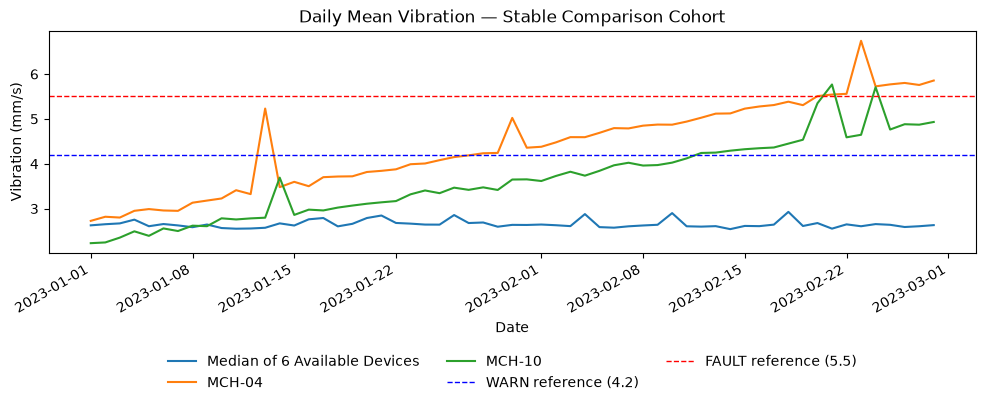

In [163]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.5))

stable_median = daily_vibration[stable_devices].reindex(expected_days).median(axis=1)

ax.plot(
    expected_days,
    stable_median,
    label="Median of 6 Available Devices"
)

ax.plot(
    expected_days,
    daily_vibration["MCH-04"].reindex(expected_days),
    label="MCH-04"
)

ax.plot(
    expected_days,
    daily_vibration["MCH-10"].reindex(expected_days),
    label="MCH-10"
)

# Reference thresholds
ax.axhline(
    4.2,
    color="blue",
    linestyle="--",
    linewidth=1,
    label="WARN reference (4.2)"
)

ax.axhline(
    5.5,
    color="red",
    linestyle="--",
    linewidth=1,
    label="FAULT reference (5.5)"
)

ax.set_title("Daily Mean Vibration — Stable Comparison Cohort")
ax.set_xlabel("Date")
ax.set_ylabel("Vibration (mm/s)")


ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.40),
    ncol=3,
    frameon=False
)

fig.autofmt_xdate()
plt.tight_layout()

plt.savefig(
    "../charts/daily_vibration_trend.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


## Device-Specific Temperature IQR Limits Based on OK Readings

This step calculates temperature limits separately for each device using the interquartile range (IQR) of its reading distribution.

### Procedure

The analytical data exclude duplicate records. Only normal-status readings are selected to form a statistical reference range for each device:

- `OK` — readings used to calculate statistical limits

Temperature readings are grouped by device identifier. The first quartile, third quartile, and IQR are calculated independently for each device, followed by lower and upper limits.

### Columns Used

- `device_id` — device identifier
- `temp_c` — recorded temperature
- `status` — status used to filter readings

### Variables and Statistical Measures

- `df_analysis` — analytical data after duplicate removal
- `Q1` — first quartile, the 25th percentile
- `Q3` — third quartile, the 75th percentile
- `IQR` — interquartile range, the difference between Q3 and Q1
- `lower_bound` — lower statistical temperature limit
- `upper_bound` — upper statistical temperature limit

### Formulas

**Interquartile range:**

`IQR = Q3 - Q1`

**Lower limit:**

`lower_bound = Q1 - 1.5 * IQR`

**Upper limit:**

`upper_bound = Q3 + 1.5 * IQR`

### Purpose

Device-specific limits account for differences in temperature distributions rather than applying a single pooled range to every device. They provide statistical reference ranges for subsequent analyses.

### Methodological Note

Limits are calculated from normal-status readings across the full available period; they are not an independent temporal baseline. They are distribution-derived statistical limits, not approved engineering standards, and cannot alone diagnose faults or establish operational problems. No readings were deleted and no original data were modified.


In [164]:

# Temperature IQR bounds for each device using OK readings

ok_temp = (
    df_analysis.loc[
        df_analysis["status"].str.strip().str.upper() == "OK"
    ]
    .groupby("device_id")["temp_c"]
)

device_temp_bounds = pd.DataFrame({
    "Q1": ok_temp.quantile(0.25),
    "Q3": ok_temp.quantile(0.75)
})

device_temp_bounds["IQR"] = (
    device_temp_bounds["Q3"] - device_temp_bounds["Q1"]
)

device_temp_bounds["lower_bound"] = (
    device_temp_bounds["Q1"] - 1.5 * device_temp_bounds["IQR"]
)

device_temp_bounds["upper_bound"] = (
    device_temp_bounds["Q3"] + 1.5 * device_temp_bounds["IQR"]
)

display(device_temp_bounds.round(2))


,Q1,Q3,IQR,lower_bound,upper_bound
device_id,,,,,
MCH-01,39.60,43.80,4.20,33.31,50.09
MCH-02,39.62,43.58,3.96,33.68,49.51
MCH-03,39.30,43.29,3.99,33.31,49.27
MCH-04,39.90,43.79,3.89,34.06,49.63
MCH-05,38.37,42.37,4.00,32.37,48.37
MCH-06,37.97,41.88,3.90,32.12,47.73
MCH-07,38.04,42.07,4.02,32.01,48.11
MCH-08,39.15,43.07,3.92,33.27,48.95
MCH-09,38.57,42.46,3.90,32.73,48.31


## Comparing Temperature Outliers Under Pooled and Device-Specific Limits

This additional comparison examines two ways of calculating statistical limits for temperature outlier detection. It assesses how pooled limits across all devices differ from independent device-level limits.

### Methods Compared

| Method | Reference Data Used to Calculate Limits |
|---|---|
| Pooled limits | Normal-status readings from all devices |
| Device-specific limits | Normal-status readings from each device independently |

**Reference status:** `OK`

### Procedure

The analytical data exclude fully duplicated records. Temperature readings labelled normal are selected as the reference. Q1, Q3, and IQR are calculated across the pooled reference readings, then lower and upper IQR limits are derived. These pooled limits are applied to all available temperature readings. Previously calculated device-specific limits are also applied. Outlier counts for both methods are grouped by device.

### Columns Used

| Column | Use |
|---|---|
| `status` | Select reference readings for limit calculation |
| `temp_c` | Calculate limits and test for outliers |
| `device_id` | Apply device-specific limits and group results |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data used in the comparison |
| `ok_temperature` | Pooled reference temperature readings |
| `global_ok_q1` | First quartile of pooled reference readings |
| `global_ok_q3` | Third quartile of pooled reference readings |
| `global_ok_iqr` | IQR of pooled reference readings |
| `global_ok_lower` | Pooled lower limit |
| `global_ok_upper` | Pooled upper limit |
| `device_temp_bounds` | Previously calculated independent device limits |
| `global_ok_temp_outlier` | Outlier flags under pooled limits |
| `device_ok_temp_outlier` | Outlier flags under device-specific limits |
| `temp_bound_comparison` | Comparison table |

### Programming Elements

| Element | Function |
|---|---|
| `loc` | Select reference readings |
| `str.strip()` | Remove surrounding whitespace |
| `str.upper()` | Standardize status labels |
| `quantile()` | Calculate Q1 and Q3 |
| `map()` | Associate each device with its own limits |
| `groupby()` | Group results by device |
| `sum()` | Count outliers |
| `count()` | Count non-missing temperatures |
| `sort_values()` | Sort comparison results |
| `display()` | Display the comparison table |

### Pooled-Limit Results

| Metric | Result |
|---|---:|
| Pooled lower limit | 32.945 |
| Pooled upper limit | 48.985 |
| Outliers under pooled limits | 133 |
| Outliers under device-specific limits | 89 |

**Temperature unit:** `°C`

### Comparison by Device

| Device | Valid Readings | Pooled Limits | Device Limits |
|---|---:|---:|---:|
| `MCH-04` | 705 | 70 | 51 |
| `MCH-10` | 704 | 34 | 10 |
| `MCH-09` | 705 | 6 | 6 |
| `MCH-01` | 706 | 5 | 4 |
| `MCH-03` | 706 | 4 | 4 |
| `MCH-02` | 590 | 4 | 4 |
| `MCH-05` | 587 | 2 | 2 |
| `MCH-06` | 705 | 2 | 2 |
| `MCH-08` | 587 | 2 | 2 |
| `MCH-07` | 702 | 2 | 2 |
| `MCH-11` | 589 | 1 | 1 |
| `MCH-12` | 704 | 1 | 1 |
| **Total** | **7,990** | **133** | **89** |

### Interpretation

The two methods identify different numbers of outliers within the same data: 133 with pooled limits and 89 with independent device limits. The largest differences occur in the two studied devices. Reference-population selection and limit calculation therefore affect outlier detection. Device characteristics should be considered when interpreting measurements rather than relying only on pooled limits.

### Key Findings

- Outlier results depend on how statistical limits are calculated.
- Pooled limits identify more outliers in this comparison.
- The largest differences occur in the studied pair.
- Outliers do not necessarily indicate incorrect measurements or mechanical faults.

### Methodological Note

Both methods use normal-status readings to derive limits, but apply those limits to all non-missing temperatures regardless of recorded status. Counts therefore represent readings outside the calculated limits, not only outliers within the reference subset. Fewer flags with device-specific limits do not establish that this method is universally more accurate. Results depend on the reference population and statistical rule. This is an exploratory comparison and cannot alone identify measurement errors or prove mechanical faults. No outliers were deleted and no original data were modified.


In [165]:

# Compare global and per-device OK-based temperature bounds

# Global IQR bounds using OK readings
ok_temperature = df_analysis.loc[
    df_analysis["status"].str.strip().str.upper() == "OK",
    "temp_c"
]

global_ok_q1 = ok_temperature.quantile(0.25)
global_ok_q3 = ok_temperature.quantile(0.75)

global_ok_iqr = global_ok_q3 - global_ok_q1

global_ok_lower = global_ok_q1 - 1.5 * global_ok_iqr
global_ok_upper = global_ok_q3 + 1.5 * global_ok_iqr

global_ok_temp_outlier = (
    (df_analysis["temp_c"] < global_ok_lower)
    | (df_analysis["temp_c"] > global_ok_upper)
)

# Per-device IQR bounds using OK readings
device_ok_temp_outlier = (
    (
        df_analysis["temp_c"]
        < df_analysis["device_id"].map(
            device_temp_bounds["lower_bound"]
        )
    )
    |
    (
        df_analysis["temp_c"]
        > df_analysis["device_id"].map(
            device_temp_bounds["upper_bound"]
        )
    )
)

# Compare the two methods
temp_bound_comparison = pd.DataFrame({
    "valid_readings": (
        df_analysis.groupby("device_id")["temp_c"].count()
    ),
    "global_ok_outliers": (
        global_ok_temp_outlier.groupby(
            df_analysis["device_id"]
        ).sum()
    ),
    "device_ok_outliers": (
        device_ok_temp_outlier.groupby(
            df_analysis["device_id"]
        ).sum()
    )
})

print("Global OK lower bound:", round(global_ok_lower, 3))
print("Global OK upper bound:", round(global_ok_upper, 3))

print("Global OK outliers:", int(global_ok_temp_outlier.sum()))
print("Per-device OK outliers:", int(device_ok_temp_outlier.sum()))

display(
    temp_bound_comparison.sort_values(
        "device_ok_outliers",
        ascending=False
    )
)


Global OK lower bound: 32.945
Global OK upper bound: 48.985
Global OK outliers: 133
Per-device OK outliers: 89


,valid_readings,global_ok_outliers,device_ok_outliers
device_id,,,
MCH-04,705,70,51
MCH-10,704,34,10
MCH-09,705,6,6
MCH-01,706,5,4
MCH-03,706,4,4
MCH-02,590,4,4
MCH-05,587,2,2
MCH-06,705,2,2
MCH-08,587,2,2


### Checking Whether Both Methods Flag the Same Outlier Records

This additional check compares the actual records classified as outliers under pooled and device-specific limits. It determines whether both methods flag the same readings or classify some records differently.

### Procedure

Using the previous classification results, readings flagged by both methods are identified, followed by readings flagged only by pooled limits and only by device limits. Total classification disagreements are counted, and the differences for one device are examined.

### Variables Used

| Variable | Description |
|---|---|
| `global_ok_temp_outlier` | Pooled-limit outlier flags |
| `device_ok_temp_outlier` | Device-specific outlier flags |
| `both_methods` | Readings flagged by both methods |
| `global_only` | Readings flagged only by pooled limits |
| `device_only` | Readings flagged only by device limits |
| `different_flags` | Readings classified differently |

### Programming Elements

| Element | Function |
|---|---|
| `&` | Identify readings satisfying both conditions |
| `~` | Negate a Boolean condition |
| `!=` | Identify classification differences |
| `sum()` | Count matching readings |
| `eq()` | Select a particular device |

### Results

| Metric | Readings |
|---|---:|
| Outliers under both methods | 88 |
| Outliers under pooled limits only | 45 |
| Outliers under device-specific limits only | 1 |
| Total differently classified readings | 46 |

### Device-Level Check

| Device | Classification Differences |
|---|---:|
| `MCH-06` | 2 |

### Interpretation

Both methods flag 88 readings, while 46 readings receive different classifications. One device has the same total outlier count under both methods even though the flagged records differ.

**Device examined:** `MCH-06`

Each method flags two readings for this device. However, one reading appears only under pooled limits and another only under device-specific limits. Equal outlier counts therefore do not necessarily mean identical flagged records.

### Methodological Note

The net difference between total outlier counts is 44 readings, while 46 readings differ in classification. This occurs because some readings are flagged by one method but not the other. The check uses existing classifications without recalculating limits or changing measurements. Disagreement does not prove measurement errors or actual mechanical faults. No records were deleted and no original data were modified.


In [166]:

# Verify overlap between the two outlier methods

both_methods = (
    global_ok_temp_outlier & device_ok_temp_outlier
)

global_only = (
    global_ok_temp_outlier & ~device_ok_temp_outlier
)

device_only = (
    device_ok_temp_outlier & ~global_ok_temp_outlier
)

different_flags = (
    global_ok_temp_outlier != device_ok_temp_outlier
)

print("Flagged by both:", int(both_methods.sum()))
print("Global only:", int(global_only.sum()))
print("Per-device only:", int(device_only.sum()))
print("Different classifications:", int(different_flags.sum()))

print(
    "MCH-06 differences:",
    int(
        (
            different_flags
            & df_analysis["device_id"].eq("MCH-06")
        ).sum()
    )
)


Flagged by both: 88
Global only: 45
Per-device only: 1
Different classifications: 46
MCH-06 differences: 2


### Analytical Note — The Effect of IQR Limits on Temperature Outlier Detection

Temperature outlier counts differ between pooled and independent device-specific limits. Both methods use normal-status readings as the statistical reference.

**Reference status:** `OK`

### Key Results

| Limit Method | Outliers |
|---|---:|
| Pooled limits from reference readings | 133 |
| Independent device-specific limits | 89 |
| Difference between totals | 44 |

### Devices with Changed Counts

| Device | Pooled Limits | Device Limits | Reduction |
|---|---:|---:|---:|
| `MCH-04` | 70 | 51 | 19 |
| `MCH-10` | 34 | 10 | 24 |
| `MCH-01` | 5 | 4 | 1 |

Counts do not change for the other nine devices. However, an unchanged count does not necessarily mean the same records are flagged.

### Interpretation

Device-specific limits reduce the total flagged count by 44. Most of the difference occurs in the two devices examined in the vibration analysis. The calculation method influences outlier detection, highlighting the need to consider differences in device measurement distributions.

### Key Findings

- Pooled limits identify more outliers.
- The largest differences occur in two specific devices.
- Classifications depend on how limits are calculated.
- Outliers do not necessarily imply incorrect measurements or mechanical faults.

### Methodological Note

Both methods derive limits from normal-status readings only, then apply them to every non-missing temperature regardless of status. This comparison differs from the earlier overall outlier check, which derived limits from all temperature readings. That earlier check identified 89 outliers under its own reference population. The three results must not be treated as outputs of one calculation method. A reduced count does not establish greater accuracy or operational suitability. Limits depend on the available distribution and are not independent engineering fault standards. No outliers were removed and no original data were modified.


## Analysis Requirements — Filtering, Sorting, and Pivot Tables

This section applies operations to explore, organize, and compare data by operating status, device, and site.

### Operations Used

- `Filtering` — select data using specified conditions
- `Sorting` — order data by selected values
- `Pivot Table` — summarize and compare groups

These operations use analytical data after full duplicate removal. No original data are modified.

### First Filter — Fault-Labelled Readings

This step extracts readings recorded with fault status to inspect the associated devices, sites, vibration, and temperature measurements.

### Status Used

| Operating Status | Code |
|---|---|
| Recorded fault status | `FAULT` |

### Procedure

Starting with duplicate-free analytical data, status text is temporarily trimmed and uppercased inside the filter condition. Matching readings are selected, along with relevant device, site, and measurement columns. The total count and first five records are displayed.

### Columns Used

| Column | Use |
|---|---|
| `status` | Identify the required status |
| `reading_at` | Show the recording timestamp |
| `device_id` | Identify the device |
| `site` | Identify the site |
| `vibration_mm_s` | Show vibration |
| `temp_c` | Show temperature |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data after full duplicate removal |
| `fault_readings` | Readings matching the selected status |

### Programming Elements

| Element | Function |
|---|---|
| `loc` | Filter rows and select columns |
| `str.strip()` | Remove surrounding whitespace |
| `str.upper()` | Standardize letters to uppercase |
| `==` | Match the required status |
| `len()` | Count matching readings |
| `print()` | Print the total |
| `head()` | Show the first five readings |
| `display()` | Display a results table |

### Results

| Metric | Result |
|---|---:|
| Readings labelled `FAULT` | 124 |
| Readings displayed for review | 5 |

### Interpretation

There are 124 readings with the selected status. The first five are shown to inspect their devices, sites, and measurements. This isolates fault-labelled readings for review without changing original records.

### Methodological Note

Filtering relies on recorded status labels. Text is temporarily standardized only for comparison inside the filter. A `FAULT` label does not prove an actual mechanical fault. The five displayed readings do not represent the entire matching subset. Other readings were not deleted and original data were not modified.


In [167]:

# Filter 1: Readings with FAULT status

fault_readings = df_analysis.loc[
    df_analysis["status"].str.strip().str.upper() == "FAULT",
    ["reading_at", "device_id", "site", "vibration_mm_s", "temp_c"]
]

print("FAULT readings:", len(fault_readings))

display(fault_readings.head())


FAULT readings: 124


,reading_at,device_id,site,vibration_mm_s,temp_c
302,2023-01-03 02:30:00,MCH-03,SLT,15.329,60.71
450,2023-01-04 03:10:00,MCH-07,NOR,8.434,47.82
922,2023-01-07 09:50:00,MCH-11,RIV,14.482,61.96
1552,2023-01-11 18:50:00,MCH-05,RIV,12.892,62.01
1743,2023-01-13 02:40:00,MCH-04,NOR,16.545,62.81


### Second Filter — Temperatures Above the 90th Percentile

This step extracts temperatures exceeding the 90th percentile of available analytical readings. The purpose is to identify higher-temperature readings and examine their associated status distribution.

### Threshold Used

| Metric | Value | Unit |
|---|---:|---|
| Percentile | 90 | `%` |
| Approximate temperature threshold | 45.151 | `°C` |

### Procedure

Using analytical data after full duplicate removal, the 90th percentile is calculated from non-missing temperatures. A strict comparison selects values above the threshold; values equal to it are excluded. Relevant timestamp, device, site, status, temperature, and vibration columns are selected. The matching count and first five records are displayed. Status text is temporarily standardized to count its distribution within the selected subset.

### Columns Used

| Column | Use |
|---|---|
| `temp_c` | Calculate the 90th percentile and filter readings |
| `reading_at` | Identify the recording timestamp |
| `device_id` | Identify the device |
| `site` | Identify the site |
| `status` | Examine status distribution |
| `vibration_mm_s` | Show associated vibration |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data after full duplicate removal |
| `temp_threshold` | Calculated temperature threshold |
| `high_temp_readings` | Readings exceeding the threshold |

### Programming Elements

| Element | Function |
|---|---|
| `quantile(0.90)` | Calculate the 90th percentile |
| `loc` | Filter readings and select columns |
| `>` | Select values strictly above the threshold |
| `copy()` | Create an independent filtered copy |
| `len()` | Count matching readings |
| `head()` | Show the first five readings |
| `str.strip()` | Remove whitespace from status labels |
| `str.upper()` | Standardize text for distribution counts |
| `value_counts()` | Count readings by status |

### Results

| Metric | Result |
|---|---:|
| Approximate temperature threshold | 45.151 |
| Matching readings | 799 |
| `OK` | 414 |
| `WARN` | 274 |
| `FAULT` | 111 |

**Temperature unit:** `°C`

### Interpretation

There are 799 readings above the temperature threshold. They span all three statuses, with `OK` accounting for the largest number: 414. Higher temperatures are therefore not confined to one operating status. The relationship between temperature and status should be examined without treating high temperature as independent proof of a mechanical fault.

### Methodological Note

The threshold is the 90th percentile of available analytical temperatures. Missing values were ignored for percentile calculation and were neither imputed nor changed. This is a relative statistical threshold, not an approved engineering fault limit. Status distribution does not establish causation between temperature and device condition. Status text was standardized only for counting, without changing the original column. The output includes the first five matches, total count, and status distribution. Other records were not deleted and original data were not modified.


In [168]:

# Filter 2: Temperature readings above the 90th percentile

temp_threshold = df_analysis["temp_c"].quantile(0.90)

high_temp_readings = df_analysis.loc[
    df_analysis["temp_c"] > temp_threshold,
    [
        "reading_at",
        "device_id",
        "site",
        "status",
        "temp_c",
        "vibration_mm_s"
    ]
].copy()

print("Temperature threshold:", round(temp_threshold, 3))
print("Filtered readings:", len(high_temp_readings))

display(high_temp_readings.head())

print("Operating status distribution:")
display(
    high_temp_readings["status"]
    .str.strip()
    .str.upper()
    .value_counts()
)


Temperature threshold: 45.151
Filtered readings: 799


,reading_at,device_id,site,status,temp_c,vibration_mm_s
74,2023-01-01 12:30:00,MCH-03,SLT,ok,45.35,3.144
79,2023-01-01 13:20:00,MCH-08,RIV,ok,45.16,2.973
214,2023-01-02 11:50:00,MCH-11,RIV,ok,46.14,2.882
302,2023-01-03 02:30:00,MCH-03,SLT,fault,60.71,15.329
371,2023-01-03 14:00:00,MCH-12,SLT,ok,45.22,3.035


Operating status distribution:


status
OK       414
WARN     274
FAULT    111
Name: count, dtype: int64

### Third Filter — Readings from the Selected Site

This step extracts readings from one site in the analytical dataset to inspect its devices and recorded measurements.

### Selected Site

| Site | Code |
|---|---|
| Selected site | `NOR` |

### Procedure

Using analytical data after full duplicate removal, site codes are temporarily trimmed and uppercased within the filter condition. Only readings from the selected site are extracted. Relevant device and measurement columns are selected, then the total matching count and first five records are displayed.

### Columns Used

| Column | Use |
|---|---|
| `site` | Identify the required site |
| `reading_at` | Show the recording timestamp |
| `device_id` | Identify the device |
| `temp_c` | Show temperature |
| `humidity_pct` | Show relative humidity |
| `vibration_mm_s` | Show vibration |
| `rpm` | Show rotational speed |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data after full duplicate removal |
| `nor_readings` | Readings matching the selected site |

### Programming Elements

| Element | Function |
|---|---|
| `loc` | Filter rows and select columns |
| `str.strip()` | Remove surrounding whitespace |
| `str.upper()` | Standardize letters to uppercase |
| `==` | Match the selected site code |
| `len()` | Count matching readings |
| `print()` | Print the total |
| `head()` | Show the first five readings |
| `display()` | Display a results table |

### Results

| Metric | Result |
|---|---:|
| Matching readings | 2,823 |
| Readings displayed for review | 5 |

### Interpretation

The selected site contains 2,823 readings. The first five are shown to inspect their devices and associated measurements. This isolates the site's data for independent review and enables further site- and device-level analysis.

### Methodological Note

The filter compares temporarily standardized site codes. The total covers all matching readings, but detailed display is limited to the first five, which do not necessarily represent the site's full distribution. Filtering does not remove other sites from the original data. No original data were modified.


In [169]:

# Filter 3: Readings recorded at NOR site

nor_readings = df_analysis.loc[
    df_analysis["site"].str.strip().str.upper() == "NOR",
    [
        "reading_at",
        "device_id",
        "temp_c",
        "humidity_pct",
        "vibration_mm_s",
        "rpm"
    ]
]

print("NOR readings:", len(nor_readings))

display(nor_readings.head())


NOR readings: 2823


,reading_at,device_id,temp_c,humidity_pct,vibration_mm_s,rpm
0,2023-01-01 00:10:00,MCH-01,35.90,45.6,2.859,1769.0
3,2023-01-01 00:40:00,MCH-04,38.09,33.1,2.413,1919.0
6,2023-01-01 01:10:00,MCH-07,37.29,36.9,2.266,1687.0
9,2023-01-01 01:40:00,MCH-10,37.26,42.3,2.233,1788.0
12,2023-01-01 02:10:00,MCH-01,36.66,43.0,2.789,1796.0


### Ranking Devices by Mean Vibration

This step calculates each device's mean vibration within its recorded site, then ranks devices from highest to lowest to compare measurement levels.

### Procedure

The analytical data exclude duplicates. Site names are standardized for consistent grouping. Readings are grouped by site and device, mean vibration is calculated, and results are sorted in descending order.

### Columns Used

- `site` — site associated with the device
- `device_id` — device identifier
- `vibration_mm_s` — measurement used to calculate the mean

### Variable Used

- `df_analysis` — analytical data after duplicate removal

### Programming Elements

- `groupby()` — group by site and device
- `mean()` — calculate device mean vibration
- `sort_values()` — sort descending by mean vibration

### Purpose

The ranking identifies devices with higher mean vibration and supports comparisons across devices and sites.

### Methodological Note

Means are based on each device's available readings. A mean alone does not describe time variation or within-device dispersion. Higher mean vibration does not independently establish a mechanical fault. No readings were deleted and no original data were modified.


In [170]:

# Sorting / Ranking: Devices by mean vibration (descending)

device_vibration_ranking = (
    df_analysis.assign(
        site_check=df_analysis["site"].str.strip().str.upper()
    )
    .groupby(["site_check", "device_id"])["vibration_mm_s"]
    .mean()
    .sort_values(ascending=False)
)

display(device_vibration_ranking)


site_check  device_id
NOR         MCH-04       4.386089
            MCH-10       3.643669
            MCH-01       3.157006
RIV         MCH-02       3.058236
SLT         MCH-03       2.927286
RIV         MCH-11       2.859289
            MCH-08       2.836806
SLT         MCH-12       2.803329
            MCH-09       2.557584
RIV         MCH-05       2.460899
NOR         MCH-07       2.250170
SLT         MCH-06       2.129290
Name: vibration_mm_s, dtype: float64

### Pivot Table — Mean Vibration by Site and Operating Status

This step creates a pivot table to calculate mean vibration by site and operating status. The aim is to compare vibration means across sites and recorded statuses.

### Procedure

The analytical data exclude duplicate records. Site names and status labels are standardized by trimming whitespace and converting letters to uppercase. A pivot table groups readings by site and status and calculates each group's mean vibration.

### Columns Used

- `site` — site associated with the device
- `status` — recorded operating status
- `vibration_mm_s` — measurement used to calculate the mean

### Variable Used

- `df_analysis` — analytical data after duplicate removal

### Programming Elements

- `str.strip()` — remove leading and trailing whitespace
- `str.upper()` — standardize text to uppercase
- `pivot_table()` — create a pivot table and group data
- `mean()` — calculate each group's mean vibration

### Purpose

The pivot table compares mean vibration across sites and shows differences between the statuses recorded within each site.

### Unavailable Values

A result may be unavailable when a group has no valid readings:

- `NaN` — no valid value is available to calculate a mean

This does not mean the mean vibration is zero. It indicates that the table cannot provide a calculated result for that group.

### Methodological Note

Means use the valid readings available for each site–status group. Group sizes may differ and should be considered when interpreting means. Different means across statuses do not by themselves establish mechanical faults. No original data were modified while creating the pivot table.


In [171]:

# Pivot Table: Mean vibration by site and operating status

pivot_vibration = (
    df_analysis.assign(
        site_check=df_analysis["site"].str.strip().str.upper(),
        status_check=df_analysis["status"].str.strip().str.upper()
    )
    .pivot_table(
        index="site_check",
        columns="status_check",
        values="vibration_mm_s",
        aggfunc="mean"
    )
    .round(3)
)

display(pivot_vibration)


status_check,FAULT,OK,WARN
site_check,,,
NOR,6.892,2.899,4.749
RIV,13.150,2.769,NaN
SLT,13.476,2.558,NaN


## Analytical Note — Interpreting Unavailable Pivot-Table Values

The pivot table contains unavailable mean vibration values for warning status at two sites. Status counts by site were examined to determine why these groups have no means.

### Status Examined

- `WARN` — warning status recorded in the data

### Key Results

| Site | Warning Records | Pivot-Table Result |
|---|---:|---|
| `NOR` | 482 | Mean available |
| `RIV` | 0 | `NaN` |
| `SLT` | 0 | `NaN` |

### Interpretation

Warning-status records occur only at the first site. The other two sites have no readings with this status. Their unavailable means therefore arise from the complete absence of warning-status records, rather than records with missing vibration values.

### Meaning of an Unavailable Value

- `NaN` — no mean can be calculated for the group

This is not an error in pivot-table construction and does not mean that mean vibration equals zero. In this case it indicates that the requested group contains no records.

### Related Programming Elements

- `pivot_table()` — calculate mean vibration by site and status
- `NaN` — represent an unavailable table result

### Methodological Note

The unavailable values were interpreted after verifying counts for each site–status group. A group with no records cannot have a calculated vibration mean. These values were retained rather than replaced with zero or estimates. No original data were modified and no unavailable values were imputed.


## Supporting Visualizations

This section creates additional charts to support exploratory data analysis. The charts describe measurement distributions and compare levels across sites and devices using analytical data after duplicate removal.

### Variable Used

- `df_analysis` — analytical data after duplicate removal

### Methodological Note

These charts are descriptive and exploratory. They do not independently diagnose faults or apply approved engineering limits.

### Temperature Reading Distribution

A histogram displays available temperature readings to show their spread and most frequent ranges.

#### Procedure

Temperature readings are taken after duplicate removal. Missing values are excluded from the plotting data. Readings are divided into thirty bins, and the chart shows the number of readings in each bin.

#### Column Used

- `temp_c` — recorded temperature

#### Elements Used

- `Histogram` — display a value distribution
- `bins` — specify the number of histogram intervals

#### Chart Settings

| Setting | Value |
|---|---:|
| Number of bins | 30 |
| Missing values | Excluded from the chart |

#### Purpose

The chart helps explain temperature distribution, concentration, and spread, including the ranges where measurements occur most frequently.

#### Methodological Note

Only available temperatures are plotted. Missing values are excluded from the chart without imputation or estimated replacements. Distribution shape alone is insufficient to identify an operational problem or mechanical fault. No original data were modified.


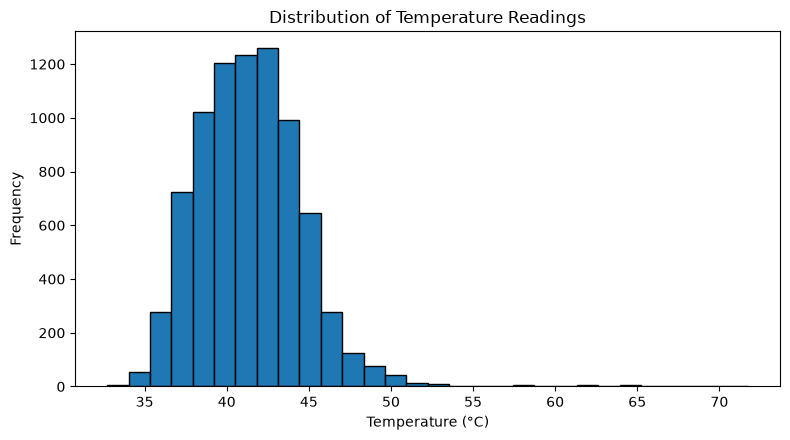

In [172]:

# Temperature distribution histogram

fig, ax = plt.subplots(figsize=(8, 4.5))

df_analysis["temp_c"].dropna().plot(
    kind="hist",
    bins=30,
    ax=ax,
    edgecolor="black"
)

ax.set_title("Distribution of Temperature Readings")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Frequency")

plt.tight_layout()

plt.savefig(
    "../charts/temperature_distribution.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


## Mean Vibration by Site

This step calculates mean vibration for each recorded site, compares the three means, and identifies the site with the highest result.

### Procedure

The analytical data exclude full duplicates. Site names are standardized by trimming whitespace and converting letters to uppercase. Readings are grouped by site and mean vibration is calculated. A bar chart displays the means for visual comparison.

### Columns Used

| Column | Use |
|---|---|
| `site` | Identify the recorded site |
| `vibration_mm_s` | Calculate mean vibration |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data after full duplicate removal |
| `site_check` | Temporary standardized site column used for grouping |
| `site_vibration` | Calculated mean vibration for each site |

### Programming Elements

| Element | Function |
|---|---|
| `assign()` | Create a temporary standardized site column |
| `str.strip()` | Remove surrounding whitespace |
| `str.upper()` | Standardize letters to uppercase |
| `groupby()` | Group readings by site |
| `mean()` | Calculate mean vibration |
| `Bar Chart` | Compare means visually |
| `savefig()` | Save the chart |

### Results

| Site | Mean Vibration |
|---|---:|
| `NOR` | 3.36 |
| `RIV` | 2.80 |
| `SLT` | 2.60 |

**Unit:** `mm/s`

### Interpretation

Mean vibration differs across the three sites, with the first site in the table recording the highest value. However, a site's mean represents available readings from all its devices. It does not imply that every device has equally high or similar vibration levels. Interpreting the overall mean therefore requires device-level review alongside site comparisons.

### Key Findings

- Mean vibration varies across sites.
- The first site has the highest mean.
- The site mean cannot be generalized to all its devices.
- Independent device analysis helps explain the overall result.

### Methodological Note

Means use available readings after full duplicate removal. `mean()` ignores missing vibration values. Valid-reading counts may differ across devices and sites. Higher mean vibration alone does not establish mechanical faults or explain why readings are elevated. Means were calculated without changing original data.

### Additional Analysis

The effect of two specific devices on the site's overall mean vibration is documented separately with its code and results. No records were deleted and no original data were modified while creating this chart.


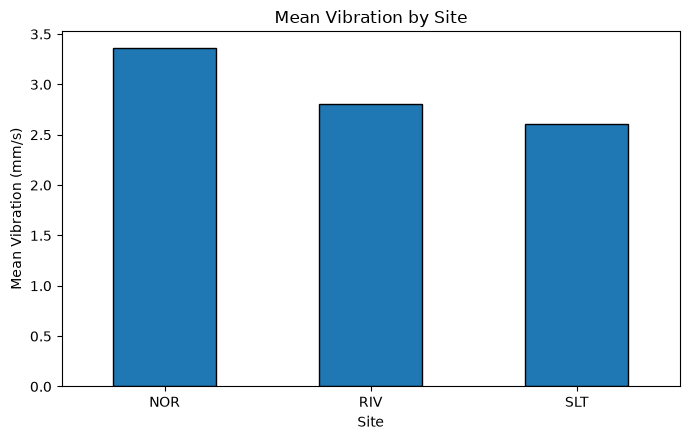

In [173]:
# Mean vibration by site

site_vibration = (
    df_analysis.assign(
        site_check=df_analysis["site"].str.strip().str.upper()
    )
    .groupby("site_check")["vibration_mm_s"]
    .mean()
)

fig, ax = plt.subplots(figsize=(7, 4.5))

site_vibration.plot(
    kind="bar",
    ax=ax,
    edgecolor="black"
)

ax.set_title("Mean Vibration by Site")
ax.set_xlabel("Site")
ax.set_ylabel("Mean Vibration (mm/s)")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(
    "../charts/mean_vibration_by_site.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

### Relationship Between Temperature and Vibration

A scatter plot examines the relationship between temperature and vibration in the analytical data. It shows the direction of the association and the spread and clustering of readings.

#### Procedure

The analytical data exclude duplicates. Temperature and vibration readings are selected. Rows missing either value are excluded only from plotting. A scatter plot then visualizes the two measurements.

#### Columns Used

- `temp_c` — recorded temperature
- `vibration_mm_s` — recorded vibration

#### Variable Used

- `df_analysis` — analytical data after duplicate removal

#### Elements Used

- `Scatter Plot` — display the relationship between two variables
- `Pearson Correlation` — measure the strength and direction of a linear relationship

#### Purpose

The chart helps examine the direction of the temperature–vibration relationship and observe how readings spread or cluster across ranges. It supports visual interpretation of the previously calculated correlations.

#### General Interpretation

An upward pattern suggests a positive association. A point cloud without a clear direction may suggest a weak linear relationship. Relatively high readings can affect the distribution's appearance and the observed association.

### Methodological Note

Only readings with valid values for both variables are plotted. Missing values were excluded from the chart only, without imputation or modification of original data. The chart describes the observed relationship but does not establish causation and cannot independently diagnose mechanical faults. The dataset is synthetic, and patterns may reflect how it was generated.


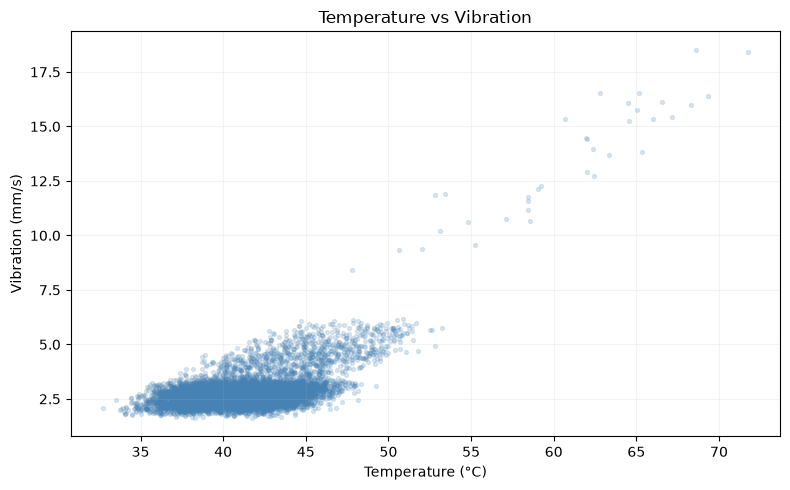

In [174]:

# Temperature vs Vibration Scatter Plot

scatter_data = df_analysis[
    ["temp_c", "vibration_mm_s"]
].dropna()

fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    scatter_data["temp_c"],
    scatter_data["vibration_mm_s"],
    alpha=0.18,
    s=8,
    color="steelblue"
)

ax.grid(True, alpha=0.15)

ax.set_title("Temperature vs Vibration")
ax.set_xlabel("Temperature (°C)")
ax.set_ylabel("Vibration (mm/s)")

plt.tight_layout()

plt.savefig(
    "../charts/temperature_vs_vibration_scatter.png",
    dpi=160,
    bbox_inches="tight"
)

plt.show()


### Analytical Note — Interpreting the Scatter Plot

The scatter plot shows a positive temperature–vibration association in the analytical data: vibration tends to rise with temperature.

#### Main Observations

- Most readings cluster within relatively close ranges.
- Some readings are relatively high on both variables.
- Higher readings may influence the overall correlation coefficient.
- The visual direction agrees with the earlier correlation analysis.

#### Previous Correlation Result

| Metric | Correlation Coefficient |
|---|---:|
| Temperature and vibration | 0.62 |

#### Interpretation

The positive direction indicates a linear association within the examined data. Relatively high readings may affect the calculated coefficient. The visual pattern supports the previous statistical result but cannot determine why the relationship occurs.

#### Methodological Note

The plot describes the observed association. Statistical correlation does not establish causation, and this chart alone cannot diagnose actual mechanical faults. The synthetic dataset's patterns may reflect its generation process. No original data were modified.


### Data Visualization

Four charts were created to support exploratory analysis. They describe measurement distributions, compare vibration across sites, and examine temporal changes and relationships between variables.

#### Charts Created

| Filename | Purpose |
|---|---|
| `temperature_distribution.png` | Show the distribution and spread of temperatures |
| `mean_vibration_by_site.png` | Compare mean vibration across the three sites |
| `daily_vibration_trend.png` | Show daily vibration trends against the reference group |
| `temperature_vs_vibration_scatter.png` | Show temperature–vibration association in a scatter plot |

### Chart Descriptions

**1 — Temperature distribution**

Displays temperature readings to help understand their spread and concentration in the examined data.

**2 — Mean vibration by site**

Displays mean vibration for the three recorded sites:

| Site | Code |
|---|---|
| First site | `NOR` |
| Second site | `RIV` |
| Third site | `SLT` |

This comparison identifies differences in site-level mean vibration.

**3 — Daily vibration trend**

Displays daily mean vibration for the two studied devices and the median daily means of a fixed six-device reference group with daily vibration means available throughout the study period. Two horizontal reference lines support visual comparison with the status-consistency thresholds.

**4 — Temperature and vibration relationship**

The scatter plot displays the spread of readings and the observed positive association. It supports interpretation of the linear correlation without establishing causation.

#### Daily Vibration Chart Colors

| Color | Line Style | Meaning | Device or Value |
|---|---|---|---|
| Blue | Solid | Median daily means of the reference group | 6 devices |
| Orange | Solid | Daily mean vibration of the first device | `MCH-04` |
| Green | Solid | Daily mean vibration of the second device | `MCH-10` |
| Blue | Dashed | First reference threshold | `4.2` |
| Red | Dashed | Second reference threshold | `5.5` |

**Vibration unit:** `mm/s`

#### Reference-Threshold Clarification

These thresholds were used earlier to compare operating statuses with individual vibration readings:

| Threshold | Value | Boundary Between Statuses |
|---|---:|---|
| First | 4.2 | `OK` / `WARN` |
| Second | 5.5 | `WARN` / `FAULT` |

The daily trend chart instead displays device daily means and the median of reference-device daily means. Reference lines are for visual comparison only. Crossing a line does not automatically change the operating-status classification of a device or day.

### Methodological Note

Charts use available data after duplicate removal. Daily coverage does not guarantee that all expected intraday readings exist. Reference thresholds are specific to this project's consistency check and are not approved engineering standards for mechanical fault diagnosis. The charts describe patterns but do not establish why measurements change or independently confirm faults. No original data were modified when creating these charts.


## Checking the Effect of Two Devices on Site Mean Vibration

This additional comparison examines how readings from two selected devices contribute to the overall mean vibration of one site.

### Site and Devices Under Study

| Item | Identifier |
|---|---|
| Site | `NOR` |
| First device | `MCH-04` |
| Second device | `MCH-10` |

### Procedure

The analytical data exclude fully duplicated records. After temporarily standardizing the site code, readings from the selected site are extracted. Mean vibration is calculated using all available site readings. A temporary subset excludes the two studied devices, and the mean of the remaining devices' readings is calculated. The two means are compared to understand the contribution of the selected devices.

### Columns Used

| Column | Use |
|---|---|
| `site` | Select the site under study |
| `device_id` | Identify the two devices excluded from the comparison |
| `vibration_mm_s` | Calculate mean vibration |

### Variables Used

| Variable | Description |
|---|---|
| `df_analysis` | Analytical data after full duplicate removal |
| `nor_data` | All readings from the selected site |
| `nor_without_two` | Site readings excluding the two devices for comparison |
| `nor_mean_all` | Mean vibration across all site devices |
| `nor_mean_without` | Mean vibration after excluding the two devices |

### Programming Elements

| Element | Function |
|---|---|
| `loc` | Filter readings using the specified conditions |
| `str.strip()` | Remove surrounding whitespace |
| `str.upper()` | Standardize the site code |
| `isin()` | Identify readings associated with the two devices |
| `~` | Negate membership to exclude those readings |
| `mean()` | Calculate mean vibration |
| `round()` | Round displayed results |

### Results

| Comparison | Mean Vibration |
|---|---:|
| All site devices | 3.3592 |
| Excluding the two devices | 2.7033 |

**Unit:** `mm/s`

### Interpretation

Mean vibration decreases when the studied devices are excluded. Their readings therefore contribute to raising the site's arithmetic mean. A site mean does not necessarily describe each device's individual vibration level. Device-level analysis helps explain the aggregate more accurately.

### Key Findings

- Mean vibration falls after excluding the two devices.
- Specific devices influence the site's overall mean.
- A higher mean cannot be generalized to all devices at the site.
- The comparison clarifies device contributions to the aggregate.

### Methodological Note

The two devices are excluded from calculation only for analytical comparison. No records are deleted and original values are unchanged. Means use all available non-missing vibration readings in each group. Valid-reading counts may differ across devices and groups, so the overall mean is reading-weighted rather than giving each device equal weight. This comparison describes an arithmetic contribution; it does not establish mechanical faults or the cause of higher vibration.


In [175]:

# Verify NOR mean vibration excluding two devices

nor_data = df_analysis.loc[
    df_analysis["site"].str.strip().str.upper() == "NOR"
]

nor_without_two = nor_data.loc[
    ~nor_data["device_id"].isin(["MCH-04", "MCH-10"])
]

nor_mean_all = nor_data["vibration_mm_s"].mean()
nor_mean_without = nor_without_two["vibration_mm_s"].mean()

print("NOR - All devices:", round(nor_mean_all, 4))
print("NOR - Excluding MCH-04 and MCH-10:", round(nor_mean_without, 4))


NOR - All devices: 3.3592
NOR - Excluding MCH-04 and MCH-10: 2.7033


## Data-Quality and Analytical-Indicator Register

This step creates a unified register documenting data-quality checks and key analytical indicators. It organizes findings and makes issues or cases requiring follow-up easier to review. The table includes each check, its count, and an assessment status.

### Procedure

Previous findings are grouped by source and analytical purpose. The first group covers raw-data quality: duplicates, missing values, valid dates, and formatting consistency. The second covers time gaps and estimated potentially unrecorded readings. The third contains analytical indicators of status consistency and device vibration trends. Results are combined into one reviewable register.

### Data Sources

- `df` — raw data used for quality checks
- `df_analysis` — analytical data after duplicate removal

### Raw-Data Quality Checks

- Duplicate records — check for identical rows
- Date validity — examine date and time values
- RPM formatting — check measurement formatting
- Site names — check category consistency
- Operating statuses — check category consistency
- Missing values — count unavailable cells

### Methodological Clarification — Status Formatting

Status text is checked against the base forms present in the raw data before cleaning. The main raw status labels use lowercase letters.

### Checking and Standardization

| Stage | Processing | Purpose |
|---|---|---|
| Raw-data check | `str.strip().str.lower()` | Detect deviations from the base forms |
| Cleaning | `str.strip().str.upper()` | Standardize labels to the final format |

### Formatting Results

| Metric | Records |
|---|---:|
| Raw records | 8,020 |
| Records matching base forms | 8,008 |
| Records with formatting differences | 12 |

### Methodological Note

The quality register counts formatting differences by comparing raw values with their lowercase base forms. Formal cleaning standardizes labels to uppercase. These different case conversions serve different purposes and do not conflict. They do not establish the devices' actual operating condition. Source data were not modified during this consistency check.

### Time Gaps

Gap-check results estimate potentially unrecorded readings from inter-reading intervals after device–timestamp duplicates are excluded from the time calculation.

### Analytical Indicators

- Status consistency — compare labels with reference vibration thresholds
- Vibration trends — identify devices whose slopes exceed the selected analytical threshold

### Assessment Statuses

| Status | Meaning |
|---|---|
| `Passed` | Check passed |
| `Needs Review` | Review required |
| `Retained` | Data retained |
| `Estimated` | Estimated result |
| `Consistent` | Consistent with tested conditions |
| `Further Review` | Additional review required |

### Programming Element

- `DataFrame` — organize checks in a unified table

### Thresholds and Assumptions

| Indicator | Value | Unit |
|---|---:|---|
| First vibration threshold | 4.2 | `mm/s` |
| Second vibration threshold | 5.5 | `mm/s` |
| Daily vibration slope threshold | 0.02 | `mm/s/day` |
| Assumed interval between readings | 2 | hours |

### Purpose of the Register

The register documents data-quality findings while distinguishing detected issues from analytical indicators. It identifies passed checks and cases needing further review and provides an organized reference for the final project.

### Methodological Note

Estimated unrecorded readings assume a reading every two hours. The resulting count is a time-based estimate, not a confirmed number of missing records. Vibration and slope thresholds are selected analytical references, not approved mechanical fault-diagnosis standards. Assessment labels describe specific checks, not a comprehensive judgment of data quality or equipment health. No records were deleted, missing values processed, or original data modified while creating the register.


In [176]:

# ==================================================
# Data Quality Log and Analytical Indicators
# ==================================================

value_cols = [
    "temp_c",
    "humidity_pct",
    "vibration_mm_s",
    "rpm"
]

# --------------------------------------------------
# 1. Raw Data Quality Checks
# --------------------------------------------------

exact_duplicates = int(df.duplicated().sum())

invalid_datetime = int(
    pd.to_datetime(df["reading_at"], errors="coerce").isna().sum()
)

rpm_raw = df["rpm"].astype("string")

rpm_formatting_count = int(
    rpm_raw.str.contains(",", regex=False, na=False).sum()
)

rpm_normalized = pd.to_numeric(
    rpm_raw.str.replace(",", "", regex=False),
    errors="coerce"
)

invalid_rpm = int(
    (df["rpm"].notna() & rpm_normalized.isna()).sum()
)

site_raw = df["site"].astype("string")
site_normalized = site_raw.str.strip().str.upper()

inconsistent_site = int(
    (site_raw != site_normalized).sum()
)

status_raw = df["status"].astype("string")
status_normalized = status_raw.str.strip().str.lower()

inconsistent_status = int(
    (status_raw != status_normalized).sum()
)

missing_measurements = int(
    df[value_cols].isna().sum().sum()
)

# --------------------------------------------------
# 2. Estimated Missing Readings
# --------------------------------------------------

time_data_unique = (
    df.assign(
        reading_datetime=pd.to_datetime(
            df["reading_at"],
            errors="coerce"
        )
    )
    .drop_duplicates(
        subset=["device_id", "reading_datetime"]
    )
    .sort_values(["device_id", "reading_datetime"])
    .copy()
)

time_data_unique["time_gap"] = (
    time_data_unique
    .groupby("device_id")["reading_datetime"]
    .diff()
)

expected_interval = pd.Timedelta(hours=2)

time_data_unique["estimated_missing"] = (
    (
        time_data_unique["time_gap"] / expected_interval - 1
    )
    .where(
        time_data_unique["time_gap"] > expected_interval,
        0
    )
)

estimated_missing_slots = int(
    time_data_unique["estimated_missing"].sum()
)

# --------------------------------------------------
# 3. Analytical Consistency Checks
# --------------------------------------------------

analysis_status = (
    df_analysis["status"]
    .astype("string")
    .str.strip()
    .str.upper()
)

vibration_rule = pd.cut(
    df_analysis["vibration_mm_s"],
    bins=[-np.inf, 4.2, 5.5, np.inf],
    labels=["OK", "WARN", "FAULT"]
).astype("string")

valid_vibration = (
    df_analysis["vibration_mm_s"].notna()
    & analysis_status.notna()
)

status_vibration_mismatches = int(
    (
        analysis_status[valid_vibration]
        != vibration_rule[valid_vibration]
    ).sum()
)

vibration_slope_threshold = 0.02

devices_with_rising_vibration = int(
    (
        trend_summary["vibration_slope_per_day"]
        > vibration_slope_threshold
    ).sum()
)

# --------------------------------------------------
# 4. Build Data Quality Log
# --------------------------------------------------

quality_log = pd.DataFrame([
    {
        "Quality Check": "Exact Duplicates",
        "Count": exact_duplicates,
        "Status": "Needs Review" if exact_duplicates > 0 else "Passed"
    },
    {
        "Quality Check": "Invalid Datetime",
        "Count": invalid_datetime,
        "Status": "Needs Review" if invalid_datetime > 0 else "Passed"
    },
    {
        "Quality Check": "RPM Values Requiring Formatting",
        "Count": rpm_formatting_count,
        "Status": "Needs Review" if rpm_formatting_count > 0 else "Passed"
    },
    {
        "Quality Check": "Non-numeric RPM After Normalization",
        "Count": invalid_rpm,
        "Status": "Needs Review" if invalid_rpm > 0 else "Passed"
    },
    {
        "Quality Check": "Inconsistent Site",
        "Count": inconsistent_site,
        "Status": "Needs Review" if inconsistent_site > 0 else "Passed"
    },
    {
        "Quality Check": "Inconsistent Status",
        "Count": inconsistent_status,
        "Status": "Needs Review" if inconsistent_status > 0 else "Passed"
    },
    {
        "Quality Check": "Missing Measurements",
        "Count": missing_measurements,
        "Status": "Retained" if missing_measurements > 0 else "Passed"
    },
    {
        "Quality Check": "Estimated Missing Readings",
        "Count": estimated_missing_slots,
        "Status": "Estimated"
    },
    {
        "Quality Check": "Status-Vibration Mismatches",
        "Count": status_vibration_mismatches,
        "Status": (
            "Consistent"
            if status_vibration_mismatches == 0
            else "Needs Review"
        )
    },
    {
        "Quality Check": "Devices with Rising Vibration",
        "Count": devices_with_rising_vibration,
        "Status": (
            "Further Review"
            if devices_with_rising_vibration > 0
            else "No Devices Flagged"
        )
    }
])

display(quality_log)


,Quality Check,Count,Status
0,Exact Duplicates,20,Needs Review
1,Invalid Datetime,0,Passed
2,RPM Values Requiring Formatting,12,Needs Review
3,Non-numeric RPM After Normalization,0,Passed
4,Inconsistent Site,12,Needs Review
5,Inconsistent Status,12,Needs Review
6,Missing Measurements,40,Retained
7,Estimated Missing Readings,468,Estimated
8,Status-Vibration Mismatches,0,Consistent
9,Devices with Rising Vibration,2,Further Review


### Analytical Note — Data-Quality Register Summary

The register identifies duplication, formatting, and missing-value issues. It also documents time-gap findings and analytical indicators involving status consistency and device vibration trends.

### 1. Data-Quality Results

| Check | Cases Detected |
|---|---:|
| Duplicate records | 20 |
| RPM values needing formatting standardization | 12 |
| Site-name formatting differences | 12 |
| Operating-status formatting differences | 12 |
| Missing measurement cells | 40 |
| Invalid dates | 0 |
| RPM values not convertible to numeric after standardization | 0 |

### Quality Interpretation

Duplicates and formatting differences occur in values and categories. Missing measurement cells must also be considered in subsequent analysis. No invalid dates or RPM values that remain unconvertible after formatting standardization were found.

### 2. Time-Gap Results

| Metric | Result |
|---|---:|
| Potentially unrecorded readings | 468 |
| Assumed interval in hours | 2 |

### Time-Gap Interpretation

Some intervals may contain unrecorded readings. Their count was estimated assuming one reading every two hours. This is a conditional estimate, not proof that exactly that many records were lost.

### 3. Analytical-Indicator Results

| Indicator | Result |
|---|---:|
| Status disagreements with vibration thresholds | 0 |
| Devices exceeding the vibration slope threshold | 2 |

### Analytical Slope Threshold

| Indicator | Value | Unit |
|---|---:|---|
| Daily vibration slope threshold | 0.02 | `mm/s/day` |

### Methodological Clarification — Selecting the Slope Threshold

An analytical threshold identifies devices whose upward daily mean vibration slope exceeds the selected value.

### Comparison Criterion

| Indicator | Value | Unit |
|---|---:|---|
| Selected slope threshold | 0.02 | `mm/s/day` |
| Devices exceeding the threshold | 2 | devices |

### Matching Devices

| Device | Daily Vibration Slope |
|---|---:|
| `MCH-04` | 0.0540 |
| `MCH-10` | 0.0487 |

### Interpretation

Both studied devices exceed the selected analytical threshold; the remaining devices do not during this period. The check uses linear slopes calculated from daily mean vibration for each device.

### Methodological Note

The threshold is used for exploratory screening and to distinguish more pronounced upward trends. It is not an approved engineering limit or an independent fault-diagnosis standard. The number of matching devices depends on the chosen threshold. Exceeding it does not establish a mechanical fault or its operational cause. Original measurements were not modified.

### Analytical-Indicator Interpretation

The status-consistency test finds no disagreements among valid readings under the selected reference thresholds. Two devices exceed the chosen vibration slope threshold. These patterns warrant additional review but do not establish faults or explain the operational causes of measurement changes.

### Key Findings

- Duplicates, formatting differences, and missing values are present.
- No invalid dates were detected.
- No RPM values remain unconvertible after formatting standardization.
- Time gaps yield an estimate of potentially unrecorded readings.
- The status-consistency test shows no disagreements.
- Two devices exceed the chosen upward vibration slope threshold.

### Methodological Note

Data-quality findings are separated from analytical indicators. Potentially unrecorded readings are estimates under a specific time assumption. Vibration and slope thresholds are analytical references only, not approved engineering fault standards. These findings do not establish specific operational causes or actual device faults. Results were documented without changing raw data or imputing missing values while constructing the register.


## Analytical Limitations and Conclusions

This section explains the methodological limits that should guide interpretation. It distinguishes observed statistical findings from conclusions the data alone cannot establish.

### Nature of the Data

The study uses a synthetic dataset prepared for training and analysis. The readings are not actual operating records from a real factory or documented industrial equipment.

### Limits of Engineering Assessment

No independent engineering specifications define safe operating ranges for each sensor or device. The thresholds used here are therefore not approved engineering standards for fault diagnosis.

### Time Gaps

Potentially unrecorded readings were estimated by assuming one reading every two hours per device. The estimate depends on a regular recording schedule and is not a confirmed missing-reading count. The actual schedule must be verified before treating the gaps as confirmed data loss.

### Operating-Status Consistency

Consistency checks show agreement between operating-status labels and the vibration thresholds used in the analysis. Agreement does not establish how labels were generated or whether these thresholds actually determined them.

**Related column:**

- `status` — recorded operating-status label

### Outliers

Outliers are identified using statistical limits derived from the data. They are indicators warranting review, not necessarily measurement errors, and do not independently prove mechanical faults.

### Correlations and Time Trends

Correlation coefficients and time slopes describe observed measurement patterns and relationships. They are descriptive statistical results and do not establish causation. Upward trends alone are insufficient to identify why measurements changed.

### Overall Conclusion

The project helps explain data quality, detect patterns and unusual values, and identify cases deserving further review. Findings must be interpreted within the limits of the data, assumptions, and statistical methods. They cannot alone establish actual faults or determine their causes.
